# 04 — sakai224_full post-training audit and embeddings

Questo notebook parte esclusivamente dagli artefatti persistenti della run ufficiale
`sakai224_full_v1`.

Obiettivi principali:

1. audit read-only della run finale;
2. verifica di `FINAL`, `LATEST`, `BEST` e metriche;
3. caricamento del VAE ufficiale epoch 100;
4. ricostruzioni qualitative;
5. estrazione degli embedding deterministici

\[
\mu_\phi(x)\in\mathbb{R}^{512};
\]

6. esportazione canonica degli embedding full con row-map, split e SHA-256;
7. ramo full Python/PyTorch per analisi Sakai-like;
8. ramo comparativo comune in C con mini75, mini112 e mini224_1000.

Il modello scientifico principale è `final.pt`, corrispondente a 100 epoche completate.
`best.pt` rimane un checkpoint diagnostico.

In [1]:
# ============================================================
# NOTEBOOK 04 — FINAL RUN PERSISTENCE AUDIT
# STEP 04-A0
#
# READ ONLY.
#
# Does NOT load the neural model yet.
# Does NOT modify any official artifact.
# ============================================================

from pathlib import Path

import csv
import hashlib
import importlib.util
import json
import os
import platform
import tempfile

import torch


# ============================================================
# PORTABLE ROOT CONTRACT
# ============================================================

PROJECT_ROOT_ENV = os.environ.get(
    "GRAVITYSPY_PROJECT_ROOT"
)

LOCAL_RUNTIME_ROOT_ENV = os.environ.get(
    "GRAVITYSPY_LOCAL_RUNTIME_ROOT"
)


try:
    IN_COLAB = (
        importlib.util.find_spec(
            "google.colab"
        )
        is not None
    )
except ModuleNotFoundError:
    IN_COLAB = False


if LOCAL_RUNTIME_ROOT_ENV is not None:

    LOCAL_RUNTIME_ROOT = Path(
        LOCAL_RUNTIME_ROOT_ENV
    )

    if not LOCAL_RUNTIME_ROOT.is_absolute():

        raise ValueError(
            "GRAVITYSPY_LOCAL_RUNTIME_ROOT must be an absolute path."
        )

elif IN_COLAB:

    LOCAL_RUNTIME_ROOT = Path(
        "/content"
    )

else:

    LOCAL_RUNTIME_ROOT = Path(
        tempfile.gettempdir()
    )


if not LOCAL_RUNTIME_ROOT.is_absolute():

    raise RuntimeError(
        "LOCAL_RUNTIME_ROOT must resolve to an absolute path."
    )


if PROJECT_ROOT_ENV is not None:

    PROJECT_ROOT = Path(
        PROJECT_ROOT_ENV
    )

    if not PROJECT_ROOT.is_absolute():

        raise ValueError(
            "GRAVITYSPY_PROJECT_ROOT must be an absolute path."
        )

elif IN_COLAB:

    DRIVE_MOUNT_POINT = Path(
        "/content/drive"
    )

    if not (
        DRIVE_MOUNT_POINT
        / "MyDrive"
    ).is_dir():

        from google.colab import drive

        drive.mount(
            str(
                DRIVE_MOUNT_POINT
            )
        )

    PROJECT_ROOT = (
        DRIVE_MOUNT_POINT
        / "MyDrive"
        / "TESI_SAKAI2022"
    )

else:

    raise RuntimeError(
        "GRAVITYSPY_PROJECT_ROOT must be set to an absolute path outside Colab."
    )


# ============================================================
# PERSISTENT PATHS
# ============================================================

SAKAI224_ROOT = (
    PROJECT_ROOT
    / "sakai224_full"
)

RUNS_ROOT = (
    SAKAI224_ROOT
    / "runs"
)

OFFICIAL_RUN_DIR = (
    RUNS_ROOT
    / "sakai224_full_v1"
)

OLD_PARTIAL_DIR = (
    RUNS_ROOT
    / "sakai224_full_v1.partial"
)


FINAL_PATH = (
    OFFICIAL_RUN_DIR
    / "final.pt"
)

LATEST_PATH = (
    OFFICIAL_RUN_DIR
    / "latest.pt"
)

BEST_PATH = (
    OFFICIAL_RUN_DIR
    / "best.pt"
)

METRICS_PATH = (
    OFFICIAL_RUN_DIR
    / "metrics.csv"
)

RUN_CONFIG_PATH = (
    OFFICIAL_RUN_DIR
    / "run_config.json"
)

RUNTIME_SESSIONS_PATH = (
    OFFICIAL_RUN_DIR
    / "runtime_sessions.jsonl"
)


# ============================================================
# FROZEN OFFICIAL HASHES
# ============================================================

EXPECTED_LATEST_SHA256 = (
    "ef22aa31a87f701d3a101ba358c7a602"
    "a03a874cd8882108fc1ef82c3dded96d"
)

EXPECTED_BEST_SHA256 = (
    "8d96639cdbac928ae8e4c0a89a30fd6"
    "ddb48e8985bd7f0f9f86767801788f84a"
)

EXPECTED_FINAL_SHA256 = (
    "2bb6fd2ce2f73f8f9e479ed6969a52c1"
    "cdd41c1ae6e2cfc33da687ebba798f71"
)

EXPECTED_METRICS_SHA256 = (
    "73c0da9c960bca9bdfd21536b3a2bce9"
    "04c26bb2496f6c600856f47c388c7fb0"
)


EXPECTED_SCIENTIFIC_CONTRACT_SHA256 = (
    "c895b626454278f2293e217776c4604d"
    "24e03fa78dbaa7ba5049f86f917af949"
)

EXPECTED_RUN_CONFIG_SHA256 = (
    "cb2160294fa2ebe82a84d689ebd0cb9f"
    "2fea0264713011eee65413d0d1a9a879"
)


# ============================================================
# STREAMING SHA-256
# ============================================================

def sha256_file_streaming(
    path,
    chunk_size=8 * 1024 * 1024,
):

    digest = hashlib.sha256()

    with Path(path).open(
        "rb"
    ) as handle:

        while True:

            chunk = handle.read(
                chunk_size
            )

            if not chunk:
                break

            digest.update(
                chunk
            )

    return digest.hexdigest()


# ============================================================
# DIRECTORY CONTRACT
# ============================================================

assert OFFICIAL_RUN_DIR.is_dir()

assert not OLD_PARTIAL_DIR.exists()


expected_names = sorted([
    "best.pt",
    "final.pt",
    "latest.pt",
    "metrics.csv",
    "run_config.json",
    "runtime_sessions.jsonl",
])


actual_names = sorted(
    path.name
    for path
    in OFFICIAL_RUN_DIR.iterdir()
)


directory_gate = (
    actual_names
    == expected_names
)


assert directory_gate


# ============================================================
# CHECKPOINT FILE PRESENCE / SIZE
# ============================================================

checkpoint_presence_gate = (

    FINAL_PATH.is_file()

    and LATEST_PATH.is_file()

    and BEST_PATH.is_file()
)


assert checkpoint_presence_gate


EXPECTED_CHECKPOINT_BYTES = 198545775


checkpoint_size_gate = (

    FINAL_PATH.stat().st_size
        == EXPECTED_CHECKPOINT_BYTES

    and LATEST_PATH.stat().st_size
        == EXPECTED_CHECKPOINT_BYTES

    and BEST_PATH.stat().st_size
        == EXPECTED_CHECKPOINT_BYTES
)


assert checkpoint_size_gate


# ============================================================
# HASH AUDIT
#
# This may take a little time because the three checkpoints
# are about 190 MiB each.
# ============================================================

print(
    "Computing official artifact SHA-256..."
)


latest_sha256 = (
    sha256_file_streaming(
        LATEST_PATH
    )
)

best_sha256 = (
    sha256_file_streaming(
        BEST_PATH
    )
)

final_sha256 = (
    sha256_file_streaming(
        FINAL_PATH
    )
)

metrics_sha256 = (
    sha256_file_streaming(
        METRICS_PATH
    )
)


hash_gate = (

    latest_sha256
        == EXPECTED_LATEST_SHA256

    and best_sha256
        == EXPECTED_BEST_SHA256

    and final_sha256
        == EXPECTED_FINAL_SHA256

    and metrics_sha256
        == EXPECTED_METRICS_SHA256
)


assert hash_gate


# ============================================================
# RUN CONFIG AUDIT
# ============================================================

with RUN_CONFIG_PATH.open(
    "r",
    encoding="utf-8",
) as handle:

    run_config = json.load(
        handle
    )


stored_run_config_sha = (
    run_config[
        "run_config_sha256"
    ]
)


config_without_sha = dict(
    run_config
)

del config_without_sha[
    "run_config_sha256"
]


reconstructed_run_config_sha = (
    hashlib.sha256(
        json.dumps(
            config_without_sha,
            sort_keys=True,
            separators=(",", ":"),
            ensure_ascii=True,
        ).encode(
            "utf-8"
        )
    ).hexdigest()
)


scientific_contract_json = (
    json.dumps(
        run_config[
            "scientific_contract"
        ],
        sort_keys=True,
        separators=(",", ":"),
        ensure_ascii=True,
    )
)


reconstructed_scientific_sha = (
    hashlib.sha256(
        scientific_contract_json.encode(
            "utf-8"
        )
    ).hexdigest()
)


config_gate = (

    run_config[
        "run_id"
    ] == "sakai224_full_v1"

    and stored_run_config_sha
        == EXPECTED_RUN_CONFIG_SHA256

    and reconstructed_run_config_sha
        == EXPECTED_RUN_CONFIG_SHA256

    and run_config[
        "scientific_contract_sha256"
    ]
        == EXPECTED_SCIENTIFIC_CONTRACT_SHA256

    and reconstructed_scientific_sha
        == EXPECTED_SCIENTIFIC_CONTRACT_SHA256
)


assert config_gate


# ============================================================
# METRICS AUDIT
# ============================================================

with METRICS_PATH.open(
    "r",
    newline="",
    encoding="utf-8",
) as handle:

    metric_rows = list(
        csv.DictReader(
            handle
        )
    )


phase_counts = {}

for row in metric_rows:

    phase = row[
        "phase"
    ]

    phase_counts[
        phase
    ] = (
        phase_counts.get(
            phase,
            0,
        )
        + 1
    )


expected_phase_counts = {

    "validation_stochastic_initial":
        1,

    "validation_mean_initial":
        1,

    "train_stochastic":
        100,

    "validation_stochastic_post_epoch":
        100,

    "validation_mean_diagnostic":
        20,

    "validation_mean_final":
        1,
}


metrics_gate = (

    len(
        metric_rows
    ) == 223

    and phase_counts
        == expected_phase_counts
)


assert metrics_gate


# ============================================================
# TERMINAL METRIC POSITION
# ============================================================

train_rows_metrics = [

    row
    for row
    in metric_rows

    if row[
        "phase"
    ] == "train_stochastic"
]


validation_rows_metrics = [

    row
    for row
    in metric_rows

    if row[
        "phase"
    ] == (
        "validation_stochastic_post_epoch"
    )
]


final_mean_rows = [

    row
    for row
    in metric_rows

    if row[
        "phase"
    ] == "validation_mean_final"
]


terminal_metric_gate = (

    int(
        train_rows_metrics[-1][
            "epoch"
        ]
    ) == 99

    and int(
        train_rows_metrics[-1][
            "optimizer_step"
        ]
    ) == 5400

    and int(
        validation_rows_metrics[-1][
            "epoch"
        ]
    ) == 99

    and int(
        validation_rows_metrics[-1][
            "optimizer_step"
        ]
    ) == 5400

    and len(
        final_mean_rows
    ) == 1

    and int(
        final_mean_rows[0][
            "epoch"
        ]
    ) == 99

    and int(
        final_mean_rows[0][
            "optimizer_step"
        ]
    ) == 5400
)


assert terminal_metric_gate


# ============================================================
# BEST FROM METRICS
# ============================================================

validation_values = [

    float(
        row[
            "total_mean_per_sample"
        ]
    )

    for row
    in validation_rows_metrics
]


best_epoch_from_metrics = min(
    range(
        len(
            validation_values
        )
    ),

    key=lambda epoch:
        validation_values[
            epoch
        ],
)


best_validation_from_metrics = (
    validation_values[
        best_epoch_from_metrics
    ]
)


best_metric_gate = (

    best_epoch_from_metrics == 95

    and best_validation_from_metrics
        == 90043.43666648088
)


assert best_metric_gate


# ============================================================
# RUNTIME INFORMATION
# ============================================================

runtime_device = (
    torch.device(
        "cuda:0"
    )
    if torch.cuda.is_available()
    else torch.device(
        "cpu"
    )
)


gpu_name = (

    torch.cuda.get_device_name(
        0
    )

    if torch.cuda.is_available()
    else "NO CUDA"
)


# ============================================================
# FINAL REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 FINAL RUN PERSISTENCE AUDIT ==="
)

print()

print(
    "RUNTIME_DEVICE =",
    runtime_device,
)

print(
    "GPU =",
    gpu_name,
)

print(
    "PYTHON =",
    platform.python_version(),
)

print(
    "PYTORCH =",
    torch.__version__,
)

print()

print(
    "OFFICIAL_RUN_DIR =",
    OFFICIAL_RUN_DIR,
)

print(
    "DIRECTORY_CONTENTS =",
    actual_names,
)

print()

print(
    "LATEST_SHA256 =",
    latest_sha256,
)

print(
    "BEST_SHA256 =",
    best_sha256,
)

print(
    "FINAL_SHA256 =",
    final_sha256,
)

print(
    "METRICS_SHA256 =",
    metrics_sha256,
)

print()

print(
    "RUN_CONFIG_SHA256 =",
    reconstructed_run_config_sha,
)

print(
    "SCIENTIFIC_CONTRACT_SHA256 =",
    reconstructed_scientific_sha,
)

print()

print(
    "METRIC_ROWS =",
    len(
        metric_rows
    ),
)

print(
    "PHASE_COUNTS =",
    phase_counts,
)

print()

print(
    "BEST_EPOCH_FROM_METRICS =",
    best_epoch_from_metrics,
)

print(
    "BEST_VALIDATION_FROM_METRICS =",
    best_validation_from_metrics,
)

print()

print(
    "FINAL_TRAIN_EPOCH =",
    train_rows_metrics[-1][
        "epoch"
    ],
)

print(
    "FINAL_TRAIN_OPTIMIZER_STEP =",
    train_rows_metrics[-1][
        "optimizer_step"
    ],
)

print()

print(
    "DIRECTORY_GATE =",
    directory_gate,
)

print(
    "CHECKPOINT_SIZE_GATE =",
    checkpoint_size_gate,
)

print(
    "HASH_GATE =",
    hash_gate,
)

print(
    "CONFIG_GATE =",
    config_gate,
)

print(
    "METRICS_GATE =",
    metrics_gate,
)

print(
    "TERMINAL_METRIC_GATE =",
    terminal_metric_gate,
)

print(
    "BEST_METRIC_GATE =",
    best_metric_gate,
)

print()

print(
    "OFFICIAL_FILES_MODIFIED =",
    False,
)

print()

print(
    "NOTEBOOK_04_FINAL_PERSISTENCE_AUDIT_PASS =",
    (
        directory_gate
        and checkpoint_presence_gate
        and checkpoint_size_gate
        and hash_gate
        and config_gate
        and metrics_gate
        and terminal_metric_gate
        and best_metric_gate
    ),
)

Mounted at /content/drive
Computing official artifact SHA-256...

=== NOTEBOOK 04 FINAL RUN PERSISTENCE AUDIT ===

RUNTIME_DEVICE = cuda:0
GPU = NVIDIA A100-SXM4-40GB
PYTHON = 3.13.15
PYTORCH = 2.11.0+cu128

OFFICIAL_RUN_DIR = /content/drive/MyDrive/TESI_SAKAI2022/sakai224_full/runs/sakai224_full_v1
DIRECTORY_CONTENTS = ['best.pt', 'final.pt', 'latest.pt', 'metrics.csv', 'run_config.json', 'runtime_sessions.jsonl']

LATEST_SHA256 = ef22aa31a87f701d3a101ba358c7a602a03a874cd8882108fc1ef82c3dded96d
BEST_SHA256 = 8d96639cdbac928ae8e4c0a89a30fd6ddb48e8985bd7f0f9f86767801788f84a
FINAL_SHA256 = 2bb6fd2ce2f73f8f9e479ed6969a52c1cdd41c1ae6e2cfc33da687ebba798f71
METRICS_SHA256 = 73c0da9c960bca9bdfd21536b3a2bce904c26bb2496f6c600856f47c388c7fb0

RUN_CONFIG_SHA256 = cb2160294fa2ebe82a84d689ebd0cb9f2fea0264713011eee65413d0d1a9a879
SCIENTIFIC_CONTRACT_SHA256 = c895b626454278f2293e217776c4604d24e03fa78dbaa7ba5049f86f917af949

METRIC_ROWS = 223
PHASE_COUNTS = {'validation_stochastic_initial': 1, 'valida

## STEP 04-A1 — Audit interno di FINAL, LATEST e BEST

I checksum esterni hanno dimostrato l'integrità dei tre file di checkpoint.

Questo step verifica anche la loro struttura interna.

Devono risultare:

### FINAL

- `kind = FINAL`;
- `last_completed_epoch = 99`;
- `optimizer_step = 5400`;
- stato del modello corrispondente a 100 epoche completate.

### LATEST

- `kind = LATEST`;
- stesso epoch 99;
- stesso optimizer step 5400;
- stesso stato di modello e optimizer di FINAL.

La differenza tra i file `latest.pt` e `final.pt` è quindi principalmente semantica: il primo è il checkpoint di recovery terminale, il secondo è il checkpoint scientifico finale.

### BEST

- `kind = BEST`;
- `last_completed_epoch = 95`;
- optimizer step `5184`;
- validation stocastica minima osservata:

\[
\mathcal{J}_{\mathrm{val,best}}
=90043.43666648088.
\]

BEST è diagnostico e non sostituisce FINAL come modello ufficiale.

Per ciascun checkpoint vengono inoltre ricalcolati indipendentemente gli SHA-256 canonici dello stato del modello e dello stato Adam.

In [2]:
# ============================================================
# NOTEBOOK 04 — INTERNAL CHECKPOINT AUDIT
# STEP 04-A1
#
# READ ONLY.
#
# Loads each checkpoint sequentially on CPU and independently
# verifies its internal model / optimizer fingerprints.
#
# NO neural forward.
# NO GPU required.
# NO official artifact modification.
# ============================================================

import gc
import hashlib
import struct

import torch


# ============================================================
# FROZEN INTERNAL TERMINAL HASHES
# ============================================================

EXPECTED_FINAL_MODEL_STATE_SHA256 = (
    "3ac5a1cecdee2aa204419290b5cec55f"
    "3e6a4a846beebaa3f6b4e495f6fe6096"
)

EXPECTED_FINAL_OPTIMIZER_STATE_SHA256 = (
    "be474c64ec85ad78df169095e78b304cd"
    "76959168b0b6161f7b69da3d16fd059"
)

EXPECTED_BEST_EPOCH = 95

EXPECTED_BEST_OPTIMIZER_STEP = (
    (EXPECTED_BEST_EPOCH + 1) * 54
)

EXPECTED_BEST_VALIDATION = (
    90043.43666648088
)


assert EXPECTED_BEST_OPTIMIZER_STEP == 5184


# ============================================================
# CANONICAL TREE SHA-256
#
# Same canonical serialization rule used when the checkpoints
# were created in Notebook 03.
# ============================================================

def canonical_tree_sha256(obj):

    digest = hashlib.sha256()

    def update(value):

        if torch.is_tensor(value):

            tensor = (
                value
                .detach()
                .cpu()
                .contiguous()
            )

            digest.update(
                b"TENSOR\0"
            )

            digest.update(
                str(
                    tensor.dtype
                ).encode("utf-8")
            )

            digest.update(
                b"\0"
            )

            digest.update(
                repr(
                    tuple(
                        tensor.shape
                    )
                ).encode("utf-8")
            )

            digest.update(
                b"\0"
            )

            digest.update(
                tensor.numpy().tobytes(
                    order="C"
                )
            )

            return


        if isinstance(
            value,
            dict,
        ):

            digest.update(
                b"DICT\0"
            )

            for key in sorted(
                value.keys(),
                key=lambda item: (
                    type(item).__name__,
                    repr(item),
                ),
            ):

                update(
                    key
                )

                update(
                    value[key]
                )

            return


        if isinstance(
            value,
            (list, tuple),
        ):

            digest.update(
                b"LIST\0"
                if isinstance(
                    value,
                    list,
                )
                else b"TUPLE\0"
            )

            for item in value:

                update(
                    item
                )

            return


        if value is None:

            digest.update(
                b"NONE\0"
            )

            return


        if isinstance(
            value,
            bool,
        ):

            digest.update(
                b"BOOL1\0"
                if value
                else b"BOOL0\0"
            )

            return


        if isinstance(
            value,
            int,
        ):

            digest.update(
                b"INT\0"
            )

            digest.update(
                str(value).encode(
                    "ascii"
                )
            )

            digest.update(
                b"\0"
            )

            return


        if isinstance(
            value,
            float,
        ):

            digest.update(
                b"FLOAT64\0"
            )

            digest.update(
                struct.pack(
                    "<d",
                    value,
                )
            )

            return


        if isinstance(
            value,
            str,
        ):

            encoded = (
                value.encode(
                    "utf-8"
                )
            )

            digest.update(
                b"STR\0"
            )

            digest.update(
                len(encoded).to_bytes(
                    8,
                    "little",
                )
            )

            digest.update(
                encoded
            )

            return


        raise TypeError(
            "Unsupported canonical hash type: "
            f"{type(value)}"
        )


    update(
        obj
    )

    return digest.hexdigest()


# ============================================================
# REQUIRED CHECKPOINT STRUCTURE
# ============================================================

REQUIRED_CHECKPOINT_FIELDS = {

    "format_version",

    "kind",

    "run_id",

    "scientific_contract_sha256",

    "last_completed_epoch",

    "optimizer_step",

    "best_defined",

    "best_epoch",

    "best_validation_total_mean_per_sample",

    "model_state_sha256",

    "optimizer_state_sha256",

    "model_state_dict",

    "optimizer_state_dict",

    "provenance",
}


# ============================================================
# AUDIT ONE CHECKPOINT SEQUENTIALLY
#
# Sequential loading avoids keeping all three ~190 MiB
# checkpoints expanded in RAM at the same time.
# ============================================================

def audit_checkpoint(
    path,
    *,
    expected_kind,
):

    print(
        "Loading",
        path.name,
        "..."
    )


    payload = torch.load(
        path,
        map_location="cpu",
        weights_only=True,
    )


    field_gate = (
        set(
            payload.keys()
        )
        == REQUIRED_CHECKPOINT_FIELDS
    )


    assert field_gate


    identity_gate = (

        payload[
            "format_version"
        ] == 1

        and payload[
            "kind"
        ] == expected_kind

        and payload[
            "run_id"
        ] == "sakai224_full_v1"

        and payload[
            "scientific_contract_sha256"
        ]
        == EXPECTED_SCIENTIFIC_CONTRACT_SHA256
    )


    assert identity_gate


    calculated_model_hash = (
        canonical_tree_sha256(
            payload[
                "model_state_dict"
            ]
        )
    )


    calculated_optimizer_hash = (
        canonical_tree_sha256(
            payload[
                "optimizer_state_dict"
            ]
        )
    )


    model_hash_gate = (

        calculated_model_hash
        == payload[
            "model_state_sha256"
        ]
    )


    optimizer_hash_gate = (

        calculated_optimizer_hash
        == payload[
            "optimizer_state_sha256"
        ]
    )


    assert model_hash_gate
    assert optimizer_hash_gate


    summary = {

        "kind":
            payload[
                "kind"
            ],

        "last_completed_epoch":
            int(
                payload[
                    "last_completed_epoch"
                ]
            ),

        "optimizer_step":
            int(
                payload[
                    "optimizer_step"
                ]
            ),

        "best_defined":
            bool(
                payload[
                    "best_defined"
                ]
            ),

        "best_epoch":
            int(
                payload[
                    "best_epoch"
                ]
            ),

        "best_validation":
            float(
                payload[
                    "best_validation_total_mean_per_sample"
                ]
            ),

        "model_state_sha256":
            calculated_model_hash,

        "optimizer_state_sha256":
            calculated_optimizer_hash,

        "model_tensor_count":
            len(
                payload[
                    "model_state_dict"
                ]
            ),

        "optimizer_parameter_states":
            len(
                payload[
                    "optimizer_state_dict"
                ][
                    "state"
                ]
            ),

        "field_gate":
            field_gate,

        "identity_gate":
            identity_gate,

        "model_hash_gate":
            model_hash_gate,

        "optimizer_hash_gate":
            optimizer_hash_gate,
    }


    del payload

    gc.collect()


    return summary


# ============================================================
# AUDIT FINAL / LATEST / BEST
# ============================================================

final_checkpoint = audit_checkpoint(
    FINAL_PATH,
    expected_kind="FINAL",
)


latest_checkpoint = audit_checkpoint(
    LATEST_PATH,
    expected_kind="LATEST",
)


best_checkpoint = audit_checkpoint(
    BEST_PATH,
    expected_kind="BEST",
)


# ============================================================
# FINAL CONTRACT
# ============================================================

final_gate = (

    final_checkpoint[
        "last_completed_epoch"
    ] == 99

    and final_checkpoint[
        "optimizer_step"
    ] == 5400

    and final_checkpoint[
        "best_defined"
    ] is True

    and final_checkpoint[
        "best_epoch"
    ] == EXPECTED_BEST_EPOCH

    and final_checkpoint[
        "best_validation"
    ] == EXPECTED_BEST_VALIDATION

    and final_checkpoint[
        "model_state_sha256"
    ]
        == EXPECTED_FINAL_MODEL_STATE_SHA256

    and final_checkpoint[
        "optimizer_state_sha256"
    ]
        == EXPECTED_FINAL_OPTIMIZER_STATE_SHA256
)


assert final_gate


# ============================================================
# LATEST CONTRACT
# ============================================================

latest_gate = (

    latest_checkpoint[
        "last_completed_epoch"
    ] == 99

    and latest_checkpoint[
        "optimizer_step"
    ] == 5400

    and latest_checkpoint[
        "best_defined"
    ] is True

    and latest_checkpoint[
        "best_epoch"
    ] == EXPECTED_BEST_EPOCH

    and latest_checkpoint[
        "best_validation"
    ] == EXPECTED_BEST_VALIDATION
)


assert latest_gate


# ============================================================
# FINAL AND LATEST MUST REPRESENT THE SAME TERMINAL STATE
# ============================================================

final_latest_model_exact = (

    final_checkpoint[
        "model_state_sha256"
    ]
    == latest_checkpoint[
        "model_state_sha256"
    ]
)


final_latest_optimizer_exact = (

    final_checkpoint[
        "optimizer_state_sha256"
    ]
    == latest_checkpoint[
        "optimizer_state_sha256"
    ]
)


assert final_latest_model_exact
assert final_latest_optimizer_exact


# ============================================================
# BEST CONTRACT
# ============================================================

best_gate = (

    best_checkpoint[
        "last_completed_epoch"
    ] == EXPECTED_BEST_EPOCH

    and best_checkpoint[
        "optimizer_step"
    ] == EXPECTED_BEST_OPTIMIZER_STEP

    and best_checkpoint[
        "best_defined"
    ] is True

    and best_checkpoint[
        "best_epoch"
    ] == EXPECTED_BEST_EPOCH

    and best_checkpoint[
        "best_validation"
    ] == EXPECTED_BEST_VALIDATION
)


assert best_gate


# ============================================================
# BEST SHOULD BE A DIFFERENT TRAINING STATE FROM FINAL
# ============================================================

best_model_differs_from_final = (

    best_checkpoint[
        "model_state_sha256"
    ]
    != final_checkpoint[
        "model_state_sha256"
    ]
)


best_optimizer_differs_from_final = (

    best_checkpoint[
        "optimizer_state_sha256"
    ]
    != final_checkpoint[
        "optimizer_state_sha256"
    ]
)


assert best_model_differs_from_final
assert best_optimizer_differs_from_final


# ============================================================
# STRUCTURAL CONSISTENCY
# ============================================================

state_structure_gate = (

    final_checkpoint[
        "model_tensor_count"
    ]
    == latest_checkpoint[
        "model_tensor_count"
    ]
    == best_checkpoint[
        "model_tensor_count"
    ]

    and final_checkpoint[
        "optimizer_parameter_states"
    ]
    == latest_checkpoint[
        "optimizer_parameter_states"
    ]
    == best_checkpoint[
        "optimizer_parameter_states"
    ]
)


assert state_structure_gate


# ============================================================
# REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 INTERNAL CHECKPOINT AUDIT ==="
)

print()

print(
    "FINAL:"
)

print(
    "  epoch =",
    final_checkpoint[
        "last_completed_epoch"
    ],
)

print(
    "  optimizer_step =",
    final_checkpoint[
        "optimizer_step"
    ],
)

print(
    "  model_sha256 =",
    final_checkpoint[
        "model_state_sha256"
    ],
)

print(
    "  optimizer_sha256 =",
    final_checkpoint[
        "optimizer_state_sha256"
    ],
)

print()

print(
    "LATEST:"
)

print(
    "  epoch =",
    latest_checkpoint[
        "last_completed_epoch"
    ],
)

print(
    "  optimizer_step =",
    latest_checkpoint[
        "optimizer_step"
    ],
)

print(
    "  model_sha256 =",
    latest_checkpoint[
        "model_state_sha256"
    ],
)

print()

print(
    "BEST:"
)

print(
    "  epoch =",
    best_checkpoint[
        "last_completed_epoch"
    ],
)

print(
    "  optimizer_step =",
    best_checkpoint[
        "optimizer_step"
    ],
)

print(
    "  validation =",
    best_checkpoint[
        "best_validation"
    ],
)

print(
    "  model_sha256 =",
    best_checkpoint[
        "model_state_sha256"
    ],
)

print()

print(
    "MODEL_STATE_TENSORS =",
    final_checkpoint[
        "model_tensor_count"
    ],
)

print(
    "ADAM_PARAMETER_STATES =",
    final_checkpoint[
        "optimizer_parameter_states"
    ],
)

print()

print(
    "FINAL_GATE =",
    final_gate,
)

print(
    "LATEST_GATE =",
    latest_gate,
)

print(
    "BEST_GATE =",
    best_gate,
)

print()

print(
    "FINAL_LATEST_MODEL_EXACT =",
    final_latest_model_exact,
)

print(
    "FINAL_LATEST_OPTIMIZER_EXACT =",
    final_latest_optimizer_exact,
)

print()

print(
    "BEST_MODEL_DIFFERS_FROM_FINAL =",
    best_model_differs_from_final,
)

print(
    "BEST_OPTIMIZER_DIFFERS_FROM_FINAL =",
    best_optimizer_differs_from_final,
)

print(
    "STATE_STRUCTURE_GATE =",
    state_structure_gate,
)

print()

print(
    "MODEL_FORWARD_EXECUTED =",
    False,
)

print(
    "OFFICIAL_FILES_MODIFIED =",
    False,
)

print()

print(
    "NOTEBOOK_04_INTERNAL_CHECKPOINT_AUDIT_PASS =",
    (
        final_gate
        and latest_gate
        and best_gate
        and final_latest_model_exact
        and final_latest_optimizer_exact
        and best_model_differs_from_final
        and best_optimizer_differs_from_final
        and state_structure_gate
    ),
)

Loading final.pt ...
Loading latest.pt ...
Loading best.pt ...

=== NOTEBOOK 04 INTERNAL CHECKPOINT AUDIT ===

FINAL:
  epoch = 99
  optimizer_step = 5400
  model_sha256 = 3ac5a1cecdee2aa204419290b5cec55f3e6a4a846beebaa3f6b4e495f6fe6096
  optimizer_sha256 = be474c64ec85ad78df169095e78b304cd76959168b0b6161f7b69da3d16fd059

LATEST:
  epoch = 99
  optimizer_step = 5400
  model_sha256 = 3ac5a1cecdee2aa204419290b5cec55f3e6a4a846beebaa3f6b4e495f6fe6096

BEST:
  epoch = 95
  optimizer_step = 5184
  validation = 90043.43666648088
  model_sha256 = 8b9fef1cb4f4a997ab21a590a1889a15abf53f90421e98c8e00da5cd3674d4c9

MODEL_STATE_TENSORS = 52
ADAM_PARAMETER_STATES = 28

FINAL_GATE = True
LATEST_GATE = True
BEST_GATE = True

FINAL_LATEST_MODEL_EXACT = True
FINAL_LATEST_OPTIMIZER_EXACT = True

BEST_MODEL_DIFFERS_FROM_FINAL = True
BEST_OPTIMIZER_DIFFERS_FROM_FINAL = True
STATE_STRUCTURE_GATE = True

MODEL_FORWARD_EXECUTED = False
OFFICIAL_FILES_MODIFIED = False

NOTEBOOK_04_INTERNAL_CHECKPOINT_AUDIT_PAS

Loading final.pt ...
Loading latest.pt ...
Loading best.pt ...

=== NOTEBOOK 04 INTERNAL CHECKPOINT AUDIT ===

FINAL:
  epoch = 99
  optimizer_step = 5400
  model_sha256 = 3ac5a1cecdee2aa204419290b5cec55f3e6a4a846beebaa3f6b4e495f6fe6096
  optimizer_sha256 = be474c64ec85ad78df169095e78b304cd76959168b0b6161f7b69da3d16fd059

LATEST:
  epoch = 99
  optimizer_step = 5400
  model_sha256 = 3ac5a1cecdee2aa204419290b5cec55f3e6a4a846beebaa3f6b4e495f6fe6096

BEST:
  epoch = 95
  optimizer_step = 5184
  validation = 90043.43666648088
  model_sha256 = 8b9fef1cb4f4a997ab21a590a1889a15abf53f90421e98c8e00da5cd3674d4c9

MODEL_STATE_TENSORS = 52
ADAM_PARAMETER_STATES = 28

FINAL_GATE = True
LATEST_GATE = True
BEST_GATE = True

FINAL_LATEST_MODEL_EXACT = True
FINAL_LATEST_OPTIMIZER_EXACT = True

BEST_MODEL_DIFFERS_FROM_FINAL = True
BEST_OPTIMIZER_DIFFERS_FROM_FINAL = True
STATE_STRUCTURE_GATE = True

MODEL_FORWARD_EXECUTED = False
OFFICIAL_FILES_MODIFIED = False

NOTEBOOK_04_INTERNAL_CHECKPOINT_AUDIT_PASS = True

In [2]:
# ============================================================
# NOTEBOOK 04 — REBUILD + LOAD OFFICIAL FINAL VAE
# STEP 04-A2
#
# Reconstructs the EXACT PyTorch architecture validated in
# Notebook 02 and loads final.pt.
#
# Performs one deterministic synthetic EVAL forward.
#
# READS final.pt.
# WRITES NOTHING.
# ============================================================

from dataclasses import dataclass

import gc

import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# FROZEN FULL SPEC
#
# PAPER:
#   input 4x224x224
#   channels 64/128/256/512
#   latent 512
#   topology from Sakai Figure 8
#
# PROJECT:
#   Conv 3x3
#   encoder stride 2 / padding 1
#   PyTorch-like BatchNorm
#   logvar parameterization
#   final linear logits
# ============================================================

@dataclass(frozen=True)
class Sakai224FullSpec:

    input_channels: int = 4
    input_side: int = 224

    channels: tuple = (
        64,
        128,
        256,
        512,
    )

    latent_dim: int = 512
    bottleneck_side: int = 7

    conv_kernel: int = 3
    conv_padding: int = 1

    encoder_stride: int = 2
    decoder_stride: int = 1

    maxpool_kernel: int = 2
    maxpool_stride: int = 2

    bn_eps: float = 1.0e-5
    bn_momentum: float = 0.1

    beta_kl: float = 1.0


SPEC = Sakai224FullSpec()


EXPECTED_TRAINABLE_PARAMETERS = (
    16_524_548
)

EXPECTED_PARAMETER_TENSORS = 28

EXPECTED_MODEL_STATE_TENSORS = 52


EXPECTED_FINAL_MODEL_STATE_SHA256 = (
    "3ac5a1cecdee2aa204419290b5cec55f"
    "3e6a4a846beebaa3f6b4e495f6fe6096"
)


# ============================================================
# ENCODER
# ============================================================

class Sakai224FullEncoder(nn.Module):

    def __init__(
        self,
        spec,
    ):

        super().__init__()

        eps = spec.bn_eps
        momentum = spec.bn_momentum

        self.latent_dim = (
            spec.latent_dim
        )


        # 224 -> 112
        self.conv1 = nn.Conv2d(
            4,
            64,
            kernel_size=3,
            stride=2,
            padding=1,
            bias=False,
        )

        self.bn1 = nn.BatchNorm2d(
            64,
            eps=eps,
            momentum=momentum,
            affine=True,
            track_running_stats=True,
        )

        self.relu1 = nn.ReLU(
            inplace=False
        )


        # 112 -> 56
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2,
            padding=0,
        )


        # 56 -> 28
        self.conv2 = nn.Conv2d(
            64,
            128,
            kernel_size=3,
            stride=2,
            padding=1,
            bias=False,
        )

        self.bn2 = nn.BatchNorm2d(
            128,
            eps=eps,
            momentum=momentum,
            affine=True,
            track_running_stats=True,
        )

        self.relu2 = nn.ReLU(
            inplace=False
        )


        # 28 -> 14
        self.conv3 = nn.Conv2d(
            128,
            256,
            kernel_size=3,
            stride=2,
            padding=1,
            bias=False,
        )

        self.bn3 = nn.BatchNorm2d(
            256,
            eps=eps,
            momentum=momentum,
            affine=True,
            track_running_stats=True,
        )

        self.relu3 = nn.ReLU(
            inplace=False
        )


        # 14 -> 7
        self.conv4 = nn.Conv2d(
            256,
            512,
            kernel_size=3,
            stride=2,
            padding=1,
            bias=False,
        )

        self.bn4 = nn.BatchNorm2d(
            512,
            eps=eps,
            momentum=momentum,
            affine=True,
            track_running_stats=True,
        )

        self.relu4 = nn.ReLU(
            inplace=False
        )


        # GAP -> packed [mu | logvar]
        self.fc = nn.Linear(
            512,
            2 * spec.latent_dim,
            bias=True,
        )


    def forward(
        self,
        x,
    ):

        x = self.relu1(
            self.bn1(
                self.conv1(x)
            )
        )

        x = self.pool(
            x
        )


        x = self.relu2(
            self.bn2(
                self.conv2(x)
            )
        )

        x = self.relu3(
            self.bn3(
                self.conv3(x)
            )
        )

        x = self.relu4(
            self.bn4(
                self.conv4(x)
            )
        )


        # Global Average Pooling
        # (N,512,7,7) -> (N,512)
        x = x.mean(
            dim=(2, 3)
        )


        packed = self.fc(
            x
        )


        mu = packed[
            :,
            :self.latent_dim
        ]

        logvar = packed[
            :,
            self.latent_dim:
        ]


        return (
            mu,
            logvar,
        )


# ============================================================
# DECODER
# ============================================================

class Sakai224FullDecoder(nn.Module):

    def __init__(
        self,
        spec,
    ):

        super().__init__()

        eps = spec.bn_eps
        momentum = spec.bn_momentum


        self.bottleneck_channels = 512
        self.bottleneck_side = 7

        self.decoder_fc_features = (
            512
            * 7
            * 7
        )


        # latent 512 -> 512*7*7
        # no bias because BatchNorm follows
        self.fc = nn.Linear(
            spec.latent_dim,
            self.decoder_fc_features,
            bias=False,
        )


        self.bn_fc = nn.BatchNorm1d(
            self.decoder_fc_features,
            eps=eps,
            momentum=momentum,
            affine=True,
            track_running_stats=True,
        )

        self.relu_fc = nn.ReLU(
            inplace=False
        )


        # 28x28: 512 -> 256
        self.conv1 = nn.Conv2d(
            512,
            256,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False,
        )

        self.bn1 = nn.BatchNorm2d(
            256,
            eps=eps,
            momentum=momentum,
            affine=True,
            track_running_stats=True,
        )

        self.relu1 = nn.ReLU(
            inplace=False
        )


        # 56x56: 256 -> 128
        self.conv2 = nn.Conv2d(
            256,
            128,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False,
        )

        self.bn2 = nn.BatchNorm2d(
            128,
            eps=eps,
            momentum=momentum,
            affine=True,
            track_running_stats=True,
        )

        self.relu2 = nn.ReLU(
            inplace=False
        )


        # 112x112: 128 -> 64
        self.conv3 = nn.Conv2d(
            128,
            64,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False,
        )

        self.bn3 = nn.BatchNorm2d(
            64,
            eps=eps,
            momentum=momentum,
            affine=True,
            track_running_stats=True,
        )

        self.relu3 = nn.ReLU(
            inplace=False
        )


        # Final linear logits
        self.out_conv = nn.Conv2d(
            64,
            4,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=True,
        )


    def forward(
        self,
        z,
    ):

        x = self.fc(
            z
        )

        x = self.relu_fc(
            self.bn_fc(x)
        )


        x = x.reshape(
            z.shape[0],
            self.bottleneck_channels,
            self.bottleneck_side,
            self.bottleneck_side,
        )


        # Two consecutive upsamplings:
        # 7 -> 14 -> 28
        x = F.interpolate(
            x,
            size=(14, 14),
            mode="nearest",
        )

        x = F.interpolate(
            x,
            size=(28, 28),
            mode="nearest",
        )


        x = self.relu1(
            self.bn1(
                self.conv1(x)
            )
        )


        x = F.interpolate(
            x,
            size=(56, 56),
            mode="nearest",
        )


        x = self.relu2(
            self.bn2(
                self.conv2(x)
            )
        )


        x = F.interpolate(
            x,
            size=(112, 112),
            mode="nearest",
        )


        x = self.relu3(
            self.bn3(
                self.conv3(x)
            )
        )


        x = F.interpolate(
            x,
            size=(224, 224),
            mode="nearest",
        )


        logits = self.out_conv(
            x
        )


        return logits


# ============================================================
# FULL VAE
# ============================================================

class Sakai224FullVAE(nn.Module):

    def __init__(
        self,
        spec,
    ):

        super().__init__()

        self.spec = spec

        self.encoder = (
            Sakai224FullEncoder(
                spec
            )
        )

        self.decoder = (
            Sakai224FullDecoder(
                spec
            )
        )


    def encode(
        self,
        x,
    ):

        return self.encoder(
            x
        )


    @staticmethod
    def reparameterize(
        mu,
        logvar,
        epsilon=None,
        mean_mode=False,
    ):

        # Official deterministic path
        if mean_mode:

            return mu


        # PROJECT:
        # RNG remains external to the model.
        if epsilon is None:

            raise ValueError(
                "epsilon is required when mean_mode=False"
            )


        if epsilon.shape != mu.shape:

            raise ValueError(
                "epsilon shape must match mu/logvar"
            )


        sigma = torch.exp(
            0.5 * logvar
        )


        return (
            mu
            + sigma * epsilon
        )


    def decode(
        self,
        z,
    ):

        return self.decoder(
            z
        )


    def forward(
        self,
        x,
        epsilon=None,
        mean_mode=False,
    ):

        mu, logvar = (
            self.encode(
                x
            )
        )


        z = self.reparameterize(
            mu,
            logvar,
            epsilon=epsilon,
            mean_mode=mean_mode,
        )


        logits = self.decode(
            z
        )


        return (
            logits,
            mu,
            logvar,
            z,
        )


# ============================================================
# STRUCTURAL AUDIT BEFORE LOADING
# ============================================================

official_final_model = (
    Sakai224FullVAE(
        SPEC
    )
)


trainable_parameter_count = sum(
    parameter.numel()

    for parameter
    in official_final_model.parameters()

    if parameter.requires_grad
)


parameter_tensor_count = len(
    list(
        official_final_model.parameters()
    )
)


state_tensor_count = len(
    official_final_model.state_dict()
)


structure_gate = (

    trainable_parameter_count
        == EXPECTED_TRAINABLE_PARAMETERS

    and parameter_tensor_count
        == EXPECTED_PARAMETER_TENSORS

    and state_tensor_count
        == EXPECTED_MODEL_STATE_TENSORS

    and official_final_model.encoder.conv1.bias
        is None

    and official_final_model.encoder.fc.bias
        is not None

    and official_final_model.decoder.fc.bias
        is None

    and official_final_model.decoder.out_conv.bias
        is not None
)


assert structure_gate


# ============================================================
# LOAD FINAL CHECKPOINT ON CPU
# ============================================================

print(
    "Loading FINAL model state..."
)


final_payload = torch.load(
    FINAL_PATH,
    map_location="cpu",
    weights_only=True,
)


checkpoint_gate = (

    final_payload[
        "kind"
    ] == "FINAL"

    and final_payload[
        "last_completed_epoch"
    ] == 99

    and final_payload[
        "optimizer_step"
    ] == 5400

    and final_payload[
        "model_state_sha256"
    ]
        == EXPECTED_FINAL_MODEL_STATE_SHA256
)


assert checkpoint_gate


# ============================================================
# STRICT STATE LOAD
# ============================================================

load_result = (
    official_final_model.load_state_dict(
        final_payload[
            "model_state_dict"
        ],
        strict=True,
    )
)


assert (
    load_result.missing_keys
    == []
)

assert (
    load_result.unexpected_keys
    == []
)


# ============================================================
# INDEPENDENT HASH OF THE RECONSTRUCTED CPU MODEL
# ============================================================

loaded_cpu_state_sha256 = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


loaded_state_gate = (

    loaded_cpu_state_sha256
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


assert loaded_state_gate


# Optimizer state is not needed for inference/embeddings.
del final_payload

gc.collect()


# ============================================================
# MOVE OFFICIAL FINAL MODEL TO CURRENT GPU
# ============================================================

official_final_model = (
    official_final_model.to(
        device=runtime_device,
        dtype=torch.float32,
    )
)


official_final_model.eval()


# ============================================================
# DETERMINISTIC SYNTHETIC MEAN FORWARD
#
# This validates the executable model path without needing to
# restore the Gravity Spy data yet.
# ============================================================

synthetic_x = torch.zeros(
    (
        1,
        4,
        224,
        224,
    ),
    dtype=torch.float32,
    device=runtime_device,
)


state_before_forward = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


with torch.inference_mode():

    (
        synthetic_logits,
        synthetic_mu,
        synthetic_logvar,
        synthetic_z,
    ) = official_final_model(
        synthetic_x,
        epsilon=None,
        mean_mode=True,
    )


if runtime_device.type == "cuda":

    torch.cuda.synchronize()


# ============================================================
# FORWARD CONTRACT
# ============================================================

forward_gate = (

    tuple(
        synthetic_logits.shape
    ) == (
        1,
        4,
        224,
        224,
    )

    and tuple(
        synthetic_mu.shape
    ) == (
        1,
        512,
    )

    and tuple(
        synthetic_logvar.shape
    ) == (
        1,
        512,
    )

    and tuple(
        synthetic_z.shape
    ) == (
        1,
        512,
    )

    and synthetic_logits.dtype
        == torch.float32

    and synthetic_mu.dtype
        == torch.float32

    and torch.isfinite(
        synthetic_logits
    ).all().item()

    and torch.isfinite(
        synthetic_mu
    ).all().item()

    and torch.isfinite(
        synthetic_logvar
    ).all().item()

    and torch.equal(
        synthetic_z,
        synthetic_mu,
    )
)


assert forward_gate


# ============================================================
# EVAL FORWARD MUST NOT CHANGE MODEL / BN STATE
# ============================================================

state_after_forward = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


state_preserved_gate = (

    state_before_forward
    == state_after_forward
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


assert state_preserved_gate


# ============================================================
# FINAL REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 OFFICIAL FINAL VAE LOAD AUDIT ==="
)

print()

print(
    "MODEL_CLASS =",
    official_final_model.__class__.__name__,
)

print(
    "MODEL_DEVICE =",
    next(
        official_final_model.parameters()
    ).device,
)

print(
    "MODEL_TRAINING_MODE =",
    official_final_model.training,
)

print()

print(
    "TRAINABLE_PARAMETERS =",
    trainable_parameter_count,
)

print(
    "PARAMETER_TENSORS =",
    parameter_tensor_count,
)

print(
    "STATE_TENSORS =",
    state_tensor_count,
)

print()

print(
    "FINAL_CHECKPOINT_EPOCH =",
    99,
)

print(
    "COMPLETED_EPOCHS =",
    100,
)

print(
    "FINAL_OPTIMIZER_STEP =",
    5400,
)

print()

print(
    "LOADED_MODEL_STATE_SHA256 =",
    loaded_cpu_state_sha256,
)

print()

print(
    "SYNTHETIC_LOGITS_SHAPE =",
    tuple(
        synthetic_logits.shape
    ),
)

print(
    "SYNTHETIC_MU_SHAPE =",
    tuple(
        synthetic_mu.shape
    ),
)

print(
    "SYNTHETIC_LOGVAR_SHAPE =",
    tuple(
        synthetic_logvar.shape
    ),
)

print(
    "MEAN_MODE_Z_EQUALS_MU =",
    torch.equal(
        synthetic_z,
        synthetic_mu,
    ),
)

print()

print(
    "STRUCTURE_GATE =",
    structure_gate,
)

print(
    "CHECKPOINT_GATE =",
    checkpoint_gate,
)

print(
    "LOADED_STATE_GATE =",
    loaded_state_gate,
)

print(
    "FORWARD_GATE =",
    forward_gate,
)

print(
    "STATE_PRESERVED_GATE =",
    state_preserved_gate,
)

print()

print(
    "OFFICIAL_FILES_MODIFIED =",
    False,
)

print()

print(
    "NOTEBOOK_04_FINAL_VAE_LOAD_PASS =",
    (
        structure_gate
        and checkpoint_gate
        and loaded_state_gate
        and forward_gate
        and state_preserved_gate
    ),
)


# ============================================================
# RELEASE ONLY SYNTHETIC ACTIVATIONS
#
# Keep official_final_model alive:
# it is the canonical FINAL VAE for subsequent Notebook 04
# reconstruction and embedding steps.
# ============================================================

del synthetic_x
del synthetic_logits
del synthetic_mu
del synthetic_logvar
del synthetic_z

gc.collect()

if runtime_device.type == "cuda":
    torch.cuda.empty_cache()

Loading FINAL model state...

=== NOTEBOOK 04 OFFICIAL FINAL VAE LOAD AUDIT ===

MODEL_CLASS = Sakai224FullVAE
MODEL_DEVICE = cuda:0
MODEL_TRAINING_MODE = False

TRAINABLE_PARAMETERS = 16524548
PARAMETER_TENSORS = 28
STATE_TENSORS = 52

FINAL_CHECKPOINT_EPOCH = 99
COMPLETED_EPOCHS = 100
FINAL_OPTIMIZER_STEP = 5400

LOADED_MODEL_STATE_SHA256 = 3ac5a1cecdee2aa204419290b5cec55f3e6a4a846beebaa3f6b4e495f6fe6096

SYNTHETIC_LOGITS_SHAPE = (1, 4, 224, 224)
SYNTHETIC_MU_SHAPE = (1, 512)
SYNTHETIC_LOGVAR_SHAPE = (1, 512)
MEAN_MODE_Z_EQUALS_MU = True

STRUCTURE_GATE = True
CHECKPOINT_GATE = True
LOADED_STATE_GATE = True
FORWARD_GATE = True
STATE_PRESERVED_GATE = True

OFFICIAL_FILES_MODIFIED = False

NOTEBOOK_04_FINAL_VAE_LOAD_PASS = True


## Runtime recovery bootstrap

In caso di perdita dello stato volatile del runtime, gli artefatti scientifici
ufficiali restano persistenti nello storage configurato da `PROJECT_ROOT`.

Questo blocco ricostruisce soltanto l'ambiente necessario al post-training,
senza rieseguire gli audit A0/A1 e senza modificare alcun risultato ufficiale.

In [1]:
# ============================================================
# NOTEBOOK 04 — RUNTIME RECOVERY BOOTSTRAP
# STEP 04-R0
#
# After a runtime disconnect.
#
# Restores:
#   - optional Colab Drive mount
#   - persistent paths
#   - deterministic inference settings
#   - canonical state hashing helper
#
# Verifies ONLY final.pt externally.
#
# Does NOT load the VAE yet.
# Does NOT modify official artifacts.
# ============================================================

from pathlib import Path

import hashlib
import importlib.util
import os
import platform
import struct
import tempfile

import torch


# ============================================================
# PORTABLE ROOT CONTRACT
# ============================================================

PROJECT_ROOT_ENV = os.environ.get(
    "GRAVITYSPY_PROJECT_ROOT"
)

LOCAL_RUNTIME_ROOT_ENV = os.environ.get(
    "GRAVITYSPY_LOCAL_RUNTIME_ROOT"
)


try:
    IN_COLAB = (
        importlib.util.find_spec(
            "google.colab"
        )
        is not None
    )
except ModuleNotFoundError:
    IN_COLAB = False


if LOCAL_RUNTIME_ROOT_ENV is not None:

    LOCAL_RUNTIME_ROOT = Path(
        LOCAL_RUNTIME_ROOT_ENV
    )

    if not LOCAL_RUNTIME_ROOT.is_absolute():

        raise ValueError(
            "GRAVITYSPY_LOCAL_RUNTIME_ROOT must be an absolute path."
        )

elif IN_COLAB:

    LOCAL_RUNTIME_ROOT = Path(
        "/content"
    )

else:

    LOCAL_RUNTIME_ROOT = Path(
        tempfile.gettempdir()
    )


if not LOCAL_RUNTIME_ROOT.is_absolute():

    raise RuntimeError(
        "LOCAL_RUNTIME_ROOT must resolve to an absolute path."
    )


if PROJECT_ROOT_ENV is not None:

    PROJECT_ROOT = Path(
        PROJECT_ROOT_ENV
    )

    if not PROJECT_ROOT.is_absolute():

        raise ValueError(
            "GRAVITYSPY_PROJECT_ROOT must be an absolute path."
        )

elif IN_COLAB:

    DRIVE_MOUNT_POINT = Path(
        "/content/drive"
    )

    if not (
        DRIVE_MOUNT_POINT
        / "MyDrive"
    ).is_dir():

        from google.colab import drive

        drive.mount(
            str(
                DRIVE_MOUNT_POINT
            )
        )

    PROJECT_ROOT = (
        DRIVE_MOUNT_POINT
        / "MyDrive"
        / "TESI_SAKAI2022"
    )

else:

    raise RuntimeError(
        "GRAVITYSPY_PROJECT_ROOT must be set to an absolute path outside Colab."
    )


# ============================================================
# INFERENCE NUMERICAL POLICY
#
# Same PROJECT policy used for sakai224_full:
# float32, TF32 disabled, deterministic cuDNN policy.
# ============================================================

if not torch.cuda.is_available():

    raise RuntimeError(
        "GPU runtime not available. "
        "Configure a CUDA-capable runtime before continuing."
    )


torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True


runtime_device = torch.device(
    "cuda:0"
)


# ============================================================
# PERSISTENT PROJECT PATHS
# ============================================================

SAKAI224_ROOT = (
    PROJECT_ROOT
    / "sakai224_full"
)

RUNS_ROOT = (
    SAKAI224_ROOT
    / "runs"
)

OFFICIAL_RUN_DIR = (
    RUNS_ROOT
    / "sakai224_full_v1"
)

OLD_PARTIAL_DIR = (
    RUNS_ROOT
    / "sakai224_full_v1.partial"
)


FINAL_PATH = (
    OFFICIAL_RUN_DIR
    / "final.pt"
)

LATEST_PATH = (
    OFFICIAL_RUN_DIR
    / "latest.pt"
)

BEST_PATH = (
    OFFICIAL_RUN_DIR
    / "best.pt"
)

METRICS_PATH = (
    OFFICIAL_RUN_DIR
    / "metrics.csv"
)

RUN_CONFIG_PATH = (
    OFFICIAL_RUN_DIR
    / "run_config.json"
)

RUNTIME_SESSIONS_PATH = (
    OFFICIAL_RUN_DIR
    / "runtime_sessions.jsonl"
)


# ============================================================
# FROZEN FINAL IDENTITY
# ============================================================

EXPECTED_FINAL_FILE_BYTES = (
    198_545_775
)

EXPECTED_FINAL_SHA256 = (
    "2bb6fd2ce2f73f8f9e479ed6969a52c1"
    "cdd41c1ae6e2cfc33da687ebba798f71"
)

EXPECTED_FINAL_MODEL_STATE_SHA256 = (
    "3ac5a1cecdee2aa204419290b5cec55f"
    "3e6a4a846beebaa3f6b4e495f6fe6096"
)


# ============================================================
# FILE SHA-256
# ============================================================

def sha256_file_streaming(
    path,
    chunk_size=8 * 1024 * 1024,
):

    digest = hashlib.sha256()

    with Path(path).open(
        "rb"
    ) as handle:

        while True:

            chunk = handle.read(
                chunk_size
            )

            if not chunk:
                break

            digest.update(
                chunk
            )

    return digest.hexdigest()


# ============================================================
# CANONICAL PYTORCH STATE HASH
#
# Same rule already validated in A1/A2.
# Needed by the existing A2 cell.
# ============================================================

def canonical_tree_sha256(obj):

    digest = hashlib.sha256()


    def update(value):

        if torch.is_tensor(value):

            tensor = (
                value
                .detach()
                .cpu()
                .contiguous()
            )

            digest.update(
                b"TENSOR\0"
            )

            digest.update(
                str(
                    tensor.dtype
                ).encode("utf-8")
            )

            digest.update(
                b"\0"
            )

            digest.update(
                repr(
                    tuple(
                        tensor.shape
                    )
                ).encode("utf-8")
            )

            digest.update(
                b"\0"
            )

            digest.update(
                tensor.numpy().tobytes(
                    order="C"
                )
            )

            return


        if isinstance(
            value,
            dict,
        ):

            digest.update(
                b"DICT\0"
            )

            for key in sorted(
                value.keys(),
                key=lambda item: (
                    type(item).__name__,
                    repr(item),
                ),
            ):

                update(key)
                update(value[key])

            return


        if isinstance(
            value,
            (list, tuple),
        ):

            digest.update(
                b"LIST\0"
                if isinstance(value, list)
                else b"TUPLE\0"
            )

            for item in value:
                update(item)

            return


        if value is None:

            digest.update(
                b"NONE\0"
            )

            return


        if isinstance(
            value,
            bool,
        ):

            digest.update(
                b"BOOL1\0"
                if value
                else b"BOOL0\0"
            )

            return


        if isinstance(
            value,
            int,
        ):

            digest.update(
                b"INT\0"
            )

            digest.update(
                str(value).encode("ascii")
            )

            digest.update(
                b"\0"
            )

            return


        if isinstance(
            value,
            float,
        ):

            digest.update(
                b"FLOAT64\0"
            )

            digest.update(
                struct.pack(
                    "<d",
                    value,
                )
            )

            return


        if isinstance(
            value,
            str,
        ):

            encoded = value.encode(
                "utf-8"
            )

            digest.update(
                b"STR\0"
            )

            digest.update(
                len(encoded).to_bytes(
                    8,
                    "little",
                )
            )

            digest.update(
                encoded
            )

            return


        raise TypeError(
            f"Unsupported hash type: {type(value)}"
        )


    update(obj)

    return digest.hexdigest()


# ============================================================
# CHEAP PERSISTENCE CONTRACT
# ============================================================

EXPECTED_DIRECTORY_CONTENTS = sorted([
    "best.pt",
    "final.pt",
    "latest.pt",
    "metrics.csv",
    "run_config.json",
    "runtime_sessions.jsonl",
])


actual_directory_contents = sorted(
    path.name
    for path
    in OFFICIAL_RUN_DIR.iterdir()
)


directory_gate = (

    OFFICIAL_RUN_DIR.is_dir()

    and not OLD_PARTIAL_DIR.exists()

    and actual_directory_contents
        == EXPECTED_DIRECTORY_CONTENTS
)


assert directory_gate


final_size_gate = (

    FINAL_PATH.is_file()

    and FINAL_PATH.stat().st_size
        == EXPECTED_FINAL_FILE_BYTES
)


assert final_size_gate


print(
    "Verifying FINAL checkpoint SHA-256..."
)


final_file_sha256 = (
    sha256_file_streaming(
        FINAL_PATH
    )
)


final_sha_gate = (

    final_file_sha256
    == EXPECTED_FINAL_SHA256
)


assert final_sha_gate


# ============================================================
# REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 RUNTIME RECOVERY ==="
)

print(
    "PYTHON =",
    platform.python_version(),
)

print(
    "PYTORCH =",
    torch.__version__,
)

print(
    "GPU =",
    torch.cuda.get_device_name(0),
)

print()

print(
    "CUDA_MATMUL_TF32 =",
    torch.backends.cuda.matmul.allow_tf32,
)

print(
    "CUDNN_TF32 =",
    torch.backends.cudnn.allow_tf32,
)

print(
    "CUDNN_BENCHMARK =",
    torch.backends.cudnn.benchmark,
)

print(
    "CUDNN_DETERMINISTIC =",
    torch.backends.cudnn.deterministic,
)

print()

print(
    "OFFICIAL_RUN_DIR =",
    OFFICIAL_RUN_DIR,
)

print(
    "FINAL_FILE_BYTES =",
    FINAL_PATH.stat().st_size,
)

print(
    "FINAL_FILE_SHA256 =",
    final_file_sha256,
)

print()

print(
    "DIRECTORY_GATE =",
    directory_gate,
)

print(
    "FINAL_SIZE_GATE =",
    final_size_gate,
)

print(
    "FINAL_SHA_GATE =",
    final_sha_gate,
)

print()

print(
    "OFFICIAL_FILES_MODIFIED =",
    False,
)

print()

print(
    "NOTEBOOK_04_RUNTIME_RECOVERY_PASS =",
    (
        directory_gate
        and final_size_gate
        and final_sha_gate
    ),
)

Mounted at /content/drive
Verifying FINAL checkpoint SHA-256...

=== NOTEBOOK 04 RUNTIME RECOVERY ===
PYTHON = 3.13.15
PYTORCH = 2.11.0+cu128
GPU = NVIDIA A100-SXM4-40GB

CUDA_MATMUL_TF32 = False
CUDNN_TF32 = False
CUDNN_BENCHMARK = False
CUDNN_DETERMINISTIC = True

OFFICIAL_RUN_DIR = /content/drive/MyDrive/TESI_SAKAI2022/sakai224_full/runs/sakai224_full_v1
FINAL_FILE_BYTES = 198545775
FINAL_FILE_SHA256 = 2bb6fd2ce2f73f8f9e479ed6969a52c1cdd41c1ae6e2cfc33da687ebba798f71

DIRECTORY_GATE = True
FINAL_SIZE_GATE = True
FINAL_SHA_GATE = True

OFFICIAL_FILES_MODIFIED = False

NOTEBOOK_04_RUNTIME_RECOVERY_PASS = True


## STEP 04-A3a — Restore locale del dataset centrale 224

Dopo la ricostruzione del runtime vengono ripristinati localmente soltanto
gli artefatti necessari al percorso post-training deterministico:

- manifest dei tensori centrali;
- split train ufficiale;
- split validation ufficiale;
- 8.583 tensori centrali \(4\times224\times224\).

Ogni evento è memorizzato come `uint8` channel-major ed è normalizzato secondo

\[
x_{\mathrm{float}}=\frac{x_{\mathrm{uint8}}}{255}.
\]

Non viene applicata alcuna perturbazione temporale.

Il restore usa lo storage temporaneo indicato da `LOCAL_RUNTIME_ROOT`; gli
artefatti persistenti sotto `PROJECT_ROOT` restano read-only.

In [3]:
# ============================================================
# NOTEBOOK 04 — CENTRAL224 LOCAL RESTORE
# STEP 04-A3a
#
# Persistent project storage -> READ ONLY
# Local runtime storage -> temporary copy/extraction
#
# No model forward.
# No embeddings yet.
# ============================================================

from pathlib import Path

import hashlib
import shutil
import tarfile


# ============================================================
# SOURCE / LOCAL PATHS
# ============================================================

TRANSFER_V1 = (
    SAKAI224_ROOT
    / "transfer_v1"
)

LOCAL_POSTTRAIN_ROOT = (
    LOCAL_RUNTIME_ROOT
    / "sakai224_full_posttraining"
)

LOCAL_TRANSFER_DIR = (
    LOCAL_POSTTRAIN_ROOT
    / "transfer"
)

LOCAL_DATA_ROOT = (
    LOCAL_POSTTRAIN_ROOT
    / "data"
)

LOCAL_CENTRAL_DIR = (
    LOCAL_DATA_ROOT
    / "tensors_224_central_uint8"
)


LOCAL_TRANSFER_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

LOCAL_DATA_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


SOURCE_CENTRAL_TAR = (
    TRANSFER_V1
    / "sakai224_full_central224.tar"
)

SOURCE_TENSOR_MANIFEST = (
    TRANSFER_V1
    / "manifest_tensors_224_central.csv"
)

SOURCE_TRAIN_SPLIT = (
    TRANSFER_V1
    / "split_train_indices_seed123.csv"
)

SOURCE_VALIDATION_SPLIT = (
    TRANSFER_V1
    / "split_val_indices_seed123.csv"
)


LOCAL_CENTRAL_TAR = (
    LOCAL_TRANSFER_DIR
    / SOURCE_CENTRAL_TAR.name
)

LOCAL_TENSOR_MANIFEST = (
    LOCAL_TRANSFER_DIR
    / SOURCE_TENSOR_MANIFEST.name
)

LOCAL_TRAIN_SPLIT = (
    LOCAL_TRANSFER_DIR
    / SOURCE_TRAIN_SPLIT.name
)

LOCAL_VALIDATION_SPLIT = (
    LOCAL_TRANSFER_DIR
    / SOURCE_VALIDATION_SPLIT.name
)


# ============================================================
# FROZEN IDENTITIES
# ============================================================

EXPECTED_CENTRAL_TAR_SHA256 = (
    "0fad37cdf4ea056e2c3abfa2d1be73b9"
    "d9bd55e644d54a58013950697cf4d4b6"
)

EXPECTED_TENSOR_MANIFEST_SHA256 = (
    "94b7e2e051bd32de72dd2cb6a5fb7eda"
    "9bcaec123cbf3a07d0d901bd19779afa"
)

EXPECTED_TRAIN_SPLIT_SHA256 = (
    "8c7a513b98dbe996261bc80965500ab15"
    "ab77f498ec9440858003152e42f926f"
)

EXPECTED_VALIDATION_SPLIT_SHA256 = (
    "e63109c88df7b3ee97317f94791f26df"
    "3fcaf8b937921cfb27967d01c2546467"
)


EXPECTED_CENTRAL_TAR_BYTES = (
    1_727_038_464
)

EXPECTED_CENTRAL_FILE_COUNT = (
    8_583
)

EXPECTED_SINGLE_TENSOR_BYTES = (
    4 * 224 * 224
)

EXPECTED_CENTRAL_PAYLOAD_BYTES = (
    1_722_642_432
)


assert (
    EXPECTED_SINGLE_TENSOR_BYTES
    == 200_704
)


# ============================================================
# SOURCE PRESENCE
# ============================================================

source_presence_gate = all(
    path.is_file()
    for path in (
        SOURCE_CENTRAL_TAR,
        SOURCE_TENSOR_MANIFEST,
        SOURCE_TRAIN_SPLIT,
        SOURCE_VALIDATION_SPLIT,
    )
)

assert source_presence_gate


# ============================================================
# SHA HELPER
# ============================================================

def sha256_stream(
    path,
    chunk_size=8 * 1024 * 1024,
):

    digest = hashlib.sha256()

    with Path(path).open(
        "rb"
    ) as handle:

        while True:

            block = handle.read(
                chunk_size
            )

            if not block:
                break

            digest.update(
                block
            )

    return digest.hexdigest()


# ============================================================
# RESTORE SMALL METADATA FILES
# ============================================================

def restore_small_file(
    source,
    destination,
    expected_sha,
):

    destination = Path(
        destination
    )


    if destination.exists():

        if (
            sha256_stream(destination)
            == expected_sha
        ):

            return "REUSED_VERIFIED"

        destination.unlink()


    shutil.copy2(
        source,
        destination,
    )


    actual_sha = (
        sha256_stream(
            destination
        )
    )


    if actual_sha != expected_sha:

        raise RuntimeError(
            f"SHA mismatch after copy: {destination.name}"
        )


    return "COPIED_VERIFIED"


tensor_manifest_status = (
    restore_small_file(
        SOURCE_TENSOR_MANIFEST,
        LOCAL_TENSOR_MANIFEST,
        EXPECTED_TENSOR_MANIFEST_SHA256,
    )
)

train_split_status = (
    restore_small_file(
        SOURCE_TRAIN_SPLIT,
        LOCAL_TRAIN_SPLIT,
        EXPECTED_TRAIN_SPLIT_SHA256,
    )
)

validation_split_status = (
    restore_small_file(
        SOURCE_VALIDATION_SPLIT,
        LOCAL_VALIDATION_SPLIT,
        EXPECTED_VALIDATION_SPLIT_SHA256,
    )
)


# ============================================================
# CHECK AVAILABLE LOCAL SPACE
# ============================================================

disk_usage = shutil.disk_usage(
    LOCAL_RUNTIME_ROOT
)

required_free_bytes = (
    EXPECTED_CENTRAL_TAR_BYTES
    + EXPECTED_CENTRAL_PAYLOAD_BYTES
    + 1_000_000_000
)

space_gate = (
    disk_usage.free
    >= required_free_bytes
)

assert space_gate


# ============================================================
# COPY CENTRAL224 TAR
# ============================================================

local_tar_already_valid = (

    LOCAL_CENTRAL_TAR.is_file()

    and LOCAL_CENTRAL_TAR.stat().st_size
        == EXPECTED_CENTRAL_TAR_BYTES
)


if local_tar_already_valid:

    existing_sha = (
        sha256_stream(
            LOCAL_CENTRAL_TAR
        )
    )

    local_tar_already_valid = (
        existing_sha
        == EXPECTED_CENTRAL_TAR_SHA256
    )


if not local_tar_already_valid:

    if LOCAL_CENTRAL_TAR.exists():
        LOCAL_CENTRAL_TAR.unlink()


    print(
        "Copying central224 TAR from persistent storage..."
    )


    shutil.copy2(
        SOURCE_CENTRAL_TAR,
        LOCAL_CENTRAL_TAR,
    )

    central_tar_status = "COPIED"

else:

    central_tar_status = "REUSED_VERIFIED"


# ============================================================
# VERIFY TAR
# ============================================================

central_tar_size_gate = (

    LOCAL_CENTRAL_TAR.stat().st_size
    == EXPECTED_CENTRAL_TAR_BYTES
)


central_tar_sha256 = (
    sha256_stream(
        LOCAL_CENTRAL_TAR
    )
)


central_tar_sha_gate = (

    central_tar_sha256
    == EXPECTED_CENTRAL_TAR_SHA256
)


assert central_tar_size_gate
assert central_tar_sha_gate


# ============================================================
# INSPECT TAR CONTRACT BEFORE EXTRACTION
# ============================================================

with tarfile.open(
    LOCAL_CENTRAL_TAR,
    mode="r",
) as archive:

    file_members = [
        member
        for member in archive.getmembers()
        if member.isfile()
    ]


    tar_file_count = len(
        file_members
    )


    tar_payload_bytes = sum(
        member.size
        for member in file_members
    )


    tar_paths_gate = all(
        member.name.startswith(
            "tensors_224_central_uint8/"
        )
        for member in file_members
    )


tar_contract_gate = (

    tar_file_count
        == EXPECTED_CENTRAL_FILE_COUNT

    and tar_payload_bytes
        == EXPECTED_CENTRAL_PAYLOAD_BYTES

    and tar_paths_gate
)


assert tar_contract_gate


# ============================================================
# LOCAL EXTRACTED PAYLOAD AUDIT
# ============================================================

def audit_central_directory():

    if not LOCAL_CENTRAL_DIR.is_dir():

        return {
            "valid": False,
            "count": 0,
            "bytes": 0,
            "all_sizes_ok": False,
        }


    files = sorted(
        LOCAL_CENTRAL_DIR.glob(
            "event_*.bin"
        )
    )


    count = len(
        files
    )


    total_bytes = sum(
        path.stat().st_size
        for path in files
    )


    all_sizes_ok = all(
        path.stat().st_size
        == EXPECTED_SINGLE_TENSOR_BYTES
        for path in files
    )


    return {
        "valid": (
            count
            == EXPECTED_CENTRAL_FILE_COUNT
            and total_bytes
            == EXPECTED_CENTRAL_PAYLOAD_BYTES
            and all_sizes_ok
        ),
        "count": count,
        "bytes": total_bytes,
        "all_sizes_ok": all_sizes_ok,
    }


central_before = (
    audit_central_directory()
)


# ============================================================
# EXTRACT ONLY IF NEEDED
# ============================================================

if not central_before[
    "valid"
]:

    if LOCAL_CENTRAL_DIR.exists():

        shutil.rmtree(
            LOCAL_CENTRAL_DIR
        )


    print(
        "Extracting 8,583 central tensors..."
    )


    with tarfile.open(
        LOCAL_CENTRAL_TAR,
        mode="r",
    ) as archive:

        archive.extractall(
            path=LOCAL_DATA_ROOT,
            filter="data",
        )


    extraction_status = "EXTRACTED"

else:

    extraction_status = "REUSED_VERIFIED"


# ============================================================
# FINAL LOCAL AUDIT
# ============================================================

central_after = (
    audit_central_directory()
)


payload_gate = (
    central_after[
        "valid"
    ]
)


assert payload_gate


# ============================================================
# REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 CENTRAL224 LOCAL RESTORE ==="
)

print()

print(
    "FREE_SPACE_GIB_BEFORE =",
    round(
        disk_usage.free
        / (1024 ** 3),
        3,
    ),
)

print()

print(
    "TENSOR_MANIFEST =",
    tensor_manifest_status,
)

print(
    "TRAIN_SPLIT =",
    train_split_status,
)

print(
    "VALIDATION_SPLIT =",
    validation_split_status,
)

print()

print(
    "CENTRAL_TAR_STATUS =",
    central_tar_status,
)

print(
    "CENTRAL_TAR_BYTES =",
    LOCAL_CENTRAL_TAR.stat().st_size,
)

print(
    "CENTRAL_TAR_SHA256 =",
    central_tar_sha256,
)

print()

print(
    "TAR_FILE_COUNT =",
    tar_file_count,
)

print(
    "TAR_PAYLOAD_BYTES =",
    tar_payload_bytes,
)

print()

print(
    "EXTRACTION_STATUS =",
    extraction_status,
)

print(
    "EXTRACTED_FILE_COUNT =",
    central_after[
        "count"
    ],
)

print(
    "EXTRACTED_PAYLOAD_BYTES =",
    central_after[
        "bytes"
    ],
)

print(
    "ALL_TENSOR_SIZES_OK =",
    central_after[
        "all_sizes_ok"
    ],
)

print()

print(
    "SOURCE_PRESENCE_GATE =",
    source_presence_gate,
)

print(
    "SPACE_GATE =",
    space_gate,
)

print(
    "CENTRAL_TAR_SIZE_GATE =",
    central_tar_size_gate,
)

print(
    "CENTRAL_TAR_SHA_GATE =",
    central_tar_sha_gate,
)

print(
    "TAR_CONTRACT_GATE =",
    tar_contract_gate,
)

print(
    "PAYLOAD_GATE =",
    payload_gate,
)

print()

print(
    "MODEL_FORWARD_EXECUTED =",
    False,
)

print(
    "OFFICIAL_DRIVE_ARTIFACTS_MODIFIED =",
    False,
)

print()

print(
    "NOTEBOOK_04_CENTRAL224_RESTORE_PASS =",
    (
        source_presence_gate
        and space_gate
        and central_tar_size_gate
        and central_tar_sha_gate
        and tar_contract_gate
        and payload_gate
    ),
)

Copying central224 TAR from Drive...
Extracting 8,583 central tensors...

=== NOTEBOOK 04 CENTRAL224 LOCAL RESTORE ===

FREE_SPACE_GIB_BEFORE = 188.189

TENSOR_MANIFEST = COPIED_VERIFIED
TRAIN_SPLIT = COPIED_VERIFIED
VALIDATION_SPLIT = COPIED_VERIFIED

CENTRAL_TAR_STATUS = COPIED
CENTRAL_TAR_BYTES = 1727038464
CENTRAL_TAR_SHA256 = 0fad37cdf4ea056e2c3abfa2d1be73b9d9bd55e644d54a58013950697cf4d4b6

TAR_FILE_COUNT = 8583
TAR_PAYLOAD_BYTES = 1722642432

EXTRACTION_STATUS = EXTRACTED
EXTRACTED_FILE_COUNT = 8583
EXTRACTED_PAYLOAD_BYTES = 1722642432
ALL_TENSOR_SIZES_OK = True

SOURCE_PRESENCE_GATE = True
SPACE_GATE = True
CENTRAL_TAR_SIZE_GATE = True
CENTRAL_TAR_SHA_GATE = True
TAR_CONTRACT_GATE = True
PAYLOAD_GATE = True

MODEL_FORWARD_EXECUTED = False
OFFICIAL_DRIVE_ARTIFACTS_MODIFIED = False

NOTEBOOK_04_CENTRAL224_RESTORE_PASS = True


## STEP 04-A3b — Contratto manifest, split e loader centrale

Il dataset centrale viene ricostruito usando gli stessi manifest e split
ufficiali della run VAE.

Gli split sono:

\[
N_{\mathrm{train}}=6866,
\qquad
N_{\mathrm{val}}=1717,
\]

con

\[
T\cap V=\varnothing,
\qquad
T\cup V=\{0,\ldots,8582\}.
\]

Ogni elemento viene letto come tensore `uint8` channel-major

\[
4\times224\times224
\]

e convertito in `float32` mediante

\[
x=\frac{x_{\mathrm{uint8}}}{255}.
\]

La label Gravity Spy viene conservata esclusivamente come metadato:
non entra nell'encoder, nella ricostruzione o nell'estrazione degli embedding.

In [4]:
# ============================================================
# NOTEBOOK 04 — CENTRAL DATASET / SPLIT CONTRACT
# STEP 04-A3b
#
# Rebuilds the deterministic central dataset in the exact
# official train / validation split order.
#
# NO model forward.
# NO clustering.
# Labels are metadata only.
# ============================================================

import csv

import numpy as np
import torch

from torch.utils.data import Dataset


# ============================================================
# CSV READER
# ============================================================

def read_csv_rows(path):

    with Path(path).open(
        "r",
        newline="",
        encoding="utf-8",
    ) as handle:

        reader = csv.DictReader(handle)

        rows = list(reader)

        header = list(
            reader.fieldnames
        )

    return header, rows


(
    tensor_manifest_header,
    tensor_manifest_rows,
) = read_csv_rows(
    LOCAL_TENSOR_MANIFEST
)


(
    train_split_header,
    train_split_rows,
) = read_csv_rows(
    LOCAL_TRAIN_SPLIT
)


(
    validation_split_header,
    validation_split_rows,
) = read_csv_rows(
    LOCAL_VALIDATION_SPLIT
)


# ============================================================
# EXPECTED HEADERS
# ============================================================

EXPECTED_TENSOR_HEADER = [
    "event_index",
    "label",
    "event_id",
    "tensor_path",
    "channels",
    "height",
    "width",
    "dtype",
    "layout",
    "channel_order",
    "crop_left",
]


EXPECTED_SPLIT_HEADER = [
    "split_name",
    "split_pos",
    "manifest_index",
    "event_index",
    "event_id",
    "tensor_path",
]


header_gate = (
    tensor_manifest_header
        == EXPECTED_TENSOR_HEADER

    and train_split_header
        == EXPECTED_SPLIT_HEADER

    and validation_split_header
        == EXPECTED_SPLIT_HEADER
)


assert header_gate


# ============================================================
# ROW COUNTS
# ============================================================

manifest_count_gate = (
    len(tensor_manifest_rows)
    == 8583
)


split_count_gate = (
    len(train_split_rows)
        == 6866

    and len(validation_split_rows)
        == 1717
)


assert manifest_count_gate
assert split_count_gate


# ============================================================
# MANIFEST CONTRACT
# ============================================================

manifest_metadata_gate = True


for manifest_index, row in enumerate(
    tensor_manifest_rows
):

    tensor_path = (
        LOCAL_DATA_ROOT
        / row["tensor_path"]
    )

    row_gate = (
        int(row["event_index"])
            == manifest_index + 1

        and int(row["channels"])
            == 4

        and int(row["height"])
            == 224

        and int(row["width"])
            == 224

        and row["dtype"]
            == "uint8"

        and row["layout"]
            == "channel_major"

        and row["channel_order"]
            == "0.5;1.0;2.0;4.0"

        and int(row["crop_left"])
            == 24

        and tensor_path.is_file()

        and tensor_path.stat().st_size
            == EXPECTED_SINGLE_TENSOR_BYTES
    )


    if not row_gate:

        manifest_metadata_gate = False

        raise RuntimeError(
            "Manifest contract failed at "
            f"manifest_index={manifest_index}"
        )


assert manifest_metadata_gate


# ============================================================
# SPLIT BASIC CONTRACT
# ============================================================

split_basic_gate = (
    all(
        row["split_name"]
        == "train"

        for row in train_split_rows
    )

    and all(
        row["split_name"]
        == "validation"

        for row in validation_split_rows
    )

    and all(
        int(row["split_pos"])
        == split_pos

        for split_pos, row
        in enumerate(train_split_rows)
    )

    and all(
        int(row["split_pos"])
        == split_pos

        for split_pos, row
        in enumerate(validation_split_rows)
    )
)


assert split_basic_gate


# ============================================================
# SPLIT <-> MANIFEST ALIGNMENT
# ============================================================

def audit_split_alignment(split_rows):

    manifest_indices = []


    for row in split_rows:

        manifest_index = int(
            row["manifest_index"]
        )


        if not (
            0
            <= manifest_index
            < 8583
        ):

            raise RuntimeError(
                "manifest_index out of range"
            )


        manifest_row = (
            tensor_manifest_rows[
                manifest_index
            ]
        )


        aligned = (
            int(row["event_index"])
                == int(
                    manifest_row["event_index"]
                )

            and row["event_id"]
                == manifest_row["event_id"]

            and row["tensor_path"]
                == manifest_row["tensor_path"]

            and int(row["event_index"])
                == manifest_index + 1
        )


        if not aligned:

            raise RuntimeError(
                "Split/manifest mismatch at "
                f"manifest_index={manifest_index}"
            )


        manifest_indices.append(
            manifest_index
        )


    return manifest_indices


train_manifest_indices = (
    audit_split_alignment(
        train_split_rows
    )
)


validation_manifest_indices = (
    audit_split_alignment(
        validation_split_rows
    )
)


# ============================================================
# PARTITION CONTRACT
# ============================================================

train_manifest_set = set(
    train_manifest_indices
)

validation_manifest_set = set(
    validation_manifest_indices
)


partition_gate = (
    len(train_manifest_set)
        == 6866

    and len(validation_manifest_set)
        == 1717

    and train_manifest_set.isdisjoint(
        validation_manifest_set
    )

    and (
        train_manifest_set
        | validation_manifest_set
    )
        == set(range(8583))
)


assert partition_gate


# ============================================================
# FROZEN SPLIT PREFIXES
# ============================================================

split_prefix_gate = (
    train_manifest_indices[:4]
        == [
            7663,
            2606,
            7841,
            4067,
        ]

    and validation_manifest_indices[:4]
        == [
            6864,
            1488,
            8384,
            6585,
        ]

    and train_split_rows[0]["event_id"]
        == "H1_BqniZ6oLFl"

    and validation_split_rows[0]["event_id"]
        == "H1_4D7IcowE8a"
)


assert split_prefix_gate


# ============================================================
# DETERMINISTIC CENTRAL DATASET
# ============================================================

class GravitySpy224CentralDataset(Dataset):

    def __init__(
        self,
        split_rows,
        manifest_rows,
        data_root,
    ):

        self.split_rows = split_rows
        self.manifest_rows = manifest_rows
        self.data_root = Path(
            data_root
        )


    def __len__(self):

        return len(
            self.split_rows
        )


    def __getitem__(self, split_pos):

        split_row = (
            self.split_rows[
                split_pos
            ]
        )


        manifest_index = int(
            split_row[
                "manifest_index"
            ]
        )


        manifest_row = (
            self.manifest_rows[
                manifest_index
            ]
        )


        tensor_path = (
            self.data_root
            / manifest_row[
                "tensor_path"
            ]
        )


        raw = np.fromfile(
            tensor_path,
            dtype=np.uint8,
        )


        if raw.size != (
            4 * 224 * 224
        ):

            raise RuntimeError(
                "Unexpected tensor size for "
                f"{tensor_path}"
            )


        raw = raw.reshape(
            4,
            224,
            224,
        )


        x = (
            torch.from_numpy(raw)
            .to(torch.float32)
            .div(255.0)
        )


        return {
            "x": x,

            "split":
                split_row["split_name"],

            "split_pos":
                int(
                    split_row[
                        "split_pos"
                    ]
                ),

            "manifest_index":
                manifest_index,

            "event_index":
                int(
                    manifest_row[
                        "event_index"
                    ]
                ),

            "event_id":
                manifest_row[
                    "event_id"
                ],

            # Metadata ONLY.
            "label":
                manifest_row[
                    "label"
                ],

            "crop_left":
                int(
                    manifest_row[
                        "crop_left"
                    ]
                ),
        }


# ============================================================
# OFFICIAL DATASETS
# ============================================================

train_central_dataset = (
    GravitySpy224CentralDataset(
        train_split_rows,
        tensor_manifest_rows,
        LOCAL_DATA_ROOT,
    )
)


validation_central_dataset = (
    GravitySpy224CentralDataset(
        validation_split_rows,
        tensor_manifest_rows,
        LOCAL_DATA_ROOT,
    )
)


# ============================================================
# REAL SAMPLE AUDIT
# ============================================================

first_train = (
    train_central_dataset[0]
)

first_validation = (
    validation_central_dataset[0]
)


def audit_sample(sample):

    x = sample["x"]

    return (
        tuple(x.shape)
            == (4, 224, 224)

        and x.dtype
            == torch.float32

        and torch.isfinite(x)
            .all()
            .item()

        and float(x.min())
            >= 0.0

        and float(x.max())
            <= 1.0

        and sample["crop_left"]
            == 24
    )


real_load_gate = (
    audit_sample(
        first_train
    )

    and audit_sample(
        first_validation
    )

    and first_train[
        "manifest_index"
    ] == 7663

    and first_train[
        "event_id"
    ] == "H1_BqniZ6oLFl"

    and first_validation[
        "manifest_index"
    ] == 6864

    and first_validation[
        "event_id"
    ] == "H1_4D7IcowE8a"
)


assert real_load_gate


# ============================================================
# OPTIONAL ROUNDTRIP CHECK:
# float32 * 255 -> original uint8
# ============================================================

train_roundtrip = (
    torch.round(
        first_train["x"]
        * 255.0
    )
    .to(torch.uint8)
)


validation_roundtrip = (
    torch.round(
        first_validation["x"]
        * 255.0
    )
    .to(torch.uint8)
)


roundtrip_gate = (
    torch.equal(
        train_roundtrip,
        torch.from_numpy(
            np.fromfile(
                LOCAL_DATA_ROOT
                / tensor_manifest_rows[
                    first_train[
                        "manifest_index"
                    ]
                ][
                    "tensor_path"
                ],
                dtype=np.uint8,
            ).reshape(
                4,
                224,
                224,
            )
        ),
    )

    and torch.equal(
        validation_roundtrip,
        torch.from_numpy(
            np.fromfile(
                LOCAL_DATA_ROOT
                / tensor_manifest_rows[
                    first_validation[
                        "manifest_index"
                    ]
                ][
                    "tensor_path"
                ],
                dtype=np.uint8,
            ).reshape(
                4,
                224,
                224,
            )
        ),
    )
)


assert roundtrip_gate


# ============================================================
# REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 CENTRAL DATASET CONTRACT ==="
)

print()

print(
    "MANIFEST_ROWS =",
    len(tensor_manifest_rows),
)

print(
    "TRAIN_ROWS =",
    len(train_split_rows),
)

print(
    "VALIDATION_ROWS =",
    len(validation_split_rows),
)

print()

print(
    "TRAIN_FIRST_MANIFESTS =",
    train_manifest_indices[:4],
)

print(
    "VALIDATION_FIRST_MANIFESTS =",
    validation_manifest_indices[:4],
)

print()

print(
    "FIRST_TRAIN_EVENT_ID =",
    first_train["event_id"],
)

print(
    "FIRST_TRAIN_LABEL_METADATA =",
    first_train["label"],
)

print(
    "FIRST_TRAIN_X_SHAPE =",
    tuple(
        first_train["x"].shape
    ),
)

print(
    "FIRST_TRAIN_X_RANGE =",
    (
        float(
            first_train["x"].min()
        ),
        float(
            first_train["x"].max()
        ),
    ),
)

print()

print(
    "FIRST_VALIDATION_EVENT_ID =",
    first_validation["event_id"],
)

print(
    "FIRST_VALIDATION_LABEL_METADATA =",
    first_validation["label"],
)

print(
    "FIRST_VALIDATION_X_SHAPE =",
    tuple(
        first_validation["x"].shape
    ),
)

print(
    "FIRST_VALIDATION_X_RANGE =",
    (
        float(
            first_validation["x"].min()
        ),
        float(
            first_validation["x"].max()
        ),
    ),
)

print()

print(
    "HEADER_GATE =",
    header_gate,
)

print(
    "MANIFEST_COUNT_GATE =",
    manifest_count_gate,
)

print(
    "SPLIT_COUNT_GATE =",
    split_count_gate,
)

print(
    "MANIFEST_METADATA_GATE =",
    manifest_metadata_gate,
)

print(
    "SPLIT_BASIC_GATE =",
    split_basic_gate,
)

print(
    "PARTITION_GATE =",
    partition_gate,
)

print(
    "SPLIT_PREFIX_GATE =",
    split_prefix_gate,
)

print(
    "REAL_LOAD_GATE =",
    real_load_gate,
)

print(
    "UINT8_ROUNDTRIP_GATE =",
    roundtrip_gate,
)

print()

print(
    "LABELS_USED_BY_MODEL =",
    False,
)

print(
    "MODEL_FORWARD_EXECUTED =",
    False,
)

print(
    "OFFICIAL_DRIVE_ARTIFACTS_MODIFIED =",
    False,
)

print()

print(
    "NOTEBOOK_04_CENTRAL_DATA_CONTRACT_PASS =",
    (
        header_gate
        and manifest_count_gate
        and split_count_gate
        and manifest_metadata_gate
        and split_basic_gate
        and partition_gate
        and split_prefix_gate
        and real_load_gate
        and roundtrip_gate
    ),
)


=== NOTEBOOK 04 CENTRAL DATASET CONTRACT ===

MANIFEST_ROWS = 8583
TRAIN_ROWS = 6866
VALIDATION_ROWS = 1717

TRAIN_FIRST_MANIFESTS = [7663, 2606, 7841, 4067]
VALIDATION_FIRST_MANIFESTS = [6864, 1488, 8384, 6585]

FIRST_TRAIN_EVENT_ID = H1_BqniZ6oLFl
FIRST_TRAIN_LABEL_METADATA = Tomte
FIRST_TRAIN_X_SHAPE = (4, 224, 224)
FIRST_TRAIN_X_RANGE = (0.11764705926179886, 0.843137264251709)

FIRST_VALIDATION_EVENT_ID = H1_4D7IcowE8a
FIRST_VALIDATION_LABEL_METADATA = Scattered_Light
FIRST_VALIDATION_X_SHAPE = (4, 224, 224)
FIRST_VALIDATION_X_RANGE = (0.11764705926179886, 0.843137264251709)

HEADER_GATE = True
MANIFEST_COUNT_GATE = True
SPLIT_COUNT_GATE = True
MANIFEST_METADATA_GATE = True
SPLIT_BASIC_GATE = True
PARTITION_GATE = True
SPLIT_PREFIX_GATE = True
REAL_LOAD_GATE = True
UINT8_ROUNDTRIP_GATE = True

LABELS_USED_BY_MODEL = False
MODEL_FORWARD_EXECUTED = False
OFFICIAL_DRIVE_ARTIFACTS_MODIFIED = False

NOTEBOOK_04_CENTRAL_DATA_CONTRACT_PASS = True


## STEP 04-A4a — Ricostruzioni deterministiche del VAE FINAL

Sakai et al. mostrano in Figura 2c ricostruzioni prodotte dal VAE del Case 3
dopo 100 epoche e riportano che le caratteristiche morfologiche delle
ricostruzioni risultano simili agli input.

Il paper non specifica se, per quelle immagini, il decoder riceva un campione
stocastico della distribuzione latente oppure la sua media.

Nel percorso canonico di questo progetto viene quindi utilizzata la
ricostruzione deterministica

\[
\mu_\phi(x),\log\sigma_\phi^2(x)=E_\phi(x),
\]

\[
z_{\mathrm{det}}=\mu_\phi(x),
\]

\[
\hat{x}
=
\sigma\!\left(
D_\theta(\mu_\phi(x))
\right).
\]

La sigmoid è applicata perché il decoder PROJECT restituisce logits lineari,
coerentemente con la likelihood Bernoulli implementata tramite BCE-with-logits.

Gli eventi vengono scelti esclusivamente dalla loro posizione nello split
validation, senza usare le label Gravity Spy per la selezione.

In [5]:
# ============================================================
# NOTEBOOK 04 — FINAL VAE REAL RECONSTRUCTION AUDIT
# STEP 04-A4a
#
# Scientific reference:
#   Sakai Fig. 2c -> VAE reconstructions at 100 epochs.
#
# PROJECT deterministic diagnostic:
#   z = mu
#   x_hat = sigmoid(decoder(mu))
#
# Selection is independent of Gravity Spy labels.
#
# NO training.
# NO optimizer.
# NO clustering.
# NO persistent writes.
# ============================================================

import math

import torch
import torch.nn.functional as F


# ============================================================
# FIXED VALIDATION SAMPLE SELECTION
#
# Approximately quartile-spaced positions.
# Selection depends ONLY on split position, never on label.
# ============================================================

RECON_VALIDATION_POSITIONS = [
    0,
    572,
    1144,
    1716,
]


assert all(
    0 <= pos < len(validation_central_dataset)
    for pos in RECON_VALIDATION_POSITIONS
)


reconstruction_samples = [
    validation_central_dataset[pos]
    for pos in RECON_VALIDATION_POSITIONS
]


# ============================================================
# BUILD REAL INPUT BATCH
# ============================================================

reconstruction_input_cpu = torch.stack(
    [
        sample["x"]
        for sample in reconstruction_samples
    ],
    dim=0,
)


reconstruction_input = (
    reconstruction_input_cpu
    .to(
        device=runtime_device,
        dtype=torch.float32,
        non_blocking=False,
    )
)


input_gate = (
    tuple(reconstruction_input.shape)
    == (
        4,
        4,
        224,
        224,
    )

    and reconstruction_input.dtype
        == torch.float32

    and torch.isfinite(
        reconstruction_input
    ).all().item()

    and float(
        reconstruction_input.min()
    ) >= 0.0

    and float(
        reconstruction_input.max()
    ) <= 1.0
)


assert input_gate


# ============================================================
# MODEL MUST REMAIN EXACTLY THE OFFICIAL FINAL STATE
# ============================================================

official_final_model.eval()


state_before_reconstruction = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


assert (
    state_before_reconstruction
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


# ============================================================
# DETERMINISTIC REAL FORWARD
#
# Encode central validation input.
# Official PROJECT embedding = mu.
# Decoder receives z = mu.
# ============================================================

with torch.inference_mode():

    (
        reconstruction_mu,
        reconstruction_logvar,
    ) = official_final_model.encode(
        reconstruction_input
    )


    reconstruction_z = (
        reconstruction_mu
    )


    reconstruction_logits = (
        official_final_model.decode(
            reconstruction_z
        )
    )


    reconstruction_probability = (
        torch.sigmoid(
            reconstruction_logits
        )
    )


if runtime_device.type == "cuda":
    torch.cuda.synchronize()


# ============================================================
# SHAPE / FINITE CONTRACT
# ============================================================

forward_gate = (
    tuple(
        reconstruction_mu.shape
    ) == (
        4,
        512,
    )

    and tuple(
        reconstruction_logvar.shape
    ) == (
        4,
        512,
    )

    and tuple(
        reconstruction_z.shape
    ) == (
        4,
        512,
    )

    and tuple(
        reconstruction_logits.shape
    ) == (
        4,
        4,
        224,
        224,
    )

    and tuple(
        reconstruction_probability.shape
    ) == (
        4,
        4,
        224,
        224,
    )

    and torch.isfinite(
        reconstruction_mu
    ).all().item()

    and torch.isfinite(
        reconstruction_logvar
    ).all().item()

    and torch.isfinite(
        reconstruction_logits
    ).all().item()

    and torch.isfinite(
        reconstruction_probability
    ).all().item()

    and torch.equal(
        reconstruction_z,
        reconstruction_mu,
    )
)


assert forward_gate


# ============================================================
# BERNOULLI / VAE DIAGNOSTICS
#
# Same PROJECT objective semantics as training:
#
# BCE-with-logits summed over C,H,W
# +
# Gaussian KL summed over latent dimensions.
# ============================================================

with torch.inference_mode():

    reconstruction_bce_per_element = (
        F.binary_cross_entropy_with_logits(
            reconstruction_logits,
            reconstruction_input,
            reduction="none",
        )
    )


    reconstruction_bce_per_sample = (
        reconstruction_bce_per_element
        .flatten(start_dim=1)
        .sum(dim=1)
    )


    reconstruction_kl_per_sample = (
        0.5
        * (
            reconstruction_mu.pow(2)
            + torch.expm1(
                reconstruction_logvar
            )
            - reconstruction_logvar
        )
        .sum(dim=1)
    )


    reconstruction_total_per_sample = (
        reconstruction_bce_per_sample
        + reconstruction_kl_per_sample
    )


    reconstruction_bce_per_value = (
        reconstruction_bce_per_sample
        / (
            4
            * 224
            * 224
        )
    )


loss_gate = (
    torch.isfinite(
        reconstruction_bce_per_sample
    ).all().item()

    and torch.isfinite(
        reconstruction_kl_per_sample
    ).all().item()

    and torch.isfinite(
        reconstruction_total_per_sample
    ).all().item()

    and (
        reconstruction_bce_per_sample
        >= 0.0
    ).all().item()

    and (
        reconstruction_kl_per_sample
        >= 0.0
    ).all().item()
)


assert loss_gate


# ============================================================
# OUTPUT RANGE / NON-COLLAPSE STRUCTURAL DIAGNOSTICS
#
# These are engineering diagnostics, NOT Sakai metrics.
# They do not prove good morphology; visual inspection follows.
# ============================================================

probability_range_gate = (
    float(
        reconstruction_probability.min()
    ) >= 0.0

    and float(
        reconstruction_probability.max()
    ) <= 1.0
)


assert probability_range_gate


reconstruction_std_per_sample = (
    reconstruction_probability
    .flatten(start_dim=1)
    .std(dim=1)
)


nonconstant_gate = (
    reconstruction_std_per_sample
    > 0.0
).all().item()


assert nonconstant_gate


mu_event_dependent = any(
    not torch.equal(
        reconstruction_mu[0],
        reconstruction_mu[index],
    )

    for index
    in range(
        1,
        reconstruction_mu.shape[0],
    )
)


reconstruction_event_dependent = any(
    not torch.equal(
        reconstruction_probability[0],
        reconstruction_probability[index],
    )

    for index
    in range(
        1,
        reconstruction_probability.shape[0],
    )
)


event_dependence_gate = (
    mu_event_dependent
    and reconstruction_event_dependent
)


assert event_dependence_gate


# ============================================================
# MODEL IMMUTABILITY
# ============================================================

state_after_reconstruction = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


state_preserved_gate = (
    state_before_reconstruction
    == state_after_reconstruction
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


assert state_preserved_gate


# ============================================================
# COPY SMALL RESULTS TO CPU FOR VISUALIZATION
# ============================================================

reconstruction_mu_cpu = (
    reconstruction_mu
    .detach()
    .cpu()
)


reconstruction_logvar_cpu = (
    reconstruction_logvar
    .detach()
    .cpu()
)


reconstruction_probability_cpu = (
    reconstruction_probability
    .detach()
    .cpu()
)


bce_sample_cpu = (
    reconstruction_bce_per_sample
    .detach()
    .cpu()
)


bce_value_cpu = (
    reconstruction_bce_per_value
    .detach()
    .cpu()
)


kl_sample_cpu = (
    reconstruction_kl_per_sample
    .detach()
    .cpu()
)


total_sample_cpu = (
    reconstruction_total_per_sample
    .detach()
    .cpu()
)


recon_std_cpu = (
    reconstruction_std_per_sample
    .detach()
    .cpu()
)


# ============================================================
# REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 REAL FINAL RECONSTRUCTION AUDIT ==="
)

print()

print(
    "CHECKPOINT = FINAL"
)

print(
    "COMPLETED_EPOCHS = 100"
)

print(
    "LATENT_MODE = MU_DETERMINISTIC"
)

print(
    "OUTPUT_INTERPRETATION = SIGMOID_OF_PROJECT_LOGITS"
)

print()

print(
    "VALIDATION_SPLIT_POSITIONS =",
    RECON_VALIDATION_POSITIONS,
)

print()


for index, sample in enumerate(
    reconstruction_samples
):

    print(
        f"SAMPLE {index}"
    )

    print(
        "  split_pos =",
        sample["split_pos"],
    )

    print(
        "  manifest_index =",
        sample["manifest_index"],
    )

    print(
        "  event_id =",
        sample["event_id"],
    )

    print(
        "  label_metadata =",
        sample["label"],
    )

    print(
        "  BCE/sample =",
        float(
            bce_sample_cpu[index]
        ),
    )

    print(
        "  BCE/value =",
        float(
            bce_value_cpu[index]
        ),
    )

    print(
        "  KL/sample =",
        float(
            kl_sample_cpu[index]
        ),
    )

    print(
        "  TOTAL/sample =",
        float(
            total_sample_cpu[index]
        ),
    )

    print(
        "  reconstruction_range =",
        (
            float(
                reconstruction_probability_cpu[
                    index
                ].min()
            ),
            float(
                reconstruction_probability_cpu[
                    index
                ].max()
            ),
        ),
    )

    print(
        "  reconstruction_std =",
        float(
            recon_std_cpu[index]
        ),
    )

    print()


print(
    "BATCH_INPUT_RANGE =",
    (
        float(
            reconstruction_input_cpu.min()
        ),
        float(
            reconstruction_input_cpu.max()
        ),
    ),
)

print(
    "BATCH_RECONSTRUCTION_RANGE =",
    (
        float(
            reconstruction_probability_cpu.min()
        ),
        float(
            reconstruction_probability_cpu.max()
        ),
    ),
)

print()

print(
    "MU_EVENT_DEPENDENT =",
    mu_event_dependent,
)

print(
    "RECONSTRUCTION_EVENT_DEPENDENT =",
    reconstruction_event_dependent,
)

print()

print(
    "INPUT_GATE =",
    input_gate,
)

print(
    "FORWARD_GATE =",
    forward_gate,
)

print(
    "LOSS_GATE =",
    loss_gate,
)

print(
    "PROBABILITY_RANGE_GATE =",
    probability_range_gate,
)

print(
    "NONCONSTANT_GATE =",
    nonconstant_gate,
)

print(
    "EVENT_DEPENDENCE_GATE =",
    event_dependence_gate,
)

print(
    "STATE_PRESERVED_GATE =",
    state_preserved_gate,
)

print()

print(
    "LABELS_USED_FOR_SELECTION =",
    False,
)

print(
    "LABELS_USED_BY_MODEL =",
    False,
)

print(
    "OFFICIAL_DRIVE_ARTIFACTS_MODIFIED =",
    False,
)

print()

print(
    "NOTEBOOK_04_REAL_RECONSTRUCTION_NUMERIC_PASS =",
    (
        input_gate
        and forward_gate
        and loss_gate
        and probability_range_gate
        and nonconstant_gate
        and event_dependence_gate
        and state_preserved_gate
    ),
)


=== NOTEBOOK 04 REAL FINAL RECONSTRUCTION AUDIT ===

CHECKPOINT = FINAL
COMPLETED_EPOCHS = 100
LATENT_MODE = MU_DETERMINISTIC
OUTPUT_INTERPRETATION = SIGMOID_OF_PROJECT_LOGITS

VALIDATION_SPLIT_POSITIONS = [0, 572, 1144, 1716]

SAMPLE 0
  split_pos = 0
  manifest_index = 6864
  event_id = H1_4D7IcowE8a
  label_metadata = Scattered_Light
  BCE/sample = 89804.875
  BCE/value = 0.44744935631752014
  KL/sample = 143.17466735839844
  TOTAL/sample = 89948.046875
  reconstruction_range = (0.0902685821056366, 0.7823635339736938)
  reconstruction_std = 0.07344690710306168

SAMPLE 1
  split_pos = 572
  manifest_index = 5054
  event_id = L1_GCw1aOF5fi
  label_metadata = Low_Frequency_Burst
  BCE/sample = 91115.3046875
  BCE/value = 0.4539785087108612
  KL/sample = 117.15753173828125
  TOTAL/sample = 91232.4609375
  reconstruction_range = (0.12007122486829758, 0.7926275730133057)
  reconstruction_std = 0.1072678491473198

SAMPLE 2
  split_pos = 1144
  manifest_index = 3692
  event_id = H1_qupWFUh

## STEP 04-A4b — Confronto visivo input–ricostruzione

Le ricostruzioni deterministiche del modello FINAL vengono confrontate con
gli input centrali originali.

Per evitare confronti visivi alterati:

- input e ricostruzioni usano la stessa scala globale \([0,1]\);
- non viene applicata normalizzazione separata a ogni immagine;
- non viene applicato contrast enhancement;
- l'orientamento e l'ordine dei pixel restano quelli degli artefatti del progetto;
- le quattro colonne mantengono l'ordine temporale:
  \(0.5\,\mathrm{s},1.0\,\mathrm{s},2.0\,\mathrm{s},4.0\,\mathrm{s}\).

La prima riga mostra l'input centrale e la seconda mostra

\[
\hat{x}
=
\sigma\!\left(D_\theta(\mu_\phi(x))\right).
\]

Le label sono visualizzate soltanto come metadato dopo la selezione degli
eventi e non hanno partecipato né alla selezione né al modello.

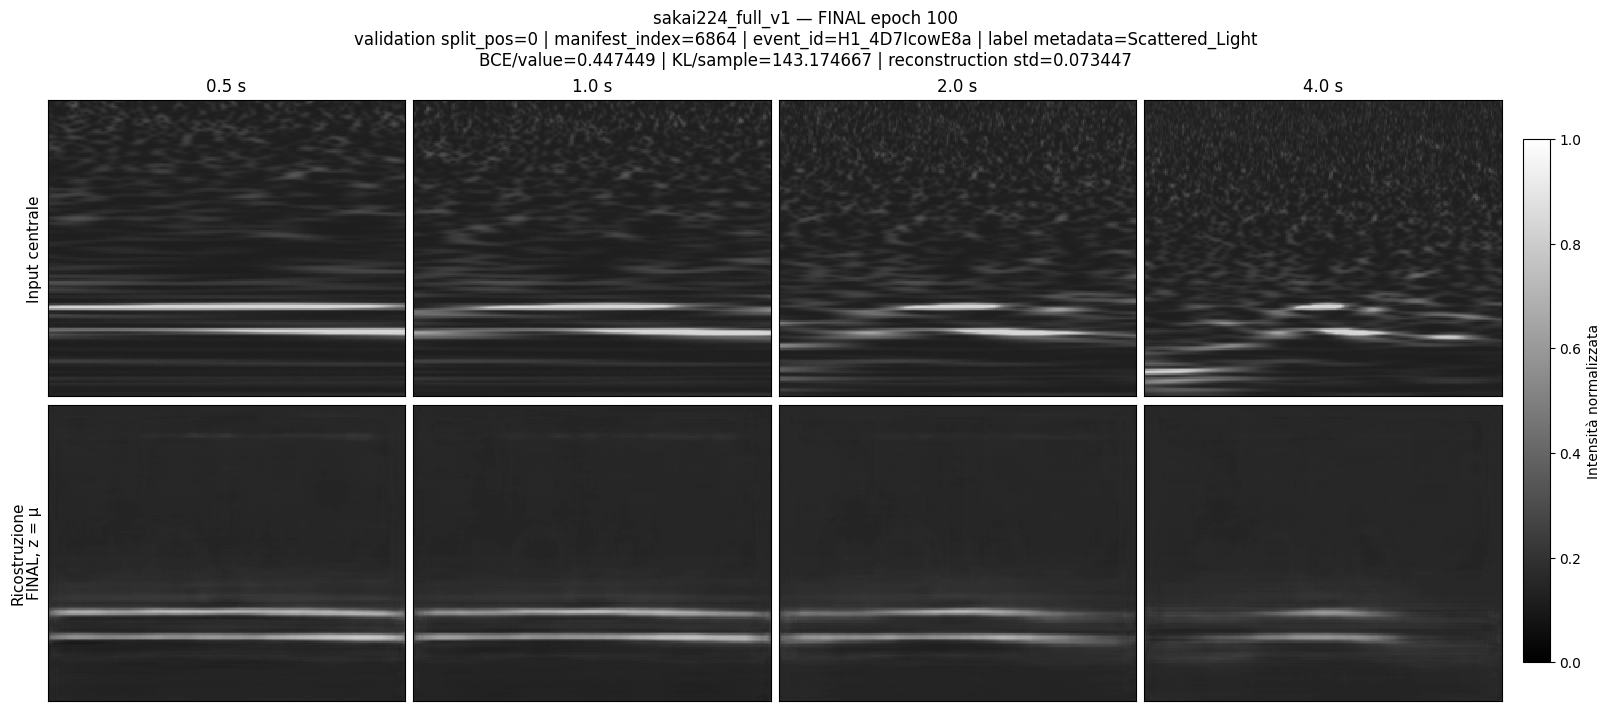

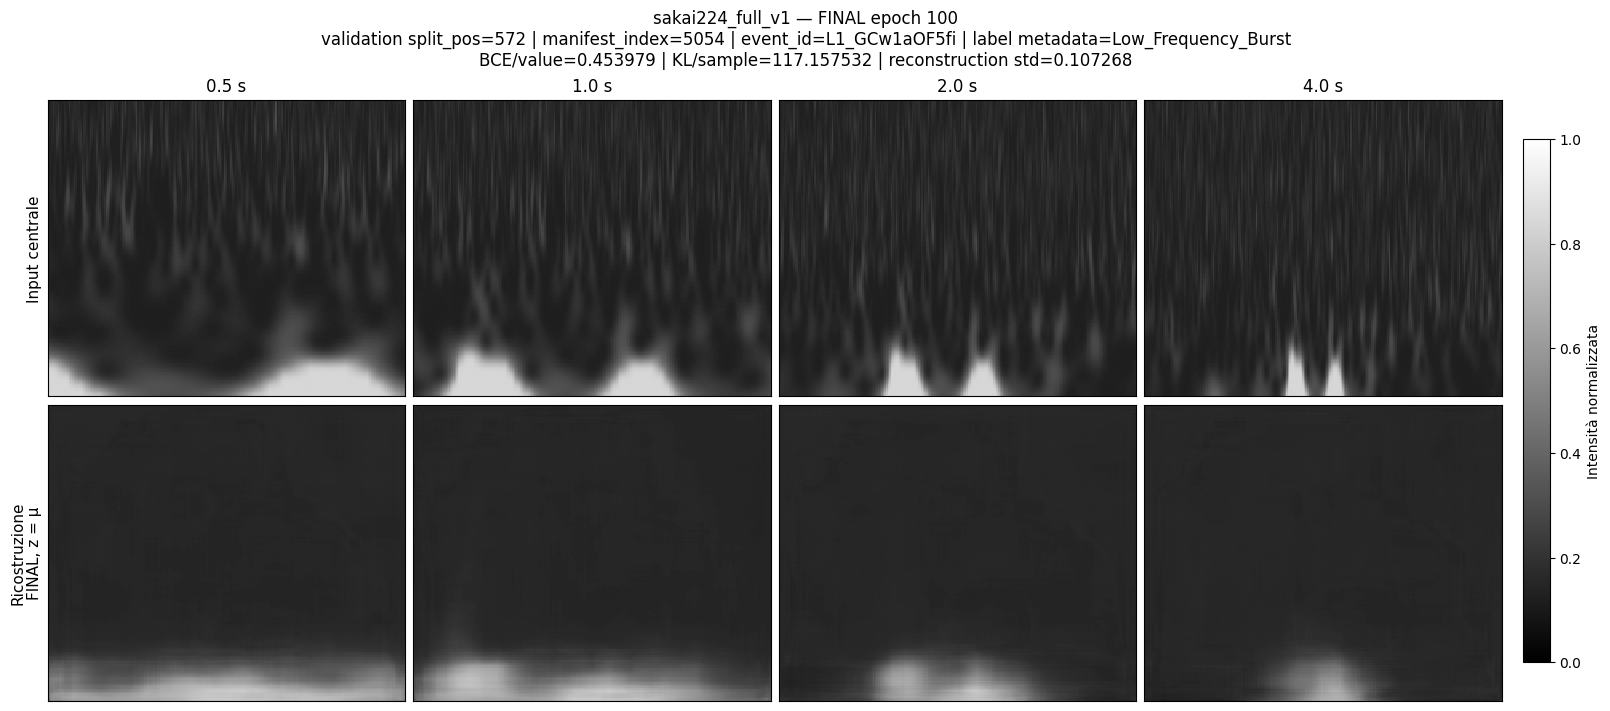

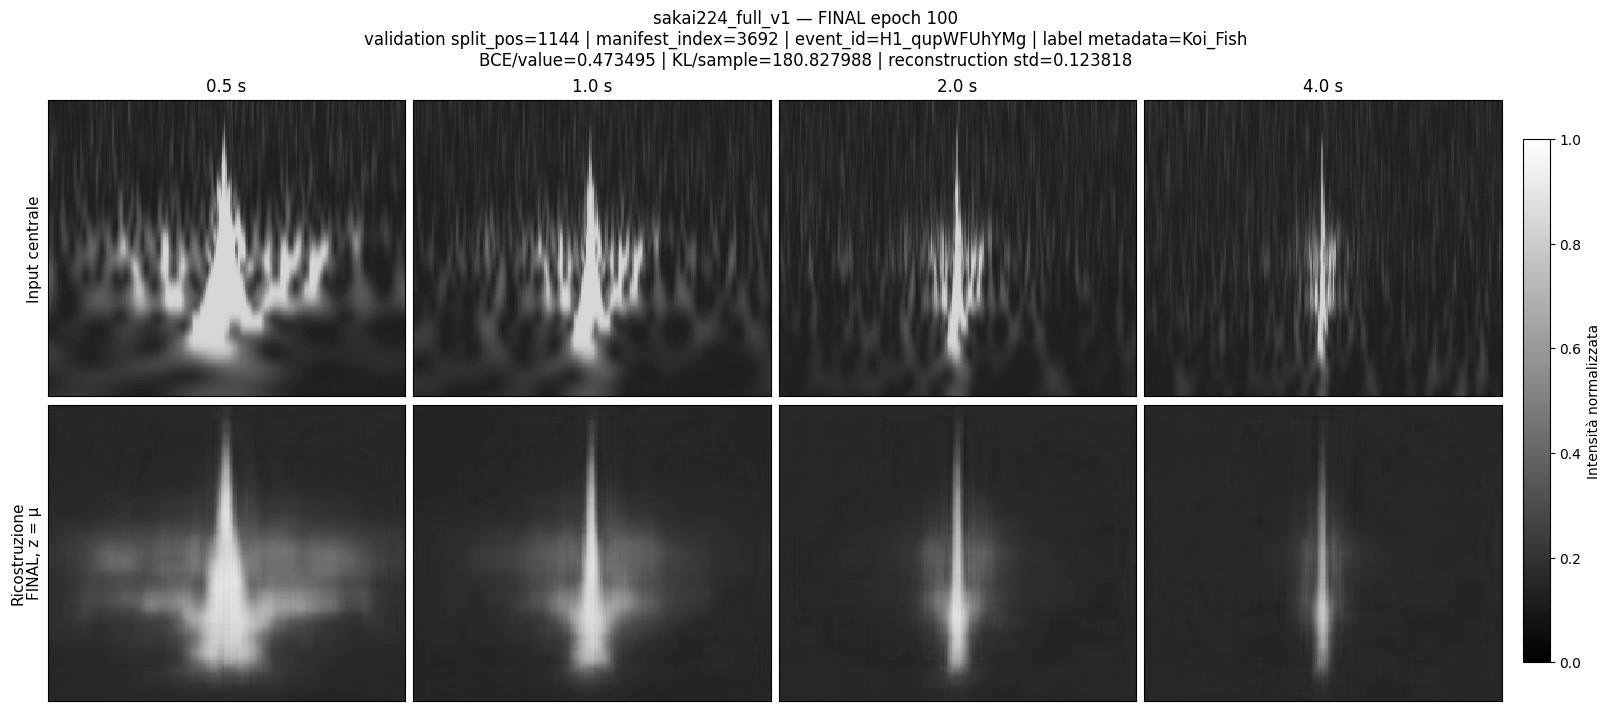

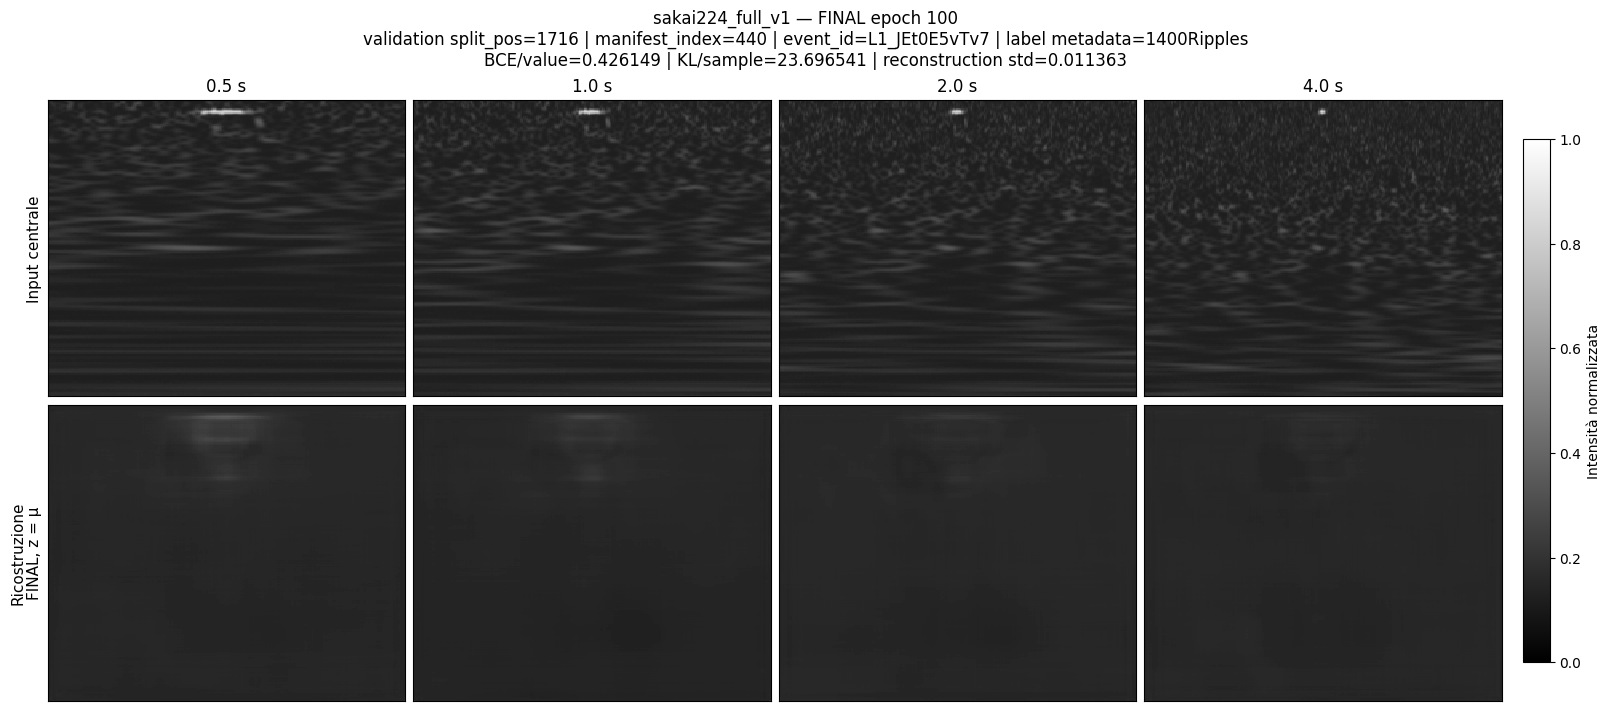


=== NOTEBOOK 04 RECONSTRUCTION VISUALIZATION AUDIT ===

EVENT_COUNT = 4
DURATION_ORDER = ['0.5 s', '1.0 s', '2.0 s', '4.0 s']
VISUAL_SCALE = (0.0, 1.0)
COLORMAP = gray
ORIGIN = upper
INTERPOLATION = nearest

LOCAL_FIGURE_DIRECTORY = /content/sakai224_full_posttraining/reconstruction_figures_epoch100

validation_splitpos_0000_manifest_6864_final_epoch100.png
  bytes = 401884
  sha256 = 85f7d867d2b5ef9263b2b7e07f1302b4466e37728512977581d29abaee59bef0
validation_splitpos_0572_manifest_5054_final_epoch100.png
  bytes = 366248
  sha256 = c77463400bafd4a2191347ca6aeba019951f09c1480aaa23f8cc1ee863641714
validation_splitpos_1144_manifest_3692_final_epoch100.png
  bytes = 399113
  sha256 = 33c13513ba1e2ea0cd13430ce4b149a174de3a767fa64fb2a57d7fd840b9cf2d
validation_splitpos_1716_manifest_0440_final_epoch100.png
  bytes = 359976
  sha256 = 92d4413db1749344ed149ef367900eb028a25680b7dc0455d42b71e7215e713e

VISUAL_DATA_GATE = True
SAVED_FIGURE_GATE = True
MODEL_STATE_PRESERVED_GATE = True

PER_IMAG

In [6]:
# ============================================================
# NOTEBOOK 04 — VISUAL INPUT / RECONSTRUCTION COMPARISON
# STEP 04-A4b
#
# Uses the outputs already computed in A4a.
#
# Same [0,1] intensity scale for input and reconstruction.
# No per-image normalization.
# No contrast enhancement.
#
# Creates local figures only in temporary runtime storage.
# ============================================================

from pathlib import Path

import gc
import hashlib

import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

import numpy as np
import torch


# ============================================================
# PRECONDITIONS
# ============================================================

assert len(
    reconstruction_samples
) == 4

assert tuple(
    reconstruction_input_cpu.shape
) == (
    4,
    4,
    224,
    224,
)

assert tuple(
    reconstruction_probability_cpu.shape
) == (
    4,
    4,
    224,
    224,
)

assert reconstruction_input_cpu.dtype \
    == torch.float32

assert reconstruction_probability_cpu.dtype \
    == torch.float32

assert torch.isfinite(
    reconstruction_input_cpu
).all().item()

assert torch.isfinite(
    reconstruction_probability_cpu
).all().item()


# ============================================================
# FIXED VISUAL CONTRACT
# ============================================================

DURATION_NAMES = [
    "0.5 s",
    "1.0 s",
    "2.0 s",
    "4.0 s",
]

VISUAL_VMIN = 0.0
VISUAL_VMAX = 1.0

VISUAL_CMAP = "gray"

# Preserve the row orientation of the stored arrays.
VISUAL_ORIGIN = "upper"

# Avoid display interpolation that could invent morphology.
VISUAL_INTERPOLATION = "nearest"


# ============================================================
# LOCAL OUTPUT DIRECTORY
#
# This directory is temporary runtime storage.
# Persistent publication is handled by the post-training artifact stage.
# ============================================================

LOCAL_RECONSTRUCTION_FIGURES_DIR = (
    LOCAL_POSTTRAIN_ROOT
    / "reconstruction_figures_epoch100"
)

LOCAL_RECONSTRUCTION_FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# MODEL STATE BEFORE VISUALIZATION
# ============================================================

model_state_before_visualization = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


assert (
    model_state_before_visualization
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


# ============================================================
# VISUAL DATA GATE
# ============================================================

visual_data_gate = (
    float(
        reconstruction_input_cpu.min()
    ) >= 0.0

    and float(
        reconstruction_input_cpu.max()
    ) <= 1.0

    and float(
        reconstruction_probability_cpu.min()
    ) >= 0.0

    and float(
        reconstruction_probability_cpu.max()
    ) <= 1.0
)


assert visual_data_gate


# ============================================================
# CREATE ONE 2x4 FIGURE PER EVENT
# ============================================================

reconstruction_figure_paths = []


for sample_index, sample in enumerate(
    reconstruction_samples
):

    input_event = (
        reconstruction_input_cpu[
            sample_index
        ]
        .numpy()
    )

    reconstructed_event = (
        reconstruction_probability_cpu[
            sample_index
        ]
        .numpy()
    )


    assert input_event.shape == (
        4,
        224,
        224,
    )

    assert reconstructed_event.shape == (
        4,
        224,
        224,
    )


    figure, axes = plt.subplots(
        nrows=2,
        ncols=4,
        figsize=(16, 7),
        constrained_layout=True,
    )


    for channel_index, duration_name in enumerate(
        DURATION_NAMES
    ):

        # ----------------------------------------------------
        # INPUT
        # ----------------------------------------------------

        input_axis = axes[
            0,
            channel_index
        ]

        input_axis.imshow(
            input_event[
                channel_index
            ],
            cmap=VISUAL_CMAP,
            vmin=VISUAL_VMIN,
            vmax=VISUAL_VMAX,
            origin=VISUAL_ORIGIN,
            interpolation=VISUAL_INTERPOLATION,
            aspect="auto",
        )

        input_axis.set_title(
            duration_name
        )

        input_axis.set_xticks([])
        input_axis.set_yticks([])


        # ----------------------------------------------------
        # RECONSTRUCTION
        # ----------------------------------------------------

        reconstruction_axis = axes[
            1,
            channel_index
        ]

        reconstruction_axis.imshow(
            reconstructed_event[
                channel_index
            ],
            cmap=VISUAL_CMAP,
            vmin=VISUAL_VMIN,
            vmax=VISUAL_VMAX,
            origin=VISUAL_ORIGIN,
            interpolation=VISUAL_INTERPOLATION,
            aspect="auto",
        )

        reconstruction_axis.set_xticks([])
        reconstruction_axis.set_yticks([])


    # Row labels are visible because the axes themselves
    # remain active while ticks are hidden.
    axes[0, 0].set_ylabel(
        "Input centrale",
        fontsize=11,
    )

    axes[1, 0].set_ylabel(
        "Ricostruzione\nFINAL, z = μ",
        fontsize=11,
    )


    figure.suptitle(
        (
            "sakai224_full_v1 — FINAL epoch 100\n"
            f"validation split_pos={sample['split_pos']} | "
            f"manifest_index={sample['manifest_index']} | "
            f"event_id={sample['event_id']} | "
            f"label metadata={sample['label']}\n"
            f"BCE/value={float(bce_value_cpu[sample_index]):.6f} | "
            f"KL/sample={float(kl_sample_cpu[sample_index]):.6f} | "
            f"reconstruction std={float(recon_std_cpu[sample_index]):.6f}"
        ),
        fontsize=12,
    )


    # One common colorbar confirms that all panels use the
    # same absolute intensity scale.
    scalar_mappable = ScalarMappable(
        norm=Normalize(
            vmin=VISUAL_VMIN,
            vmax=VISUAL_VMAX,
        ),
        cmap=VISUAL_CMAP,
    )

    scalar_mappable.set_array([])


    colorbar = figure.colorbar(
        scalar_mappable,
        ax=axes.ravel().tolist(),
        fraction=0.018,
        pad=0.015,
    )

    colorbar.set_label(
        "Intensità normalizzata"
    )


    figure_path = (
        LOCAL_RECONSTRUCTION_FIGURES_DIR
        / (
            f"validation_splitpos_"
            f"{sample['split_pos']:04d}_"
            f"manifest_"
            f"{sample['manifest_index']:04d}_"
            f"final_epoch100.png"
        )
    )


    figure.savefig(
        figure_path,
        dpi=200,
        bbox_inches="tight",
        facecolor="white",
    )


    reconstruction_figure_paths.append(
        figure_path
    )


    plt.show()
    plt.close(
        figure
    )


# ============================================================
# SAVED FIGURE AUDIT
# ============================================================

saved_figure_gate = (
    len(
        reconstruction_figure_paths
    ) == 4

    and all(
        path.is_file()
        and path.stat().st_size > 0

        for path
        in reconstruction_figure_paths
    )
)


assert saved_figure_gate


# ============================================================
# LOCAL FIGURE SHA-256
#
# Diagnostic identities for the temporary files; persistent copies
# are tracked by the post-training artifact publication stage.
# ============================================================

reconstruction_figure_sha256 = {
    path.name:
        hashlib.sha256(
            path.read_bytes()
        ).hexdigest()

    for path
    in reconstruction_figure_paths
}


# ============================================================
# MODEL MUST REMAIN UNCHANGED
# ============================================================

model_state_after_visualization = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


model_state_preserved_gate = (
    model_state_before_visualization
    == model_state_after_visualization
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


assert model_state_preserved_gate


# ============================================================
# REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 RECONSTRUCTION VISUALIZATION AUDIT ==="
)

print()

print(
    "EVENT_COUNT =",
    len(
        reconstruction_samples
    ),
)

print(
    "DURATION_ORDER =",
    DURATION_NAMES,
)

print(
    "VISUAL_SCALE =",
    (
        VISUAL_VMIN,
        VISUAL_VMAX,
    ),
)

print(
    "COLORMAP =",
    VISUAL_CMAP,
)

print(
    "ORIGIN =",
    VISUAL_ORIGIN,
)

print(
    "INTERPOLATION =",
    VISUAL_INTERPOLATION,
)

print()

print(
    "LOCAL_FIGURE_DIRECTORY =",
    LOCAL_RECONSTRUCTION_FIGURES_DIR,
)

print()


for path in reconstruction_figure_paths:

    print(
        path.name
    )

    print(
        "  bytes =",
        path.stat().st_size,
    )

    print(
        "  sha256 =",
        reconstruction_figure_sha256[
            path.name
        ],
    )


print()

print(
    "VISUAL_DATA_GATE =",
    visual_data_gate,
)

print(
    "SAVED_FIGURE_GATE =",
    saved_figure_gate,
)

print(
    "MODEL_STATE_PRESERVED_GATE =",
    model_state_preserved_gate,
)

print()

print(
    "PER_IMAGE_AUTOSCALING =",
    False,
)

print(
    "CONTRAST_ENHANCEMENT =",
    False,
)

print(
    "LABELS_USED_FOR_SELECTION =",
    False,
)

print(
    "MODEL_FORWARD_EXECUTED_IN_A4B =",
    False,
)

print(
    "OFFICIAL_DRIVE_ARTIFACTS_MODIFIED =",
    False,
)

print()

print(
    "NOTEBOOK_04_RECONSTRUCTION_VISUALIZATION_PASS =",
    (
        visual_data_gate
        and saved_figure_gate
        and model_state_preserved_gate
    ),
)

## STEP 04-A4c — Audit delle ricostruzioni sull'intera validation

Le quattro ricostruzioni visualizzate mostrano conservazione della morfologia
dominante, ma anche una qualità non uniforme.

Per verificare che i casi piatti non rappresentino un comportamento diffuso,
il modello FINAL è valutato su tutti i 1.717 eventi della validation
centrale.

Per ogni evento vengono calcolate esclusivamente metriche diagnostiche:

- BCE per valore;
- KL per campione;
- MSE e MAE;
- deviazione standard di input e ricostruzione;
- rapporto di contrasto;
- correlazione lineare input–ricostruzione;
- norma \(L_2\) dell'embedding \(\mu\).

Queste quantità non sono metriche pubblicate da Sakai e non vengono usate
per modificare o selezionare il modello. Servono soltanto a verificare se emerga evidenza di collasso globale secondo
le diagnostiche adottate e a selezionare, senza label, casi estremi per
la successiva ispezione visiva.

Le label Gravity Spy sono conservate come metadato a posteriori, ma non
partecipano al calcolo, all'ordinamento o alla selezione.

In [7]:
# ============================================================
# NOTEBOOK 04 — FULL VALIDATION RECONSTRUCTION AUDIT
# STEP 04-A4c
#
# FINAL epoch-100 model
# deterministic z = mu
# all 1,717 central-validation events
#
# No training.
# No model selection.
# No clustering.
# No persistent project-storage writes.
# ============================================================

from pathlib import Path

import csv
import gc
import hashlib
import os

import numpy as np
import torch
import torch.nn.functional as F

from torch.utils.data import DataLoader


# ============================================================
# RELEASE OLD GPU ACTIVATIONS FROM A4a
# ============================================================

for variable_name in [
    "reconstruction_input",
    "reconstruction_mu",
    "reconstruction_logvar",
    "reconstruction_z",
    "reconstruction_logits",
    "reconstruction_probability",
    "reconstruction_bce_per_element",
    "reconstruction_bce_per_sample",
    "reconstruction_kl_per_sample",
    "reconstruction_total_per_sample",
    "reconstruction_bce_per_value",
    "reconstruction_std_per_sample",
]:

    globals().pop(
        variable_name,
        None,
    )


gc.collect()
torch.cuda.empty_cache()


# ============================================================
# AUDIT CONFIGURATION
# ============================================================

FULL_RECON_BATCH_SIZE = 128
FULL_RECON_NUM_WORKERS = min(
    8,
    os.cpu_count() or 1,
)

FULL_RECON_EXPECTED_SAMPLES = 1717
FULL_RECON_EXPECTED_BATCHES = 14
FULL_RECON_EXPECTED_TAIL = 53

PIXELS_PER_EVENT = (
    4 * 224 * 224
)


assert len(
    validation_central_dataset
) == FULL_RECON_EXPECTED_SAMPLES


# ============================================================
# DATALOADER
# ============================================================

full_reconstruction_loader = DataLoader(
    validation_central_dataset,

    batch_size=FULL_RECON_BATCH_SIZE,

    shuffle=False,

    num_workers=FULL_RECON_NUM_WORKERS,

    pin_memory=True,

    drop_last=False,

    persistent_workers=False,

    prefetch_factor=2,
)


# ============================================================
# MODEL STATE BEFORE THE AUDIT
# ============================================================

official_final_model.eval()


state_before_full_reconstruction = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


assert (
    state_before_full_reconstruction
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


# ============================================================
# FULL VALIDATION INFERENCE
# ============================================================

diagnostic_rows = []

sample_count = 0
batch_count = 0
tail_size = None

first_manifest_indices = None


with torch.inference_mode():

    for batch_index, batch in enumerate(
        full_reconstruction_loader
    ):

        x = (
            batch["x"]
            .to(
                device=runtime_device,
                dtype=torch.float32,
                non_blocking=True,
            )
        )


        mu, logvar = (
            official_final_model.encode(
                x
            )
        )


        logits = (
            official_final_model.decode(
                mu
            )
        )


        probability = torch.sigmoid(
            logits
        )


        current_batch_size = int(
            x.shape[0]
        )


        if batch_index == 0:

            first_manifest_indices = (
                batch[
                    "manifest_index"
                ][:4].tolist()
            )


        # ----------------------------------------------------
        # VAE objective diagnostics
        # ----------------------------------------------------

        bce_per_sample = (
            F.binary_cross_entropy_with_logits(
                logits,
                x,
                reduction="none",
            )
            .flatten(start_dim=1)
            .sum(dim=1)
        )


        bce_per_value = (
            bce_per_sample
            / PIXELS_PER_EVENT
        )


        kl_per_sample = (
            0.5
            * (
                mu.square()
                + torch.expm1(logvar)
                - logvar
            )
            .sum(dim=1)
        )


        total_per_sample = (
            bce_per_sample
            + kl_per_sample
        )


        # ----------------------------------------------------
        # Direct reconstruction diagnostics
        # ----------------------------------------------------

        difference = (
            probability
            - x
        )


        mse_per_value = (
            difference.square()
            .flatten(start_dim=1)
            .mean(dim=1)
        )


        mae_per_value = (
            difference.abs()
            .flatten(start_dim=1)
            .mean(dim=1)
        )


        x_flat = x.flatten(
            start_dim=1
        )

        probability_flat = (
            probability.flatten(
                start_dim=1
            )
        )


        input_std = x_flat.std(
            dim=1,
            unbiased=False,
        )


        reconstruction_std = (
            probability_flat.std(
                dim=1,
                unbiased=False,
            )
        )


        contrast_ratio = (
            reconstruction_std
            / input_std.clamp_min(
                1.0e-12
            )
        )


        # Mean-centred linear correlation.
        x_centered = (
            x_flat
            - x_flat.mean(
                dim=1,
                keepdim=True,
            )
        )

        reconstruction_centered = (
            probability_flat
            - probability_flat.mean(
                dim=1,
                keepdim=True,
            )
        )


        correlation_numerator = (
            x_centered
            * reconstruction_centered
        ).sum(dim=1)


        correlation_denominator = torch.sqrt(
            x_centered.square()
            .sum(dim=1)

            * reconstruction_centered.square()
            .sum(dim=1)
        ).clamp_min(
            1.0e-12
        )


        pearson_correlation = (
            correlation_numerator
            / correlation_denominator
        )


        mu_l2 = torch.linalg.vector_norm(
            mu,
            ord=2,
            dim=1,
        )


        # ----------------------------------------------------
        # MOVE ONLY SCALARS/METADATA TO CPU
        # ----------------------------------------------------

        metric_arrays = {

            "bce_per_sample":
                bce_per_sample.cpu().numpy(),

            "bce_per_value":
                bce_per_value.cpu().numpy(),

            "kl_per_sample":
                kl_per_sample.cpu().numpy(),

            "total_per_sample":
                total_per_sample.cpu().numpy(),

            "mse_per_value":
                mse_per_value.cpu().numpy(),

            "mae_per_value":
                mae_per_value.cpu().numpy(),

            "input_std":
                input_std.cpu().numpy(),

            "reconstruction_std":
                reconstruction_std.cpu().numpy(),

            "contrast_ratio":
                contrast_ratio.cpu().numpy(),

            "pearson_correlation":
                pearson_correlation.cpu().numpy(),

            "mu_l2":
                mu_l2.cpu().numpy(),
        }


        for local_index in range(
            current_batch_size
        ):

            diagnostic_rows.append({

                "split":
                    "validation",

                "split_pos":
                    int(
                        batch[
                            "split_pos"
                        ][local_index]
                    ),

                "manifest_index":
                    int(
                        batch[
                            "manifest_index"
                        ][local_index]
                    ),

                "event_index":
                    int(
                        batch[
                            "event_index"
                        ][local_index]
                    ),

                "event_id":
                    batch[
                        "event_id"
                    ][local_index],

                # Metadata only; never used below
                # for ordering or selection.
                "label_metadata":
                    batch[
                        "label"
                    ][local_index],

                "bce_per_sample":
                    float(
                        metric_arrays[
                            "bce_per_sample"
                        ][local_index]
                    ),

                "bce_per_value":
                    float(
                        metric_arrays[
                            "bce_per_value"
                        ][local_index]
                    ),

                "kl_per_sample":
                    float(
                        metric_arrays[
                            "kl_per_sample"
                        ][local_index]
                    ),

                "total_per_sample":
                    float(
                        metric_arrays[
                            "total_per_sample"
                        ][local_index]
                    ),

                "mse_per_value":
                    float(
                        metric_arrays[
                            "mse_per_value"
                        ][local_index]
                    ),

                "mae_per_value":
                    float(
                        metric_arrays[
                            "mae_per_value"
                        ][local_index]
                    ),

                "input_std":
                    float(
                        metric_arrays[
                            "input_std"
                        ][local_index]
                    ),

                "reconstruction_std":
                    float(
                        metric_arrays[
                            "reconstruction_std"
                        ][local_index]
                    ),

                "contrast_ratio":
                    float(
                        metric_arrays[
                            "contrast_ratio"
                        ][local_index]
                    ),

                "pearson_correlation":
                    float(
                        metric_arrays[
                            "pearson_correlation"
                        ][local_index]
                    ),

                "mu_l2":
                    float(
                        metric_arrays[
                            "mu_l2"
                        ][local_index]
                    ),
            })


        sample_count += (
            current_batch_size
        )

        batch_count += 1

        tail_size = (
            current_batch_size
        )


torch.cuda.synchronize()


# ============================================================
# STRUCTURAL GATES
# ============================================================

count_gate = (
    sample_count
        == FULL_RECON_EXPECTED_SAMPLES

    and len(
        diagnostic_rows
    )
        == FULL_RECON_EXPECTED_SAMPLES

    and batch_count
        == FULL_RECON_EXPECTED_BATCHES

    and tail_size
        == FULL_RECON_EXPECTED_TAIL
)


order_gate = (
    first_manifest_indices
    == [
        6864,
        1488,
        8384,
        6585,
    ]

    and [
        row["split_pos"]
        for row
        in diagnostic_rows
    ]
    == list(
        range(
            FULL_RECON_EXPECTED_SAMPLES
        )
    )

    and len({
        row["manifest_index"]
        for row
        in diagnostic_rows
    })
    == FULL_RECON_EXPECTED_SAMPLES
)


assert count_gate
assert order_gate


# ============================================================
# NUMERIC GATES
# ============================================================

DIAGNOSTIC_NUMERIC_FIELDS = [
    "bce_per_sample",
    "bce_per_value",
    "kl_per_sample",
    "total_per_sample",
    "mse_per_value",
    "mae_per_value",
    "input_std",
    "reconstruction_std",
    "contrast_ratio",
    "pearson_correlation",
    "mu_l2",
]


numeric_gate = all(
    np.isfinite(
        row[field]
    )

    for row in diagnostic_rows

    for field in DIAGNOSTIC_NUMERIC_FIELDS
)


exact_constant_reconstruction_count = sum(
    row[
        "reconstruction_std"
    ] == 0.0

    for row in diagnostic_rows
)


nonconstant_gate = (
    exact_constant_reconstruction_count
    == 0
)


assert numeric_gate
assert nonconstant_gate


# ============================================================
# MODEL IMMUTABILITY
# ============================================================

state_after_full_reconstruction = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


state_preserved_gate = (
    state_before_full_reconstruction
    == state_after_full_reconstruction
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


assert state_preserved_gate


# ============================================================
# LOCAL DIAGNOSTIC CSV
#
# Local diagnostic staged for the versioned post-training artifact.
# ============================================================

FULL_RECON_DIAGNOSTIC_CSV = (
    LOCAL_POSTTRAIN_ROOT
    / "validation_reconstruction_diagnostics_epoch100.csv"
)


CSV_FIELDS = [
    "split",
    "split_pos",
    "manifest_index",
    "event_index",
    "event_id",
    "label_metadata",
    *DIAGNOSTIC_NUMERIC_FIELDS,
]


with FULL_RECON_DIAGNOSTIC_CSV.open(
    "w",
    newline="",
    encoding="utf-8",
) as handle:

    writer = csv.DictWriter(
        handle,
        fieldnames=CSV_FIELDS,
    )

    writer.writeheader()
    writer.writerows(
        diagnostic_rows
    )


diagnostic_csv_sha256 = (
    hashlib.sha256(
        FULL_RECON_DIAGNOSTIC_CSV
        .read_bytes()
    ).hexdigest()
)


# ============================================================
# QUANTILES
# ============================================================

QUANTILE_LEVELS = np.asarray(
    [
        0.00,
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
        0.99,
        1.00,
    ],
    dtype=np.float64,
)


def field_values(field):

    return np.asarray(
        [
            row[field]
            for row
            in diagnostic_rows
        ],
        dtype=np.float64,
    )


def field_quantiles(field):

    return np.quantile(
        field_values(field),
        QUANTILE_LEVELS,
    )


bce_quantiles = field_quantiles(
    "bce_per_value"
)

kl_quantiles = field_quantiles(
    "kl_per_sample"
)

mse_quantiles = field_quantiles(
    "mse_per_value"
)

correlation_quantiles = (
    field_quantiles(
        "pearson_correlation"
    )
)

reconstruction_std_quantiles = (
    field_quantiles(
        "reconstruction_std"
    )
)

contrast_ratio_quantiles = (
    field_quantiles(
        "contrast_ratio"
    )
)


# ============================================================
# LABEL-BLIND EXTREME CASE SELECTION
#
# Label is displayed only AFTER numeric selection.
# ============================================================

lowest_correlation_rows = sorted(
    diagnostic_rows,
    key=lambda row:
        row[
            "pearson_correlation"
        ],
)[:8]


lowest_contrast_rows = sorted(
    diagnostic_rows,
    key=lambda row:
        row[
            "reconstruction_std"
        ],
)[:8]


highest_bce_rows = sorted(
    diagnostic_rows,
    key=lambda row:
        row[
            "bce_per_value"
        ],
    reverse=True,
)[:8]


# Threshold counts are descriptive only.
# They are NOT pass/fail criteria.

reconstruction_std_values = field_values(
    "reconstruction_std"
)


count_std_below_005 = int(
    np.sum(
        reconstruction_std_values
        < 0.005
    )
)

count_std_below_010 = int(
    np.sum(
        reconstruction_std_values
        < 0.010
    )
)

count_std_below_020 = int(
    np.sum(
        reconstruction_std_values
        < 0.020
    )
)


# ============================================================
# REPORT
# ============================================================

def print_quantile_block(
    name,
    values,
):

    print(
        name,
    )

    for level, value in zip(
        QUANTILE_LEVELS,
        values,
    ):

        print(
            f"  q={level:4.2f}:",
            float(value),
        )


def print_extreme_rows(
    title,
    rows,
    value_field,
):

    print()
    print(
        title
    )

    for row in rows:

        print(
            "  split_pos=",
            row["split_pos"],

            "| manifest_index=",
            row["manifest_index"],

            "| event_id=",
            row["event_id"],

            "|",
            value_field,
            "=",
            row[value_field],

            "| recon_std=",
            row["reconstruction_std"],

            "| label_metadata=",
            row["label_metadata"],
        )


print()
print(
    "=== NOTEBOOK 04 FULL VALIDATION RECONSTRUCTION AUDIT ==="
)

print()

print(
    "VALIDATION_SAMPLES =",
    sample_count,
)

print(
    "BATCHES =",
    batch_count,
)

print(
    "TAIL_BATCH =",
    tail_size,
)

print(
    "FIRST_MANIFEST_INDICES =",
    first_manifest_indices,
)

print()


print_quantile_block(
    "BCE_PER_VALUE_QUANTILES",
    bce_quantiles,
)

print()

print_quantile_block(
    "KL_PER_SAMPLE_QUANTILES",
    kl_quantiles,
)

print()

print_quantile_block(
    "MSE_PER_VALUE_QUANTILES",
    mse_quantiles,
)

print()

print_quantile_block(
    "PEARSON_CORRELATION_QUANTILES",
    correlation_quantiles,
)

print()

print_quantile_block(
    "RECONSTRUCTION_STD_QUANTILES",
    reconstruction_std_quantiles,
)

print()

print_quantile_block(
    "CONTRAST_RATIO_QUANTILES",
    contrast_ratio_quantiles,
)


print()
print(
    "EXACT_CONSTANT_RECONSTRUCTIONS =",
    exact_constant_reconstruction_count,
)

print(
    "RECON_STD_BELOW_0.005 =",
    count_std_below_005,
)

print(
    "RECON_STD_BELOW_0.010 =",
    count_std_below_010,
)

print(
    "RECON_STD_BELOW_0.020 =",
    count_std_below_020,
)


print_extreme_rows(
    "LOWEST_CORRELATION_CASES",
    lowest_correlation_rows,
    "pearson_correlation",
)

print_extreme_rows(
    "LOWEST_RECONSTRUCTION_CONTRAST_CASES",
    lowest_contrast_rows,
    "reconstruction_std",
)

print_extreme_rows(
    "HIGHEST_BCE_CASES",
    highest_bce_rows,
    "bce_per_value",
)


print()
print(
    "LOCAL_DIAGNOSTIC_CSV =",
    FULL_RECON_DIAGNOSTIC_CSV,
)

print(
    "LOCAL_DIAGNOSTIC_CSV_BYTES =",
    FULL_RECON_DIAGNOSTIC_CSV
    .stat()
    .st_size,
)

print(
    "LOCAL_DIAGNOSTIC_CSV_SHA256 =",
    diagnostic_csv_sha256,
)

print()

print(
    "COUNT_GATE =",
    count_gate,
)

print(
    "ORDER_GATE =",
    order_gate,
)

print(
    "NUMERIC_GATE =",
    numeric_gate,
)

print(
    "NONCONSTANT_GATE =",
    nonconstant_gate,
)

print(
    "MODEL_STATE_PRESERVED_GATE =",
    state_preserved_gate,
)

print()

print(
    "LABELS_USED_FOR_SELECTION =",
    False,
)

print(
    "MODEL_UPDATED =",
    False,
)

print(
    "OFFICIAL_DRIVE_ARTIFACTS_MODIFIED =",
    False,
)

print()

print(
    "NOTEBOOK_04_FULL_RECONSTRUCTION_AUDIT_PASS =",
    (
        count_gate
        and order_gate
        and numeric_gate
        and nonconstant_gate
        and state_preserved_gate
    ),
)


=== NOTEBOOK 04 FULL VALIDATION RECONSTRUCTION AUDIT ===

VALIDATION_SAMPLES = 1717
BATCHES = 14
TAIL_BATCH = 53
FIRST_MANIFEST_INDICES = [6864, 1488, 8384, 6585]

BCE_PER_VALUE_QUANTILES
  q=0.00: 0.3797004520893097
  q=0.01: 0.4171591567993164
  q=0.05: 0.42790279984474183
  q=0.25: 0.4338062107563019
  q=0.50: 0.43991395831108093
  q=0.75: 0.4535727798938751
  q=0.95: 0.5010500192642211
  q=0.99: 0.527129373550415
  q=1.00: 0.6151523590087891

KL_PER_SAMPLE_QUANTILES
  q=0.00: 18.234859466552734
  q=0.01: 22.139205627441406
  q=0.05: 26.570130920410158
  q=0.25: 46.73897171020508
  q=0.50: 76.75347900390625
  q=0.75: 155.24322509765625
  q=0.95: 363.7148315429687
  q=0.99: 495.7833190917966
  q=1.00: 786.8358154296875

MSE_PER_VALUE_QUANTILES
  q=0.00: 0.00040121388155966997
  q=0.01: 0.0007624013372696936
  q=0.05: 0.0010222866898402573
  q=0.25: 0.001238156808540225
  q=0.50: 0.0015977724688127637
  q=0.75: 0.003182985819876194
  q=0.95: 0.01033038049936294
  q=0.99: 0.0158283904

## STEP 04-A4d — Ispezione label-blind dei casi estremi

L'audit completo della validation non mostra evidenza di collasso globale
secondo le diagnostiche adottate, ma identifica
una coda di eventi ricostruiti peggio della maggioranza.

Vengono quindi visualizzati due gruppi selezionati esclusivamente tramite
metriche numeriche:

1. quattro eventi con correlazione input–ricostruzione minima;
2. quattro eventi con BCE per valore massima.

Le label Gravity Spy vengono mostrate soltanto dopo la selezione e non
contribuiscono all'ordinamento.

Input e ricostruzioni utilizzano la stessa scala assoluta \([0,1]\), senza
autoscaling o enhancement del contrasto.

La ricostruzione resta quella PROJECT deterministica

\[
\hat{x}
=
\sigma\!\left(
D_\theta(\mu_\phi(x))
\right).
\]

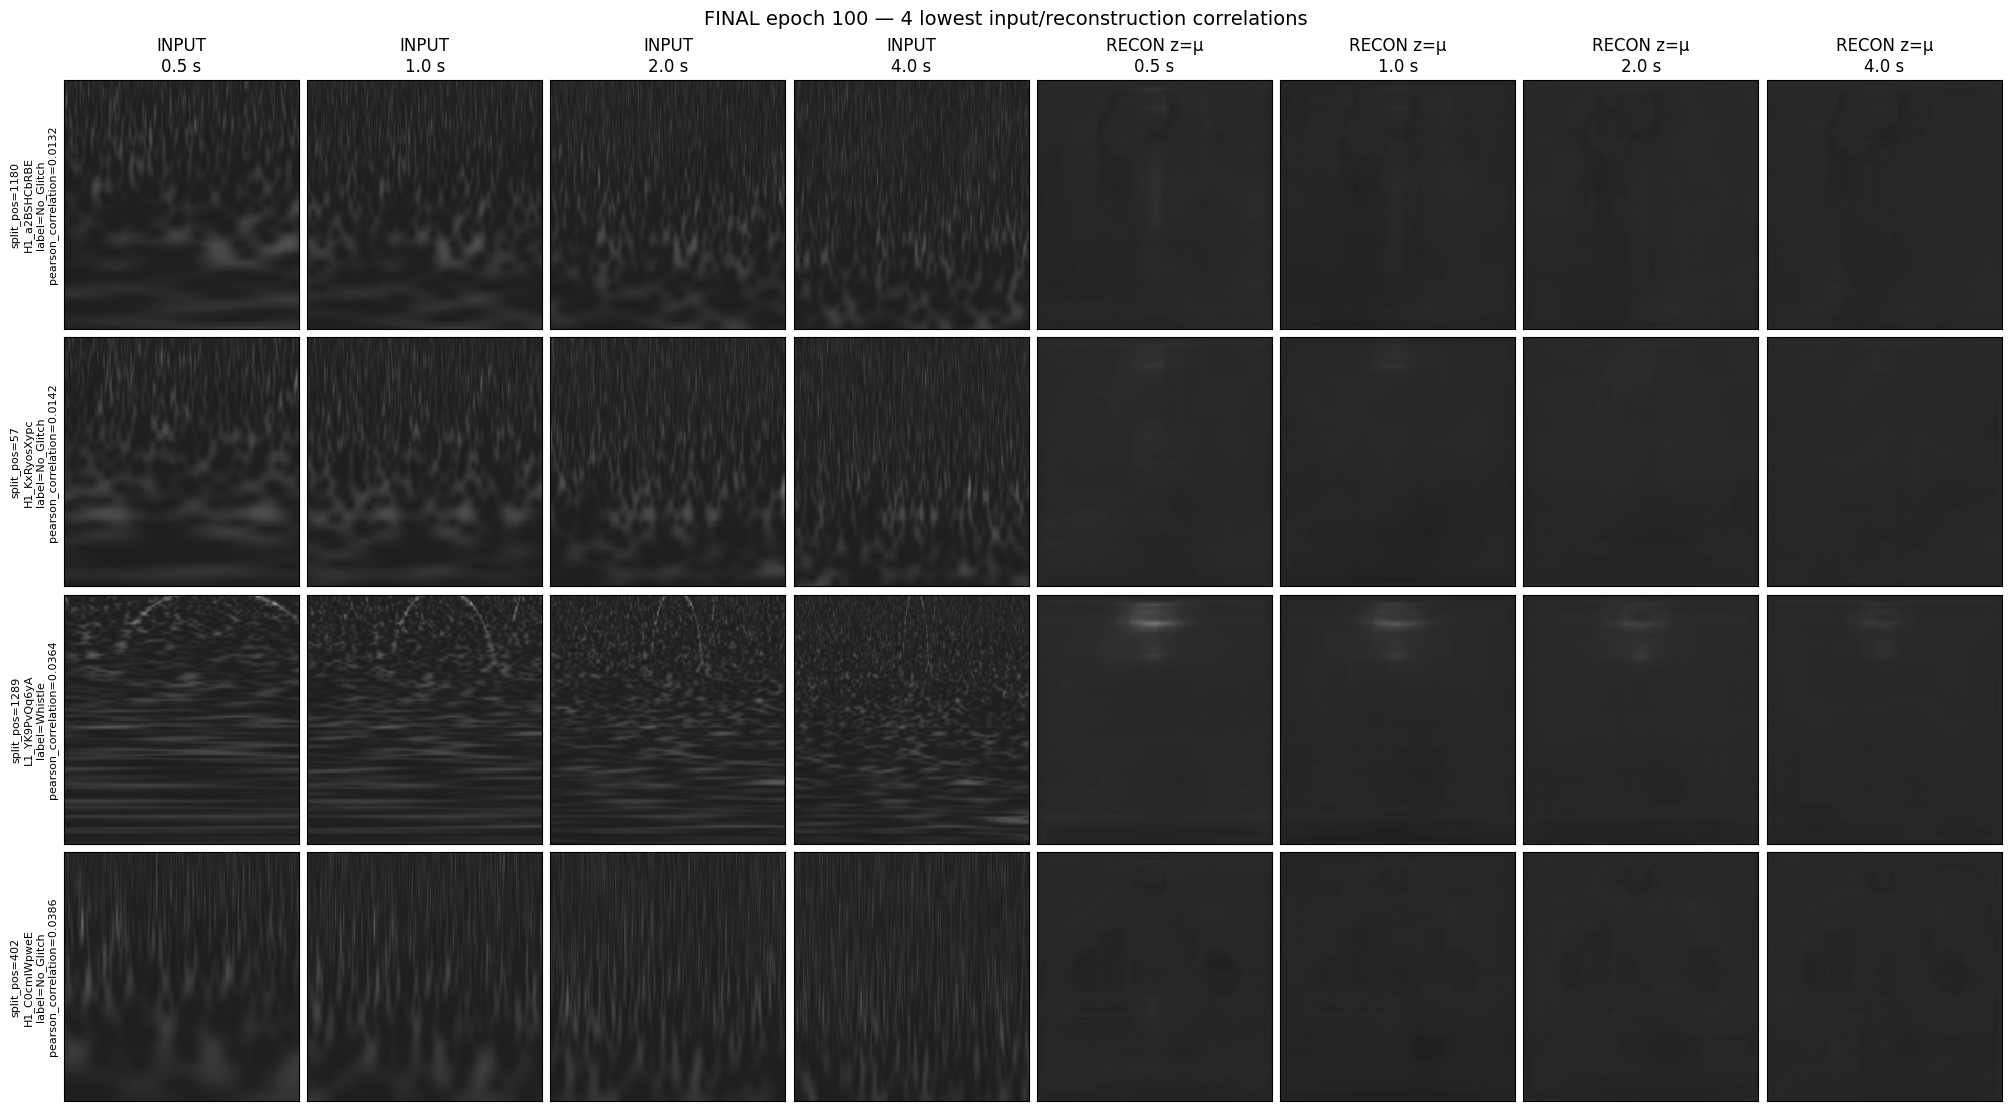

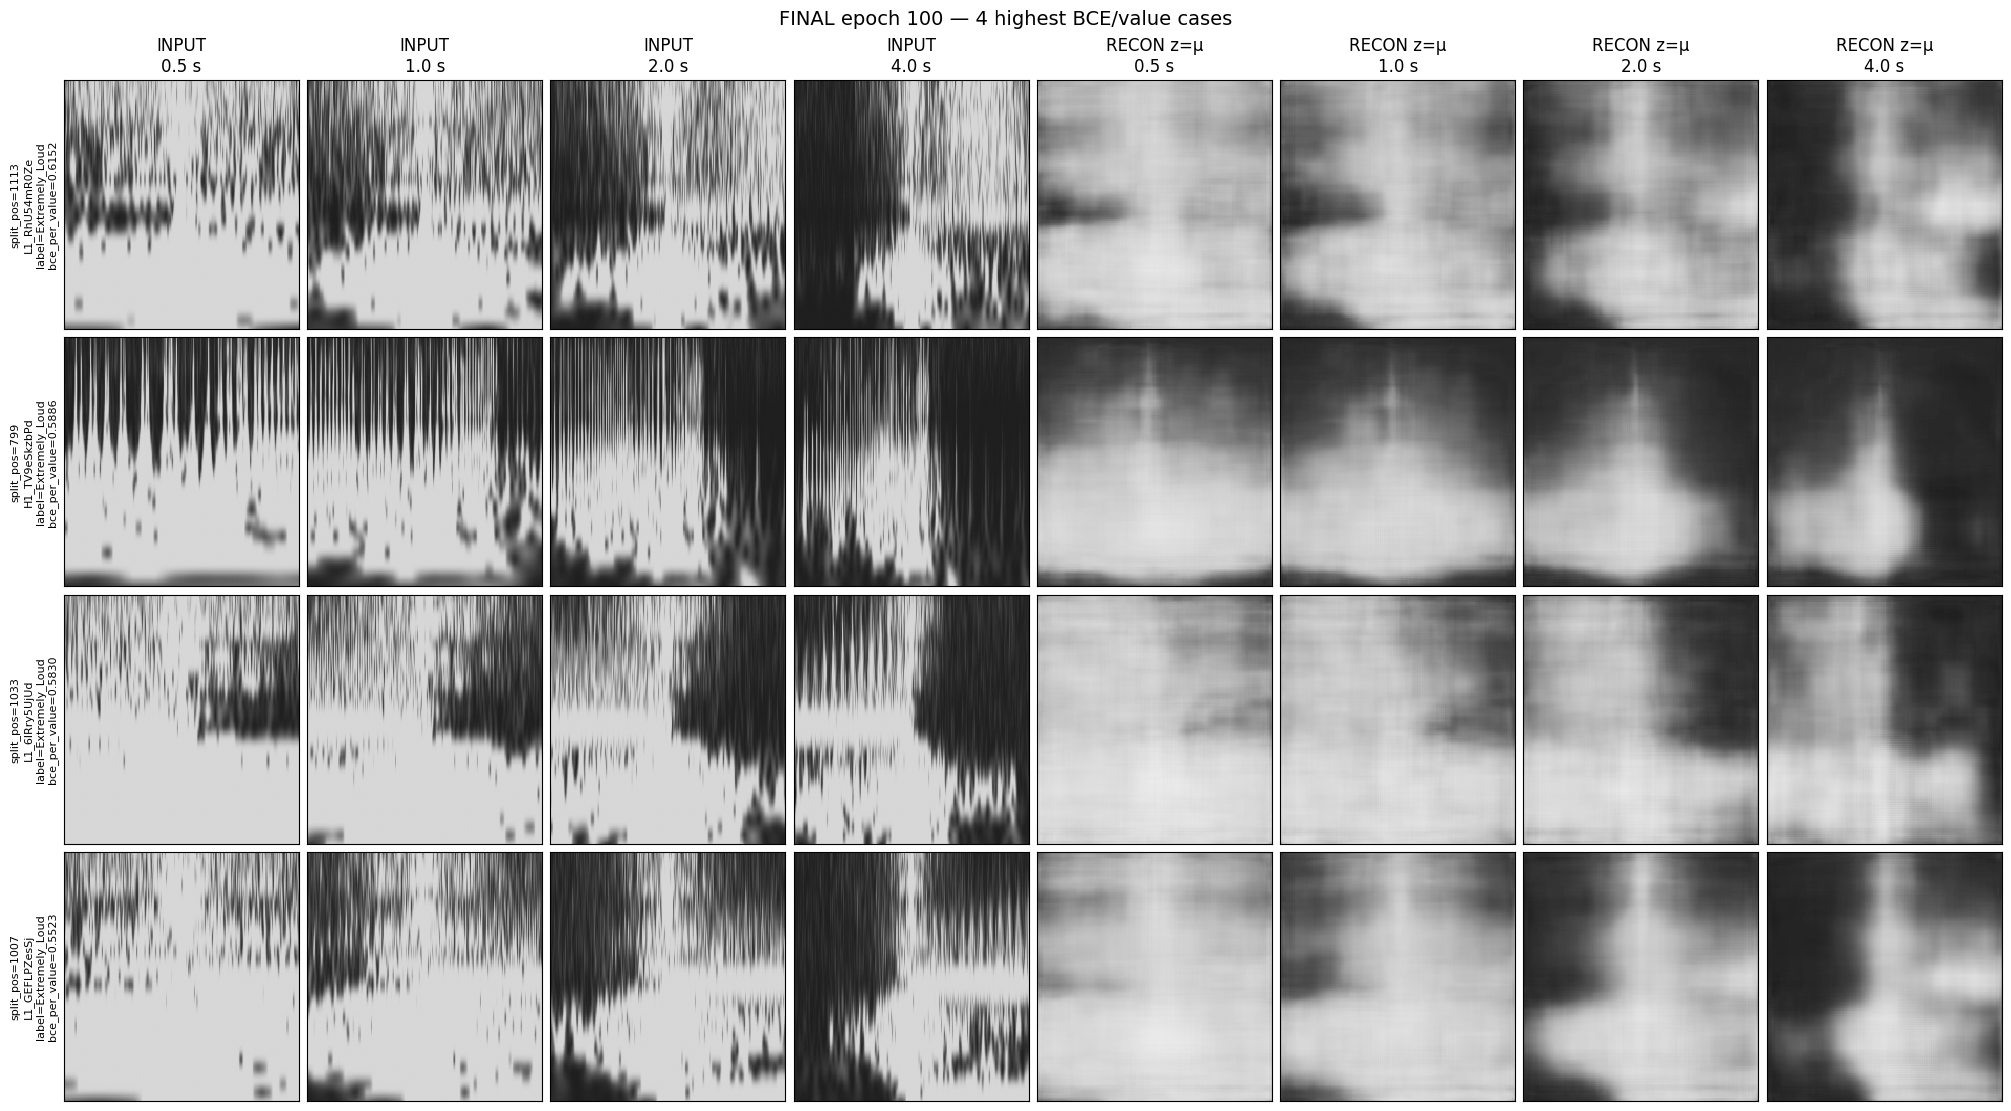


=== NOTEBOOK 04 EXTREME VISUAL AUDIT ===

LOW_CORRELATION_SPLIT_POSITIONS = [1180, 57, 1289, 402]
LOW_CORRELATION_LABELS_AFTER_SELECTION = ['No_Glitch', 'No_Glitch', 'Whistle', 'No_Glitch']

HIGH_BCE_SPLIT_POSITIONS = [1113, 799, 1033, 1007]
HIGH_BCE_LABELS_AFTER_SELECTION = ['Extremely_Loud', 'Extremely_Loud', 'Extremely_Loud', 'Extremely_Loud']

EXTREME_FORWARD_GATE = True
MODEL_STATE_PRESERVED_GATE = True

SELECTION_USED_LABELS = False
LABELS_DISPLAYED_AFTER_SELECTION = True
PER_IMAGE_AUTOSCALING = False
MODEL_UPDATED = False
OFFICIAL_DRIVE_ARTIFACTS_MODIFIED = False

NOTEBOOK_04_EXTREME_VISUAL_AUDIT_PASS = True


In [8]:
# ============================================================
# NOTEBOOK 04 — LABEL-BLIND EXTREME RECONSTRUCTION VISUALS
# STEP 04-A4d
#
# 4 lowest-correlation cases
# 4 highest-BCE cases
#
# Selection was performed using numeric diagnostics only.
# Labels are shown strictly AFTER selection.
#
# Same absolute [0,1] scale everywhere.
#
# NO training.
# NO model update.
# NO Drive writes.
# ============================================================

from pathlib import Path

import gc

import matplotlib.pyplot as plt
import torch


# ============================================================
# LABEL-BLIND SELECTION
# ============================================================

LOW_CORRELATION_SELECTION = (
    lowest_correlation_rows[:4]
)

HIGH_BCE_SELECTION = (
    highest_bce_rows[:4]
)


assert len(
    LOW_CORRELATION_SELECTION
) == 4

assert len(
    HIGH_BCE_SELECTION
) == 4


# ============================================================
# HELPER: LOAD + RECONSTRUCT SELECTED EVENTS
# ============================================================

def reconstruct_selected_rows(
    selected_rows,
):

    samples = [
        validation_central_dataset[
            row["split_pos"]
        ]
        for row in selected_rows
    ]


    x_cpu = torch.stack(
        [
            sample["x"]
            for sample in samples
        ],
        dim=0,
    )


    x = x_cpu.to(
        device=runtime_device,
        dtype=torch.float32,
    )


    official_final_model.eval()


    with torch.inference_mode():

        mu, logvar = (
            official_final_model.encode(
                x
            )
        )

        logits = (
            official_final_model.decode(
                mu
            )
        )

        reconstruction = (
            torch.sigmoid(
                logits
            )
        )


    if runtime_device.type == "cuda":
        torch.cuda.synchronize()


    return (
        samples,
        x_cpu,
        reconstruction.cpu(),
        mu.cpu(),
        logvar.cpu(),
    )


(
    low_corr_samples,
    low_corr_inputs,
    low_corr_reconstructions,
    low_corr_mu,
    low_corr_logvar,
) = reconstruct_selected_rows(
    LOW_CORRELATION_SELECTION
)


(
    high_bce_samples,
    high_bce_inputs,
    high_bce_reconstructions,
    high_bce_mu,
    high_bce_logvar,
) = reconstruct_selected_rows(
    HIGH_BCE_SELECTION
)


# ============================================================
# CONTRACT
# ============================================================

extreme_forward_gate = (

    tuple(
        low_corr_inputs.shape
    ) == (
        4,
        4,
        224,
        224,
    )

    and tuple(
        low_corr_reconstructions.shape
    ) == (
        4,
        4,
        224,
        224,
    )

    and tuple(
        high_bce_inputs.shape
    ) == (
        4,
        4,
        224,
        224,
    )

    and tuple(
        high_bce_reconstructions.shape
    ) == (
        4,
        4,
        224,
        224,
    )

    and torch.isfinite(
        low_corr_reconstructions
    ).all().item()

    and torch.isfinite(
        high_bce_reconstructions
    ).all().item()
)


assert extreme_forward_gate


# ============================================================
# FIGURE HELPER
#
# Each row = one event.
#
# columns 0..3 = INPUT
# columns 4..7 = RECONSTRUCTION
# ============================================================

DURATIONS = [
    "0.5 s",
    "1.0 s",
    "2.0 s",
    "4.0 s",
]


def plot_extreme_group(
    samples,
    inputs,
    reconstructions,
    diagnostic_selection,
    *,
    title,
    diagnostic_field,
):

    figure, axes = plt.subplots(
        nrows=4,
        ncols=8,
        figsize=(20, 11),
        constrained_layout=True,
    )


    for row_index in range(4):

        sample = samples[
            row_index
        ]

        diagnostic_row = (
            diagnostic_selection[
                row_index
            ]
        )


        for channel_index in range(4):

            # INPUT
            ax_input = axes[
                row_index,
                channel_index
            ]

            ax_input.imshow(
                inputs[
                    row_index,
                    channel_index
                ],
                cmap="gray",
                vmin=0.0,
                vmax=1.0,
                origin="upper",
                interpolation="nearest",
                aspect="auto",
            )

            ax_input.set_xticks([])
            ax_input.set_yticks([])


            # RECONSTRUCTION
            ax_recon = axes[
                row_index,
                channel_index + 4
            ]

            ax_recon.imshow(
                reconstructions[
                    row_index,
                    channel_index
                ],
                cmap="gray",
                vmin=0.0,
                vmax=1.0,
                origin="upper",
                interpolation="nearest",
                aspect="auto",
            )

            ax_recon.set_xticks([])
            ax_recon.set_yticks([])


        axes[
            row_index,
            0
        ].set_ylabel(
            (
                f"split_pos={sample['split_pos']}\n"
                f"{sample['event_id']}\n"
                f"label={sample['label']}\n"
                f"{diagnostic_field}="
                f"{diagnostic_row[diagnostic_field]:.4f}"
            ),
            fontsize=8,
        )


    for channel_index, duration in enumerate(
        DURATIONS
    ):

        axes[
            0,
            channel_index
        ].set_title(
            f"INPUT\n{duration}"
        )

        axes[
            0,
            channel_index + 4
        ].set_title(
            f"RECON z=μ\n{duration}"
        )


    figure.suptitle(
        title,
        fontsize=14,
    )

    plt.show()
    plt.close(
        figure
    )


# ============================================================
# LOWEST CORRELATION
# ============================================================

plot_extreme_group(
    low_corr_samples,
    low_corr_inputs,
    low_corr_reconstructions,
    LOW_CORRELATION_SELECTION,
    title=(
        "FINAL epoch 100 — "
        "4 lowest input/reconstruction correlations"
    ),
    diagnostic_field="pearson_correlation",
)


# ============================================================
# HIGHEST BCE
# ============================================================

plot_extreme_group(
    high_bce_samples,
    high_bce_inputs,
    high_bce_reconstructions,
    HIGH_BCE_SELECTION,
    title=(
        "FINAL epoch 100 — "
        "4 highest BCE/value cases"
    ),
    diagnostic_field="bce_per_value",
)


# ============================================================
# MODEL IMMUTABILITY
# ============================================================

state_after_extreme_visuals = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


state_preserved_gate = (
    state_after_extreme_visuals
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


assert state_preserved_gate


# ============================================================
# REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 EXTREME VISUAL AUDIT ==="
)

print()

print(
    "LOW_CORRELATION_SPLIT_POSITIONS =",
    [
        row["split_pos"]
        for row
        in LOW_CORRELATION_SELECTION
    ],
)

print(
    "LOW_CORRELATION_LABELS_AFTER_SELECTION =",
    [
        row["label_metadata"]
        for row
        in LOW_CORRELATION_SELECTION
    ],
)

print()

print(
    "HIGH_BCE_SPLIT_POSITIONS =",
    [
        row["split_pos"]
        for row
        in HIGH_BCE_SELECTION
    ],
)

print(
    "HIGH_BCE_LABELS_AFTER_SELECTION =",
    [
        row["label_metadata"]
        for row
        in HIGH_BCE_SELECTION
    ],
)

print()

print(
    "EXTREME_FORWARD_GATE =",
    extreme_forward_gate,
)

print(
    "MODEL_STATE_PRESERVED_GATE =",
    state_preserved_gate,
)

print()

print(
    "SELECTION_USED_LABELS =",
    False,
)

print(
    "LABELS_DISPLAYED_AFTER_SELECTION =",
    True,
)

print(
    "PER_IMAGE_AUTOSCALING =",
    False,
)

print(
    "MODEL_UPDATED =",
    False,
)

print(
    "OFFICIAL_DRIVE_ARTIFACTS_MODIFIED =",
    False,
)

print()

print(
    "NOTEBOOK_04_EXTREME_VISUAL_AUDIT_PASS =",
    (
        extreme_forward_gate
        and state_preserved_gate
    ),
)

## STEP 04-A5a — Estrazione completa dello spazio latente del modello FINAL

Il modello scientifico utilizzato è il VAE `FINAL` dopo **100 epoche complete**.

Per ogni evento centrale $x$, l'encoder calcola i parametri della distribuzione latente:

$$
E_\phi(x)
=
\left(
\mu_\phi(x),
\log \sigma_\phi^2(x)
\right).
$$

Entrambe le uscite hanno dimensionalità 512:

$$
\mu_\phi(x)\in\mathbb{R}^{512},
$$

$$
\log \sigma_\phi^2(x)\in\mathbb{R}^{512}.
$$

La dimensionalità latente

$$
d_z=512
$$

coincide con quella utilizzata nel **Case 3 di Sakai et al.**, che costituisce il riferimento principale per `sakai224_full`.

Durante il training VAE, un campione latente viene ottenuto tramite:

$$
z
=
\mu_\phi(x)
+
\exp
\left(
\frac{1}{2}\log \sigma_\phi^2(x)
\right)
\odot\epsilon,
\qquad
\epsilon\sim\mathcal{N}(0,I).
$$

Per la rappresentazione deterministica destinata all'analisi delle feature viene invece utilizzata la media dell'encoder:

$$
\boxed{
e(x)=\mu_\phi(x)
}
$$

con

$$
e(x)\in\mathbb{R}^{512}.
$$

Questa è la rappresentazione canonica utilizzata per il clustering e per il confronto con la pipeline di Sakai.

### Matrice degli embedding di training

Per i 6.866 eventi del training split viene costruita:

$$
M_{\mu}^{\mathrm{train}}
=
\begin{bmatrix}
\mu_\phi(x_1)^{\mathsf T}\\
\mu_\phi(x_2)^{\mathsf T}\\
\vdots\\
\mu_\phi(x_{6866})^{\mathsf T}
\end{bmatrix}
\in
\mathbb{R}^{6866\times512}.
$$

### Matrice degli embedding di validation

Per i 1.717 eventi della validation viene costruita:

$$
M_{\mu}^{\mathrm{validation}}
=
\begin{bmatrix}
\mu_\phi(x_1)^{\mathsf T}\\
\mu_\phi(x_2)^{\mathsf T}\\
\vdots\\
\mu_\phi(x_{1717})^{\mathsf T}
\end{bmatrix}
\in
\mathbb{R}^{1717\times512}.
$$

Parallelamente vengono conservate temporaneamente anche le matrici di `logvar`:

$$
M_{\log\sigma^2}^{\mathrm{train}}
\in
\mathbb{R}^{6866\times512},
$$

e

$$
M_{\log\sigma^2}^{\mathrm{validation}}
\in
\mathbb{R}^{1717\times512}.
$$

Le matrici di `logvar` non costituiscono gli embedding ufficiali. Servono esclusivamente per analizzare il comportamento del posterior VAE, in particolare il contributo della divergenza KL nelle singole dimensioni latenti.

In questo step non viene applicata alcuna trasformazione aggiuntiva:

$$
\text{PCA}=\text{False},
$$

$$
\text{standardizzazione}=\text{False}.
$$

Quindi gli embedding estratti corrispondono direttamente alle coordinate prodotte dall'encoder:

$$
x
\longmapsto
\mu_\phi(x)
\in
\mathbb{R}^{512}.
$$

Le label Gravity Spy non partecipano all'estrazione.

La validazione dell'artefatto scientifico versionato include un audit dello spazio latente, basato su:

$$
\operatorname{Var}_x\left[\mu_{\phi,j}(x)\right],
\qquad
j=1,\ldots,512,
$$

il contributo KL medio di ciascuna dimensione,

$$
\overline{D_{\mathrm{KL},j}},
$$

e la dimensionalità effettivamente utilizzata dalla rappresentazione appresa.

Il superamento di questo audit costituisce il gate per la pubblicazione degli embedding canonici e per il loro impiego downstream in clustering e IIC.

In [9]:
# ============================================================
# NOTEBOOK 04 — FULL LATENT EXTRACTION
# STEP 04-A5a
#
# FINAL epoch 100 encoder
# central deterministic inputs
#
# Extract:
#   train_mu       [6866,512]
#   train_logvar   [6866,512]
#   validation_mu  [1717,512]
#   validation_logvar [1717,512]
#
# NO labels.
# NO PCA.
# NO standardization.
# NO clustering.
# NO persistent project-storage writes.
# ============================================================

import gc
import hashlib
import os

import numpy as np
import torch

from torch.utils.data import DataLoader


# ============================================================
# CONFIG
# ============================================================

LATENT_DIM = 512
LATENT_BATCH_SIZE = 128

LATENT_NUM_WORKERS = min(
    8,
    os.cpu_count() or 1,
)


assert len(
    train_central_dataset
) == 6866

assert len(
    validation_central_dataset
) == 1717


# ============================================================
# RELEASE RECONSTRUCTION-SPECIFIC GPU OBJECTS
# ============================================================

gc.collect()

if runtime_device.type == "cuda":
    torch.cuda.empty_cache()


# ============================================================
# MODEL IDENTITY
# ============================================================

official_final_model.eval()


state_before_latent_extraction = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


assert (
    state_before_latent_extraction
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


# ============================================================
# GENERIC SPLIT EXTRACTOR
#
# Notice:
#   label is deliberately NEVER copied.
# ============================================================

def extract_latent_split(
    dataset,
    *,
    split_name,
    expected_count,
    expected_first_manifests,
):

    loader = DataLoader(
        dataset,

        batch_size=LATENT_BATCH_SIZE,

        shuffle=False,

        num_workers=LATENT_NUM_WORKERS,

        pin_memory=True,

        drop_last=False,

        persistent_workers=False,

        prefetch_factor=2,
    )


    mu_matrix = np.empty(
        (
            expected_count,
            LATENT_DIM,
        ),
        dtype=np.float32,
    )


    logvar_matrix = np.empty(
        (
            expected_count,
            LATENT_DIM,
        ),
        dtype=np.float32,
    )


    manifest_indices = np.empty(
        expected_count,
        dtype=np.int64,
    )


    event_indices = np.empty(
        expected_count,
        dtype=np.int64,
    )


    split_positions = np.empty(
        expected_count,
        dtype=np.int64,
    )


    event_ids = [
        None
    ] * expected_count


    write_pos = 0
    batch_count = 0
    tail_size = None


    with torch.inference_mode():

        for batch in loader:

            x = (
                batch["x"]
                .to(
                    device=runtime_device,
                    dtype=torch.float32,
                    non_blocking=True,
                )
            )


            mu, logvar = (
                official_final_model.encode(
                    x
                )
            )


            current_batch = int(
                x.shape[0]
            )


            next_write_pos = (
                write_pos
                + current_batch
            )


            # -----------------------------------------------
            # Neural outputs
            # -----------------------------------------------

            mu_cpu = (
                mu
                .detach()
                .cpu()
                .numpy()
            )


            logvar_cpu = (
                logvar
                .detach()
                .cpu()
                .numpy()
            )


            mu_matrix[
                write_pos:next_write_pos
            ] = mu_cpu


            logvar_matrix[
                write_pos:next_write_pos
            ] = logvar_cpu


            # -----------------------------------------------
            # Metadata excluding Gravity Spy labels
            # -----------------------------------------------

            manifest_batch = (
                batch[
                    "manifest_index"
                ]
                .cpu()
                .numpy()
                .astype(
                    np.int64,
                    copy=False,
                )
            )


            event_index_batch = (
                batch[
                    "event_index"
                ]
                .cpu()
                .numpy()
                .astype(
                    np.int64,
                    copy=False,
                )
            )


            split_pos_batch = (
                batch[
                    "split_pos"
                ]
                .cpu()
                .numpy()
                .astype(
                    np.int64,
                    copy=False,
                )
            )


            manifest_indices[
                write_pos:next_write_pos
            ] = manifest_batch


            event_indices[
                write_pos:next_write_pos
            ] = event_index_batch


            split_positions[
                write_pos:next_write_pos
            ] = split_pos_batch


            event_ids[
                write_pos:next_write_pos
            ] = list(
                batch[
                    "event_id"
                ]
            )


            write_pos = (
                next_write_pos
            )

            batch_count += 1

            tail_size = (
                current_batch
            )


    if runtime_device.type == "cuda":
        torch.cuda.synchronize()


    # ========================================================
    # STRUCTURAL CONTRACT
    # ========================================================

    expected_batches = (
        expected_count
        + LATENT_BATCH_SIZE
        - 1
    ) // LATENT_BATCH_SIZE


    expected_tail = (
        expected_count
        % LATENT_BATCH_SIZE
    )


    if expected_tail == 0:
        expected_tail = (
            LATENT_BATCH_SIZE
        )


    structure_gate = (
        write_pos
            == expected_count

        and batch_count
            == expected_batches

        and tail_size
            == expected_tail

        and mu_matrix.shape
            == (
                expected_count,
                LATENT_DIM,
            )

        and logvar_matrix.shape
            == (
                expected_count,
                LATENT_DIM,
            )

        and mu_matrix.dtype
            == np.float32

        and logvar_matrix.dtype
            == np.float32
    )


    assert structure_gate


    # ========================================================
    # ORDER CONTRACT
    # ========================================================

    order_gate = (
        manifest_indices[
            :len(
                expected_first_manifests
            )
        ].tolist()
            == expected_first_manifests

        and split_positions.tolist()
            == list(
                range(
                    expected_count
                )
            )

        and np.all(
            event_indices
            == manifest_indices + 1
        )

        and len(
            np.unique(
                manifest_indices
            )
        ) == expected_count
    )


    assert order_gate


    # ========================================================
    # NUMERIC CONTRACT
    # ========================================================

    numeric_gate = (
        np.isfinite(
            mu_matrix
        ).all()

        and np.isfinite(
            logvar_matrix
        ).all()
    )


    assert numeric_gate


    # ========================================================
    # OUTPUT DEPENDENCE
    #
    # Only structural: no arbitrary variance threshold.
    # ========================================================

    nonconstant_mu_gate = (
        np.any(
            np.var(
                mu_matrix,
                axis=0,
                dtype=np.float64,
            ) > 0.0
        )
    )


    assert nonconstant_mu_gate


    # ========================================================
    # PRE-PUBLICATION BYTE IDENTITIES
    #
    # These hashes identify the in-memory extraction products.
    # The canonical export stage records the frozen artifact identities.
    # ========================================================

    mu_sha256 = hashlib.sha256(
        mu_matrix.tobytes(
            order="C"
        )
    ).hexdigest()


    logvar_sha256 = hashlib.sha256(
        logvar_matrix.tobytes(
            order="C"
        )
    ).hexdigest()


    return {
        "split":
            split_name,

        "mu":
            mu_matrix,

        "logvar":
            logvar_matrix,

        "manifest_indices":
            manifest_indices,

        "event_indices":
            event_indices,

        "split_positions":
            split_positions,

        "event_ids":
            event_ids,

        "batch_count":
            batch_count,

        "tail_size":
            tail_size,

        "mu_sha256":
            mu_sha256,

        "logvar_sha256":
            logvar_sha256,

        "structure_gate":
            structure_gate,

        "order_gate":
            order_gate,

        "numeric_gate":
            numeric_gate,

        "nonconstant_mu_gate":
            nonconstant_mu_gate,
    }


# ============================================================
# TRAIN
# ============================================================

print(
    "Extracting TRAIN central mu/logvar..."
)


train_latent = extract_latent_split(
    train_central_dataset,

    split_name="train",

    expected_count=6866,

    expected_first_manifests=[
        7663,
        2606,
        7841,
        4067,
    ],
)


# ============================================================
# VALIDATION
# ============================================================

print(
    "Extracting VALIDATION central mu/logvar..."
)


validation_latent = extract_latent_split(
    validation_central_dataset,

    split_name="validation",

    expected_count=1717,

    expected_first_manifests=[
        6864,
        1488,
        8384,
        6585,
    ],
)


# ============================================================
# CANONICAL VARIABLES FOR DOWNSTREAM STAGES
# ============================================================

train_mu = (
    train_latent[
        "mu"
    ]
)

train_logvar = (
    train_latent[
        "logvar"
    ]
)

validation_mu = (
    validation_latent[
        "mu"
    ]
)

validation_logvar = (
    validation_latent[
        "logvar"
    ]
)


# ============================================================
# GLOBAL SPLIT CONTRACT
# ============================================================

split_disjoint_gate = (
    set(
        train_latent[
            "manifest_indices"
        ].tolist()
    ).isdisjoint(
        set(
            validation_latent[
                "manifest_indices"
            ].tolist()
        )
    )
)


full_coverage_gate = (
    set(
        train_latent[
            "manifest_indices"
        ].tolist()
    )
    |
    set(
        validation_latent[
            "manifest_indices"
        ].tolist()
    )
    == set(
        range(
            8583
        )
    )
)


assert split_disjoint_gate
assert full_coverage_gate


# ============================================================
# MODEL IMMUTABILITY
# ============================================================

state_after_latent_extraction = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


state_preserved_gate = (
    state_before_latent_extraction
    == state_after_latent_extraction
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


assert state_preserved_gate


# ============================================================
# REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 FULL LATENT EXTRACTION ==="
)

print()

print(
    "LATENT_DIM =",
    LATENT_DIM,
)

print(
    "CANONICAL_LATENT = MU"
)

print(
    "PCA_APPLIED =",
    False,
)

print(
    "STANDARDIZATION_APPLIED =",
    False,
)

print()

print(
    "TRAIN_MU_SHAPE =",
    train_mu.shape,
)

print(
    "TRAIN_LOGVAR_SHAPE =",
    train_logvar.shape,
)

print(
    "TRAIN_BATCHES =",
    train_latent[
        "batch_count"
    ],
)

print(
    "TRAIN_TAIL =",
    train_latent[
        "tail_size"
    ],
)

print(
    "TRAIN_MU_SHA256_TEMP =",
    train_latent[
        "mu_sha256"
    ],
)

print(
    "TRAIN_LOGVAR_SHA256_TEMP =",
    train_latent[
        "logvar_sha256"
    ],
)

print()

print(
    "VALIDATION_MU_SHAPE =",
    validation_mu.shape,
)

print(
    "VALIDATION_LOGVAR_SHAPE =",
    validation_logvar.shape,
)

print(
    "VALIDATION_BATCHES =",
    validation_latent[
        "batch_count"
    ],
)

print(
    "VALIDATION_TAIL =",
    validation_latent[
        "tail_size"
    ],
)

print(
    "VALIDATION_MU_SHA256_TEMP =",
    validation_latent[
        "mu_sha256"
    ],
)

print(
    "VALIDATION_LOGVAR_SHA256_TEMP =",
    validation_latent[
        "logvar_sha256"
    ],
)

print()

print(
    "TRAIN_STRUCTURE_GATE =",
    train_latent[
        "structure_gate"
    ],
)

print(
    "TRAIN_ORDER_GATE =",
    train_latent[
        "order_gate"
    ],
)

print(
    "TRAIN_NUMERIC_GATE =",
    train_latent[
        "numeric_gate"
    ],
)

print(
    "TRAIN_NONCONSTANT_MU_GATE =",
    train_latent[
        "nonconstant_mu_gate"
    ],
)

print()

print(
    "VALIDATION_STRUCTURE_GATE =",
    validation_latent[
        "structure_gate"
    ],
)

print(
    "VALIDATION_ORDER_GATE =",
    validation_latent[
        "order_gate"
    ],
)

print(
    "VALIDATION_NUMERIC_GATE =",
    validation_latent[
        "numeric_gate"
    ],
)

print(
    "VALIDATION_NONCONSTANT_MU_GATE =",
    validation_latent[
        "nonconstant_mu_gate"
    ],
)

print()

print(
    "SPLIT_DISJOINT_GATE =",
    split_disjoint_gate,
)

print(
    "FULL_COVERAGE_GATE =",
    full_coverage_gate,
)

print(
    "MODEL_STATE_PRESERVED_GATE =",
    state_preserved_gate,
)

print()

print(
    "LABELS_READ_FOR_LATENT_EXTRACTION =",
    False,
)

print(
    "OFFICIAL_DRIVE_ARTIFACTS_MODIFIED =",
    False,
)

print()

print(
    "NOTEBOOK_04_FULL_LATENT_EXTRACTION_PASS =",
    (
        train_latent[
            "structure_gate"
        ]

        and train_latent[
            "order_gate"
        ]

        and train_latent[
            "numeric_gate"
        ]

        and train_latent[
            "nonconstant_mu_gate"
        ]

        and validation_latent[
            "structure_gate"
        ]

        and validation_latent[
            "order_gate"
        ]

        and validation_latent[
            "numeric_gate"
        ]

        and validation_latent[
            "nonconstant_mu_gate"
        ]

        and split_disjoint_gate
        and full_coverage_gate
        and state_preserved_gate
    ),
)

Extracting TRAIN central mu/logvar...
Extracting VALIDATION central mu/logvar...

=== NOTEBOOK 04 FULL LATENT EXTRACTION ===

LATENT_DIM = 512
CANONICAL_LATENT = MU
PCA_APPLIED = False
STANDARDIZATION_APPLIED = False

TRAIN_MU_SHAPE = (6866, 512)
TRAIN_LOGVAR_SHAPE = (6866, 512)
TRAIN_BATCHES = 54
TRAIN_TAIL = 82
TRAIN_MU_SHA256_TEMP = b620fd9711719a7bd40293b6536ea6feb235cbadb1d1e37dca0e46651332ad5e
TRAIN_LOGVAR_SHA256_TEMP = f297a426b9b46728fbe827ff147e780dd62c021629925764b3c2b8f2d6ef6dae

VALIDATION_MU_SHAPE = (1717, 512)
VALIDATION_LOGVAR_SHAPE = (1717, 512)
VALIDATION_BATCHES = 14
VALIDATION_TAIL = 53
VALIDATION_MU_SHA256_TEMP = c1692b3e7a4c86a7f4d6d7172117e11083d2bd2394947838a24d1e2b81f27cf9
VALIDATION_LOGVAR_SHA256_TEMP = c6f05c967312db6e0a0df167504bda1c55b99713584e27d88e7a38c04d492d95

TRAIN_STRUCTURE_GATE = True
TRAIN_ORDER_GATE = True
TRAIN_NUMERIC_GATE = True
TRAIN_NONCONSTANT_MU_GATE = True

VALIDATION_STRUCTURE_GATE = True
VALIDATION_ORDER_GATE = True
VALIDATION_NUMERIC_GAT

## STEP 04-A4e — Ricostruzione deterministica \(z=\mu\) vs ricostruzione stocastica

Nel VAE, l'encoder associa a ogni input \(x\) una distribuzione gaussiana
approssimata:

$$
q_\phi(z\mid x)
=
\mathcal{N}
\left(
z\mid
\mu_\phi(x),
\operatorname{diag}\left(\sigma_\phi^2(x)\right)
\right).
$$

Nel nostro modello la seconda uscita dell'encoder è memorizzata come

$$
\log \sigma_\phi^2(x).
$$

La reparameterization utilizzata durante il training è:

$$
z
=
\mu_\phi(x)
+
\sigma_\phi(x)\odot\epsilon,
\qquad
\epsilon\sim\mathcal{N}(0,I),
$$

con

$$
\sigma_\phi(x)
=
\exp
\left(
\frac{1}{2}
\log \sigma_\phi^2(x)
\right).
$$

Il paper di Sakai descrive questa procedura, ma non specifica se le
ricostruzioni mostrate nella Figura 2c siano ottenute usando direttamente
la media \(\mu_\phi(x)\) oppure un campione stocastico \(z\).

Per questo motivo vengono confrontati entrambi i percorsi.

### Ricostruzione deterministica PROJECT

$$
z_{\mu}
=
\mu_\phi(x),
$$

$$
\hat{x}_{\mu}
=
\operatorname{sigmoid}
\left(
D_\theta(z_{\mu})
\right).
$$

### Ricostruzione stocastica della validation PROJECT

$$
z_{\mathrm{val}}
=
\mu_\phi(x)
+
\exp
\left(
\frac{1}{2}
\log \sigma_\phi^2(x)
\right)
\odot
\epsilon_{\mathrm{val}},
$$

e quindi

$$
\hat{x}_{z}
=
\operatorname{sigmoid}
\left(
D_\theta(z_{\mathrm{val}})
\right).
$$

Per evitare di introdurre una nuova sorgente di casualità,
\(\epsilon_{\mathrm{val}}\) viene ricostruito usando esattamente la politica
RNG PROJECT già utilizzata nella validation ufficiale:

- `latent_seed = 456`;
- dominio `LATENT_VALIDATION`;
- `epoch = 0`;
- dipendenza dal `manifest_index`;
- RNG stateless e indipendente dall'ordine dei batch.

Il confronto serve a stabilire se la forte regolarizzazione visibile nelle
ricostruzioni deterministiche possa essere attribuita all'uso di

$$
z=\mu_\phi(x)
$$

oppure sia una proprietà più generale del decoder addestrato.

Questo step è esclusivamente diagnostico:

- non aggiorna il modello;
- non modifica il checkpoint `FINAL`;
- non modifica gli artefatti ufficiali;
- non usa le label per selezionare gli eventi.

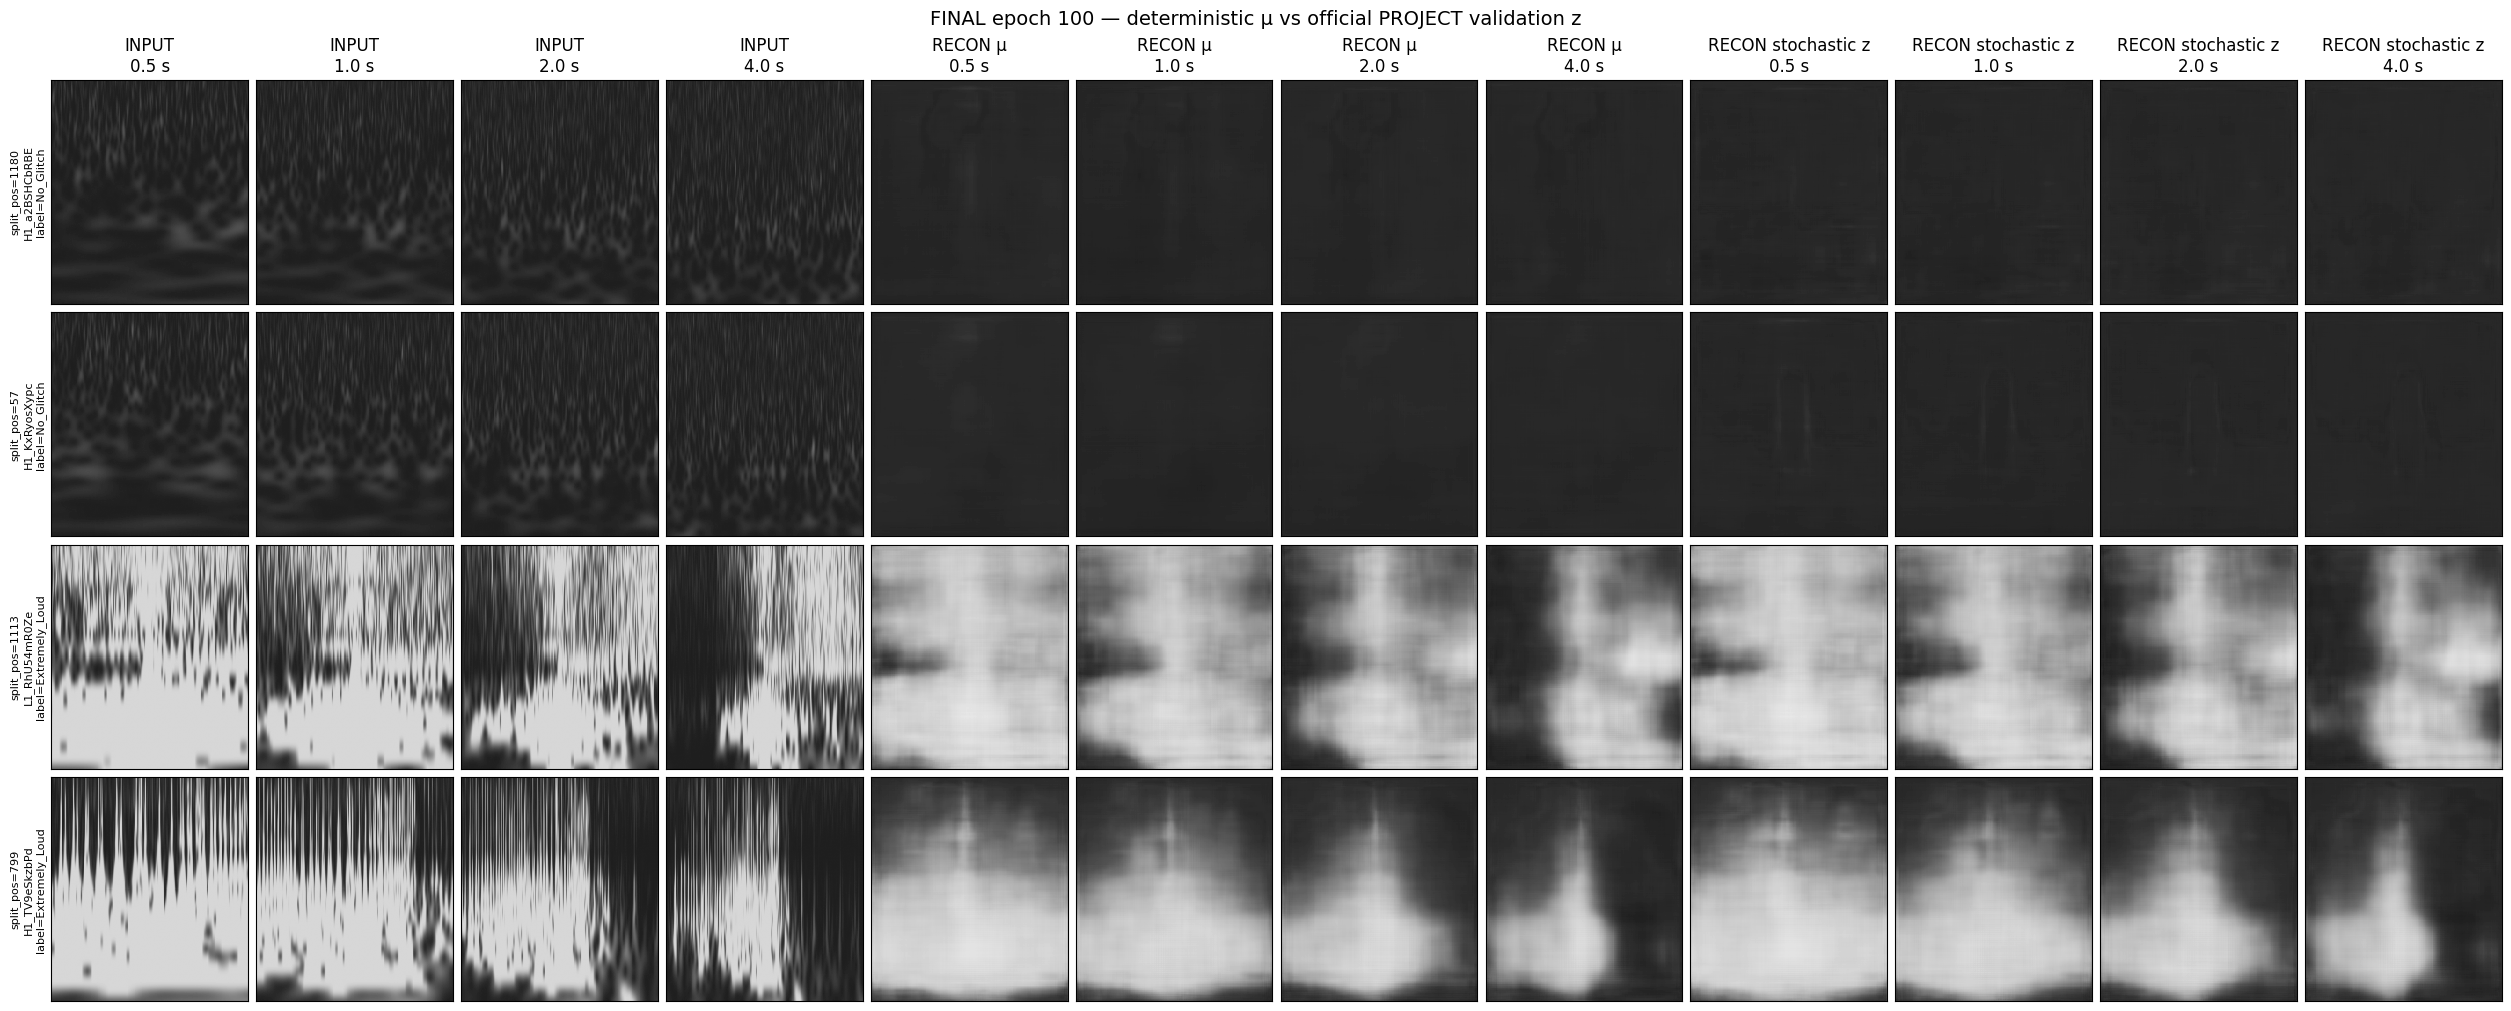


=== NOTEBOOK 04 MU VS STOCHASTIC Z AUDIT ===

LATENT_SEED_GATE = True
VALIDATION_EPSILON_SHA256 = 7bd4a5cab1655ee55d594dedea366f6d05835f539afda33dd1e981b41e7cd438

SAMPLE 0
  split_pos = 1180
  manifest_index = 5906
  label_metadata = No_Glitch
  deterministic BCE/value = 0.427600622177124
  stochastic BCE/value = 0.42753171920776367
  deterministic correlation = 0.013228966854512691
  stochastic correlation = 0.04853750020265579
  deterministic recon std = 0.00643540546298027
  stochastic recon std = 0.005903487093746662

SAMPLE 1
  split_pos = 57
  manifest_index = 5948
  label_metadata = No_Glitch
  deterministic BCE/value = 0.43238773941993713
  stochastic BCE/value = 0.4323081970214844
  deterministic correlation = 0.01418270356953144
  stochastic correlation = 0.03080522082746029
  deterministic recon std = 0.00710967555642128
  stochastic recon std = 0.004881640896201134

SAMPLE 2
  split_pos = 1113
  manifest_index = 2957
  label_metadata = Extremely_Loud
  deterministic BCE/v

In [10]:
# ============================================================
# NOTEBOOK 04 — MU VS OFFICIAL STOCHASTIC Z RECONSTRUCTION
# STEP 04-A4e
#
# Compare:
#   INPUT
#   decoder(mu)
#   decoder(mu + sigma * official_validation_epsilon)
#
# Uses EXACT PROJECT validation latent RNG semantics.
#
# NO training.
# NO model update.
# NO Drive writes.
# ============================================================

import math
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F


# ============================================================
# EXACT PROJECT LATENT RNG
# ============================================================

MASK64 = (
    (1 << 64) - 1
)

MIX_GAMMA = (
    0x9E3779B97F4A7C15
)

MIX_MUL1 = (
    0xBF58476D1CE4E5B9
)

MIX_MUL2 = (
    0x94D049BB133111EB
)

DERIVE_XOR = (
    0xD1B54A32D192ED03
)

SPLITMIX_GAMMA = MIX_GAMMA
SPLITMIX_MUL1 = MIX_MUL1
SPLITMIX_MUL2 = MIX_MUL2

PROJECT_LATENT_SEED = 456

RNG_DOMAIN_LATENT_VALIDATION = 5

TWO_PI = (
    6.283185307179586476925286766559
)


def c_mix64(value):

    value = (
        value
        + MIX_GAMMA
    ) & MASK64

    value = (
        (
            value
            ^ (value >> 30)
        )
        * MIX_MUL1
    ) & MASK64

    value = (
        (
            value
            ^ (value >> 27)
        )
        * MIX_MUL2
    ) & MASK64

    return (
        value
        ^ (value >> 31)
    ) & MASK64


def c_derive_seed(
    base_seed,
    domain,
    epoch,
    manifest_index,
    stream_index,
):

    state = c_mix64(
        base_seed
        ^ DERIVE_XOR
    )

    state = c_mix64(
        state
        ^ int(domain)
    )

    state = c_mix64(
        state
        ^ int(epoch)
    )

    state = c_mix64(
        state
        ^ int(manifest_index)
    )

    state = c_mix64(
        state
        ^ int(stream_index)
    )

    return state


def c_next_u64(state):

    state = (
        state
        + SPLITMIX_GAMMA
    ) & MASK64

    value = state

    value = (
        (
            value
            ^ (value >> 30)
        )
        * SPLITMIX_MUL1
    ) & MASK64

    value = (
        (
            value
            ^ (value >> 27)
        )
        * SPLITMIX_MUL2
    ) & MASK64

    value = (
        value
        ^ (value >> 31)
    ) & MASK64

    return (
        state,
        value,
    )


def python_latent_epsilon(
    base_seed,
    domain,
    epoch,
    manifest_index,
    count,
):

    state = c_derive_seed(
        base_seed,
        domain,
        epoch,
        manifest_index,
        0,
    )


    output = np.empty(
        count,
        dtype=np.float32,
    )


    for index in range(
        count
    ):

        state, random1 = (
            c_next_u64(
                state
            )
        )

        state, random2 = (
            c_next_u64(
                state
            )
        )


        uniform1 = (
            float(
                random1 >> 12
            )
            + 0.5
        ) / 4503599627370496.0


        uniform2 = (
            float(
                random2 >> 12
            )
            + 0.5
        ) / 4503599627370496.0


        radius = math.sqrt(
            -2.0
            * math.log(
                uniform1
            )
        )


        angle = (
            TWO_PI
            * uniform2
        )


        output[
            index
        ] = np.float32(
            radius
            * math.cos(
                angle
            )
        )


    return output


# ============================================================
# GOLDEN PROJECT RNG GATE
# ============================================================

latent_seed_gate = (
    c_derive_seed(
        456,
        RNG_DOMAIN_LATENT_VALIDATION,
        0,
        42,
        0,
    )
    == 0xB849E85BFE7894E7
)


assert latent_seed_gate


# ============================================================
# SELECT FOUR DIFFICULT CASES, LABEL-BLIND
#
# 2 lowest-correlation
# 2 highest-BCE
# ============================================================

A4E_SELECTION = (
    LOW_CORRELATION_SELECTION[:2]
    + HIGH_BCE_SELECTION[:2]
)


assert len(
    A4E_SELECTION
) == 4


selected_samples = [
    validation_central_dataset[
        row[
            "split_pos"
        ]
    ]

    for row
    in A4E_SELECTION
]


x_cpu = torch.stack(
    [
        sample["x"]
        for sample
        in selected_samples
    ],
    dim=0,
)


x = x_cpu.to(
    runtime_device,
    dtype=torch.float32,
)


# ============================================================
# OFFICIAL VALIDATION EPSILON
# ============================================================

epsilon_np = np.stack(
    [
        python_latent_epsilon(
            PROJECT_LATENT_SEED,
            RNG_DOMAIN_LATENT_VALIDATION,
            0,
            sample[
                "manifest_index"
            ],
            512,
        )

        for sample
        in selected_samples
    ],
    axis=0,
)


epsilon = torch.from_numpy(
    epsilon_np
).to(
    runtime_device
)


epsilon_sha256 = (
    hashlib.sha256(
        epsilon_np.tobytes(
            order="C"
        )
    ).hexdigest()
)


# ============================================================
# MODEL STATE BEFORE
# ============================================================

official_final_model.eval()


state_before = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


assert (
    state_before
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


# ============================================================
# ENCODE ONCE
# ============================================================

with torch.inference_mode():

    mu, logvar = (
        official_final_model.encode(
            x
        )
    )


    # -----------------------------------------------
    # DETERMINISTIC PROJECT PATH
    # -----------------------------------------------

    z_mu = mu


    logits_mu = (
        official_final_model.decode(
            z_mu
        )
    )


    recon_mu = torch.sigmoid(
        logits_mu
    )


    # -----------------------------------------------
    # OFFICIAL STOCHASTIC VALIDATION PATH
    # -----------------------------------------------

    sigma = torch.exp(
        0.5
        * logvar
    )


    z_stochastic = (
        mu
        + sigma
        * epsilon
    )


    logits_stochastic = (
        official_final_model.decode(
            z_stochastic
        )
    )


    recon_stochastic = (
        torch.sigmoid(
            logits_stochastic
        )
    )


torch.cuda.synchronize()


# ============================================================
# METRICS
# ============================================================

PIXEL_COUNT = (
    4 * 224 * 224
)


def reconstruction_metrics(
    logits,
    reconstruction,
    target,
):

    bce = (
        F.binary_cross_entropy_with_logits(
            logits,
            target,
            reduction="none",
        )
        .flatten(start_dim=1)
        .sum(dim=1)
        / PIXEL_COUNT
    )


    target_flat = (
        target.flatten(
            start_dim=1
        )
    )


    reconstruction_flat = (
        reconstruction.flatten(
            start_dim=1
        )
    )


    target_centered = (
        target_flat
        - target_flat.mean(
            dim=1,
            keepdim=True,
        )
    )


    reconstruction_centered = (
        reconstruction_flat
        - reconstruction_flat.mean(
            dim=1,
            keepdim=True,
        )
    )


    numerator = (
        target_centered
        * reconstruction_centered
    ).sum(
        dim=1
    )


    denominator = torch.sqrt(

        target_centered.square()
        .sum(dim=1)

        *

        reconstruction_centered.square()
        .sum(dim=1)

    ).clamp_min(
        1.0e-12
    )


    correlation = (
        numerator
        / denominator
    )


    reconstruction_std = (
        reconstruction_flat.std(
            dim=1,
            unbiased=False,
        )
    )


    return (
        bce,
        correlation,
        reconstruction_std,
    )


(
    bce_mu,
    corr_mu,
    std_mu,
) = reconstruction_metrics(
    logits_mu,
    recon_mu,
    x,
)


(
    bce_stochastic,
    corr_stochastic,
    std_stochastic,
) = reconstruction_metrics(
    logits_stochastic,
    recon_stochastic,
    x,
)


# ============================================================
# NUMERIC GATE
# ============================================================

numeric_gate = all([
    torch.isfinite(mu)
        .all().item(),

    torch.isfinite(logvar)
        .all().item(),

    torch.isfinite(epsilon)
        .all().item(),

    torch.isfinite(recon_mu)
        .all().item(),

    torch.isfinite(recon_stochastic)
        .all().item(),

    torch.isfinite(bce_mu)
        .all().item(),

    torch.isfinite(bce_stochastic)
        .all().item(),

    torch.isfinite(corr_mu)
        .all().item(),

    torch.isfinite(corr_stochastic)
        .all().item(),
])


assert numeric_gate


# ============================================================
# MOVE VISUAL DATA TO CPU
# ============================================================

recon_mu_cpu = (
    recon_mu.cpu()
)

recon_stochastic_cpu = (
    recon_stochastic.cpu()
)


bce_mu_cpu = (
    bce_mu.cpu()
)

bce_stochastic_cpu = (
    bce_stochastic.cpu()
)

corr_mu_cpu = (
    corr_mu.cpu()
)

corr_stochastic_cpu = (
    corr_stochastic.cpu()
)

std_mu_cpu = (
    std_mu.cpu()
)

std_stochastic_cpu = (
    std_stochastic.cpu()
)


# ============================================================
# VISUAL COMPARISON
#
# Columns:
#
#   0..3   INPUT
#   4..7   decoder(mu)
#   8..11  decoder(z stochastic)
#
# Same fixed [0,1] scale.
# ============================================================

durations = [
    "0.5 s",
    "1.0 s",
    "2.0 s",
    "4.0 s",
]


figure, axes = plt.subplots(
    nrows=4,
    ncols=12,
    figsize=(25, 10),
    constrained_layout=True,
)


for row_index in range(4):

    for channel_index in range(4):

        panels = [

            (
                x_cpu[
                    row_index,
                    channel_index
                ],
                channel_index,
            ),

            (
                recon_mu_cpu[
                    row_index,
                    channel_index
                ],
                channel_index + 4,
            ),

            (
                recon_stochastic_cpu[
                    row_index,
                    channel_index
                ],
                channel_index + 8,
            ),
        ]


        for image, column_index in panels:

            axis = axes[
                row_index,
                column_index
            ]


            axis.imshow(
                image,
                cmap="gray",
                vmin=0.0,
                vmax=1.0,
                origin="upper",
                interpolation="nearest",
                aspect="auto",
            )


            axis.set_xticks([])
            axis.set_yticks([])


    sample = (
        selected_samples[
            row_index
        ]
    )


    axes[
        row_index,
        0
    ].set_ylabel(
        (
            f"split_pos={sample['split_pos']}\n"
            f"{sample['event_id']}\n"
            f"label={sample['label']}"
        ),
        fontsize=8,
    )


for channel_index, duration in enumerate(
    durations
):

    axes[
        0,
        channel_index
    ].set_title(
        f"INPUT\n{duration}"
    )


    axes[
        0,
        channel_index + 4
    ].set_title(
        f"RECON μ\n{duration}"
    )


    axes[
        0,
        channel_index + 8
    ].set_title(
        f"RECON stochastic z\n{duration}"
    )


figure.suptitle(
    (
        "FINAL epoch 100 — "
        "deterministic μ vs official PROJECT validation z"
    ),
    fontsize=14,
)


plt.show()
plt.close(
    figure
)


# ============================================================
# MODEL IMMUTABILITY
# ============================================================

state_after = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


state_preserved_gate = (
    state_before
    == state_after
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


assert state_preserved_gate


# ============================================================
# REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 MU VS STOCHASTIC Z AUDIT ==="
)

print()

print(
    "LATENT_SEED_GATE =",
    latent_seed_gate,
)

print(
    "VALIDATION_EPSILON_SHA256 =",
    epsilon_sha256,
)

print()


for index, sample in enumerate(
    selected_samples
):

    print(
        f"SAMPLE {index}"
    )

    print(
        "  split_pos =",
        sample[
            "split_pos"
        ],
    )

    print(
        "  manifest_index =",
        sample[
            "manifest_index"
        ],
    )

    print(
        "  label_metadata =",
        sample[
            "label"
        ],
    )

    print(
        "  deterministic BCE/value =",
        float(
            bce_mu_cpu[
                index
            ]
        ),
    )

    print(
        "  stochastic BCE/value =",
        float(
            bce_stochastic_cpu[
                index
            ]
        ),
    )

    print(
        "  deterministic correlation =",
        float(
            corr_mu_cpu[
                index
            ]
        ),
    )

    print(
        "  stochastic correlation =",
        float(
            corr_stochastic_cpu[
                index
            ]
        ),
    )

    print(
        "  deterministic recon std =",
        float(
            std_mu_cpu[
                index
            ]
        ),
    )

    print(
        "  stochastic recon std =",
        float(
            std_stochastic_cpu[
                index
            ]
        ),
    )

    print()


print(
    "NUMERIC_GATE =",
    numeric_gate,
)

print(
    "MODEL_STATE_PRESERVED_GATE =",
    state_preserved_gate,
)

print()

print(
    "LABELS_USED_FOR_SELECTION =",
    False,
)

print(
    "MODEL_UPDATED =",
    False,
)

print(
    "OFFICIAL_DRIVE_ARTIFACTS_MODIFIED =",
    False,
)

print()

print(
    "NOTEBOOK_04_MU_VS_STOCHASTIC_Z_PASS =",
    (
        latent_seed_gate
        and numeric_gate
        and state_preserved_gate
    ),
)

### Risultato del confronto

Le ricostruzioni ottenute usando il campione stocastico \(z_{\mathrm{val}}\)
sono molto simili a quelle ottenute con \(z=\mu_\phi(x)\).

Non emerge un miglioramento sistematico della BCE, della correlazione o del
contrasto passando dalla ricostruzione deterministica a quella stocastica.

Pertanto, lo smoothing osservato nelle ricostruzioni non può essere spiegato
semplicemente dall'utilizzo della media latente \(\mu_\phi(x)\).

## STEP 04-A5b — Audit dello spazio latente a 512 dimensioni

Il VAE `FINAL` produce per ogni evento una media latente

$$
\mu_\phi(x)\in\mathbb{R}^{512}
$$

e un vettore

$$
\log\sigma_\phi^2(x)\in\mathbb{R}^{512}.
$$

Nel paper di Sakai et al., la feature utilizzata successivamente dall'IIC è
proprio la media dell'encoder:

$$
z=\mu_\phi(x),
\qquad
z'=\mu_\phi(x').
$$

Prima di congelare gli embedding del nostro `sakai224_full`, viene quindi
verificato che lo spazio nominalmente a 512 dimensioni non sia degenerato
in una rappresentazione quasi costante o concentrata in pochissime direzioni.

Per ogni dimensione latente $j$ viene calcolata la varianza della media:

$$
V_j
=
\operatorname{Var}_{x}
\left[
\mu_{\phi,j}(x)
\right].
$$

Viene inoltre calcolato il contributo medio della singola dimensione alla
divergenza KL:

$$
\overline{D_{\mathrm{KL},j}}
=
\frac{1}{N}
\sum_{i=1}^{N}
\frac{1}{2}
\left[
\mu_{i,j}^{2}
+
\exp\left(\log\sigma_{i,j}^{2}\right)
-
1
-
\log\sigma_{i,j}^{2}
\right].
$$

La divergenza KL media totale per campione è quindi:

$$
\overline{D_{\mathrm{KL}}}
=
\sum_{j=1}^{512}
\overline{D_{\mathrm{KL},j}}.
$$

Viene poi studiata la matrice di covarianza delle medie latenti del training:

$$
C_\mu
=
\frac{1}{N_{\mathrm{train}}}
\sum_{i=1}^{N_{\mathrm{train}}}
\left(
\mu_i-\bar{\mu}
\right)
\left(
\mu_i-\bar{\mu}
\right)^{\mathsf T}.
$$

Indicando con

$$
\lambda_1\geq\lambda_2\geq\cdots\geq\lambda_{512}\geq0
$$

gli autovalori della matrice di covarianza, vengono calcolate anche due
misure diagnostiche della dimensionalità effettiva.

L'effective rank entropico è:

$$
r_{\mathrm{eff}}
=
\exp
\left(
-\sum_j p_j\log p_j
\right),
$$

dove

$$
p_j
=
\frac{\lambda_j}
{\sum_k\lambda_k}.
$$

Viene inoltre calcolato il participation ratio:

$$
r_{\mathrm{PR}}
=
\frac{
\left(\sum_j\lambda_j\right)^2
}{
\sum_j\lambda_j^2
}.
$$

Queste quantità **non sono metriche pubblicate da Sakai** e non vengono
utilizzate per modificare il modello. Sono diagnostiche PROJECT introdotte
per verificare la qualità numerica della rappresentazione prima di clustering
e IIC.

Non viene applicata PCA: lo spettro della covarianza viene soltanto analizzato.
Gli embedding restano invariati in $\mathbb{R}^{512}$.

In [11]:
# ============================================================
# NOTEBOOK 04 — LATENT SPACE HEALTH AUDIT
# STEP 04-A5b
#
# Uses A5a outputs already in RAM:
#   train_mu, train_logvar
#   validation_mu, validation_logvar
#
# Diagnostics only.
#
# NO PCA.
# NO standardization.
# NO clustering.
# NO labels.
# NO model forward.
# NO Drive writes.
# ============================================================

import csv
import hashlib

import numpy as np


# ============================================================
# PRECONDITIONS
# ============================================================

assert train_mu.shape == (
    6866,
    512,
)

assert train_logvar.shape == (
    6866,
    512,
)

assert validation_mu.shape == (
    1717,
    512,
)

assert validation_logvar.shape == (
    1717,
    512,
)


assert train_mu.dtype == np.float32
assert train_logvar.dtype == np.float32

assert validation_mu.dtype == np.float32
assert validation_logvar.dtype == np.float32


# ============================================================
# PROMOTE TO FLOAT64 ONLY FOR STATISTICAL DIAGNOSTICS
#
# Embeddings themselves remain float32 and untouched.
# ============================================================

train_mu64 = train_mu.astype(
    np.float64,
    copy=False,
)

train_logvar64 = train_logvar.astype(
    np.float64,
    copy=False,
)

validation_mu64 = validation_mu.astype(
    np.float64,
    copy=False,
)

validation_logvar64 = validation_logvar.astype(
    np.float64,
    copy=False,
)


# ============================================================
# BASIC FINITE CONTRACT
# ============================================================

input_numeric_gate = (
    np.isfinite(
        train_mu64
    ).all()

    and np.isfinite(
        train_logvar64
    ).all()

    and np.isfinite(
        validation_mu64
    ).all()

    and np.isfinite(
        validation_logvar64
    ).all()
)


assert input_numeric_gate


# ============================================================
# PER-DIMENSION MU STATISTICS
# ============================================================

train_mu_mean = np.mean(
    train_mu64,
    axis=0,
)

train_mu_variance = np.var(
    train_mu64,
    axis=0,
    ddof=0,
)


validation_mu_mean = np.mean(
    validation_mu64,
    axis=0,
)

validation_mu_variance = np.var(
    validation_mu64,
    axis=0,
    ddof=0,
)


# ============================================================
# PER-DIMENSION KL
#
# KL_j =
# 0.5 * (
#     mu_j^2
#     + exp(logvar_j)
#     - 1
#     - logvar_j
# )
#
# expm1(logvar) = exp(logvar) - 1
# ============================================================

with np.errstate(
    over="raise",
    invalid="raise",
):

    train_kl_matrix = (
        0.5
        * (
            np.square(
                train_mu64
            )
            + np.expm1(
                train_logvar64
            )
            - train_logvar64
        )
    )


    validation_kl_matrix = (
        0.5
        * (
            np.square(
                validation_mu64
            )
            + np.expm1(
                validation_logvar64
            )
            - validation_logvar64
        )
    )


train_kl_mean_per_dimension = (
    np.mean(
        train_kl_matrix,
        axis=0,
    )
)


validation_kl_mean_per_dimension = (
    np.mean(
        validation_kl_matrix,
        axis=0,
    )
)


train_mean_kl_per_sample = float(
    np.sum(
        train_kl_mean_per_dimension
    )
)


validation_mean_kl_per_sample = float(
    np.sum(
        validation_kl_mean_per_dimension
    )
)


# ============================================================
# MEAN POSTERIOR VARIANCE PER DIMENSION
#
# sigma^2 = exp(logvar)
# ============================================================

with np.errstate(
    over="raise",
    invalid="raise",
):

    train_mean_posterior_variance = (
        np.mean(
            np.exp(
                train_logvar64
            ),
            axis=0,
        )
    )


    validation_mean_posterior_variance = (
        np.mean(
            np.exp(
                validation_logvar64
            ),
            axis=0,
        )
    )


# ============================================================
# NUMERIC GATE AFTER STATISTICS
# ============================================================

per_dimension_numeric_gate = all([
    np.isfinite(
        train_mu_mean
    ).all(),

    np.isfinite(
        train_mu_variance
    ).all(),

    np.isfinite(
        validation_mu_mean
    ).all(),

    np.isfinite(
        validation_mu_variance
    ).all(),

    np.isfinite(
        train_kl_mean_per_dimension
    ).all(),

    np.isfinite(
        validation_kl_mean_per_dimension
    ).all(),

    np.isfinite(
        train_mean_posterior_variance
    ).all(),

    np.isfinite(
        validation_mean_posterior_variance
    ).all(),
])


assert per_dimension_numeric_gate


# ============================================================
# TRAIN COVARIANCE OF MU
#
# Population convention ddof = 0.
# This is diagnostic only; no PCA transform is applied.
# ============================================================

train_mu_centered = (
    train_mu64
    - train_mu_mean
)


train_mu_covariance = (
    train_mu_centered.T
    @ train_mu_centered
) / float(
    train_mu64.shape[0]
)


covariance_symmetry_gate = np.allclose(
    train_mu_covariance,
    train_mu_covariance.T,
    rtol=0.0,
    atol=1.0e-12,
)


assert covariance_symmetry_gate


# ============================================================
# COVARIANCE SPECTRUM
# ============================================================

raw_eigenvalues = np.linalg.eigvalsh(
    train_mu_covariance
)


raw_min_eigenvalue = float(
    raw_eigenvalues[0]
)


raw_max_eigenvalue = float(
    raw_eigenvalues[-1]
)


eigenvalue_tolerance = max(
    1.0e-12,
    abs(
        raw_max_eigenvalue
    )
    * 1.0e-10,
)


covariance_psd_gate = (
    raw_min_eigenvalue
    >= -eigenvalue_tolerance
)


assert covariance_psd_gate


# Remove only tiny numerical negatives produced by eigensolver.
eigenvalues = np.clip(
    raw_eigenvalues,
    0.0,
    None,
)


eigenvalues_descending = (
    eigenvalues[::-1]
)


total_latent_variance = float(
    np.sum(
        eigenvalues_descending
    )
)


nonzero_variance_gate = (
    total_latent_variance
    > 0.0
)


assert nonzero_variance_gate


# ============================================================
# NORMALIZED SPECTRUM
# ============================================================

eigenvalue_probabilities = (
    eigenvalues_descending
    / total_latent_variance
)


positive_probabilities = (
    eigenvalue_probabilities[
        eigenvalue_probabilities
        > 0.0
    ]
)


effective_rank_entropy = float(
    np.exp(
        -np.sum(
            positive_probabilities
            * np.log(
                positive_probabilities
            )
        )
    )
)


participation_ratio = float(
    total_latent_variance ** 2
    / np.sum(
        np.square(
            eigenvalues_descending
        )
    )
)


# ============================================================
# CUMULATIVE VARIANCE DIMENSIONS
#
# Descriptive diagnostics only.
# No dimensionality reduction is applied.
# ============================================================

cumulative_variance_fraction = (
    np.cumsum(
        eigenvalues_descending
    )
    / total_latent_variance
)


def dimensions_for_fraction(
    fraction,
):

    return int(
        np.searchsorted(
            cumulative_variance_fraction,
            fraction,
            side="left",
        )
        + 1
    )


dimensions_90 = (
    dimensions_for_fraction(
        0.90
    )
)

dimensions_95 = (
    dimensions_for_fraction(
        0.95
    )
)

dimensions_99 = (
    dimensions_for_fraction(
        0.99
    )
)


# ============================================================
# NUMERICAL COVARIANCE RANK
#
# PROJECT diagnostic threshold relative to largest eigenvalue.
# Not a Sakai metric.
# ============================================================

numerical_rank_threshold = (
    raw_max_eigenvalue
    * 1.0e-12
)


numerical_covariance_rank = int(
    np.sum(
        eigenvalues_descending
        > numerical_rank_threshold
    )
)


# ============================================================
# TRAIN / VALIDATION CONSISTENCY
#
# Descriptive only.
# ============================================================

variance_profile_correlation = float(
    np.corrcoef(
        train_mu_variance,
        validation_mu_variance,
    )[0, 1]
)


kl_profile_correlation = float(
    np.corrcoef(
        train_kl_mean_per_dimension,
        validation_kl_mean_per_dimension,
    )[0, 1]
)


latent_centroid_shift_l2 = float(
    np.linalg.norm(
        validation_mu_mean
        - train_mu_mean
    )
)


train_latent_rms_scale = float(
    np.sqrt(
        np.sum(
            train_mu_variance
        )
    )
)


centroid_shift_relative_to_train_scale = float(
    latent_centroid_shift_l2
    / train_latent_rms_scale
)


# ============================================================
# PER-EVENT MU NORM
# ============================================================

train_mu_l2 = np.linalg.norm(
    train_mu64,
    axis=1,
)


validation_mu_l2 = np.linalg.norm(
    validation_mu64,
    axis=1,
)


# ============================================================
# DESCRIPTIVE THRESHOLD COUNTS
#
# IMPORTANT:
# These thresholds are PROJECT diagnostics.
# They are NOT published Sakai criteria and are NOT pass/fail.
# ============================================================

MU_VARIANCE_THRESHOLDS = [
    1.0e-6,
    1.0e-4,
    1.0e-2,
]


KL_THRESHOLDS = [
    1.0e-4,
    1.0e-3,
    1.0e-2,
    1.0e-1,
]


mu_variance_threshold_counts = {
    threshold: int(
        np.sum(
            train_mu_variance
            > threshold
        )
    )
    for threshold
    in MU_VARIANCE_THRESHOLDS
}


kl_threshold_counts = {
    threshold: int(
        np.sum(
            train_kl_mean_per_dimension
            > threshold
        )
    )
    for threshold
    in KL_THRESHOLDS
}


# ============================================================
# QUANTILES
# ============================================================

QUANTILES = np.asarray(
    [
        0.00,
        0.01,
        0.05,
        0.25,
        0.50,
        0.75,
        0.95,
        0.99,
        1.00,
    ],
    dtype=np.float64,
)


def quantiles(values):

    return np.quantile(
        np.asarray(
            values,
            dtype=np.float64,
        ),
        QUANTILES,
    )


train_mu_variance_quantiles = quantiles(
    train_mu_variance
)


train_kl_dimension_quantiles = quantiles(
    train_kl_mean_per_dimension
)


train_mu_l2_quantiles = quantiles(
    train_mu_l2
)


validation_mu_l2_quantiles = quantiles(
    validation_mu_l2
)


# ============================================================
# DEGENERACY HARD GATE
#
# This intentionally checks only obvious numerical collapse.
# It does NOT impose an arbitrary required effective rank.
# ============================================================

latent_noncollapse_gate = (
    np.any(
        train_mu_variance
        > 0.0
    )

    and np.any(
        train_kl_mean_per_dimension
        > 0.0
    )

    and effective_rank_entropy
        > 1.0

    and participation_ratio
        > 1.0

    and numerical_covariance_rank
        > 1
)


assert latent_noncollapse_gate


# ============================================================
# MODEL STATE MUST STILL BE FINAL
# ============================================================

state_after_latent_health_audit = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


model_state_preserved_gate = (
    state_after_latent_health_audit
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


assert model_state_preserved_gate


# ============================================================
# LOCAL PER-DIMENSION DIAGNOSTIC CSV
# ============================================================

LATENT_DIAGNOSTIC_CSV = (
    LOCAL_POSTTRAIN_ROOT
    / "latent_dimension_diagnostics_epoch100.csv"
)


with LATENT_DIAGNOSTIC_CSV.open(
    "w",
    newline="",
    encoding="utf-8",
) as handle:

    writer = csv.writer(
        handle
    )


    writer.writerow([
        "latent_dimension",
        "train_mu_mean",
        "train_mu_variance",
        "validation_mu_mean",
        "validation_mu_variance",
        "train_kl_mean",
        "validation_kl_mean",
        "train_mean_posterior_variance",
        "validation_mean_posterior_variance",
    ])


    for dimension in range(
        512
    ):

        writer.writerow([
            dimension,

            float(
                train_mu_mean[
                    dimension
                ]
            ),

            float(
                train_mu_variance[
                    dimension
                ]
            ),

            float(
                validation_mu_mean[
                    dimension
                ]
            ),

            float(
                validation_mu_variance[
                    dimension
                ]
            ),

            float(
                train_kl_mean_per_dimension[
                    dimension
                ]
            ),

            float(
                validation_kl_mean_per_dimension[
                    dimension
                ]
            ),

            float(
                train_mean_posterior_variance[
                    dimension
                ]
            ),

            float(
                validation_mean_posterior_variance[
                    dimension
                ]
            ),
        ])


latent_diagnostic_csv_sha256 = (
    hashlib.sha256(
        LATENT_DIAGNOSTIC_CSV
        .read_bytes()
    ).hexdigest()
)


# ============================================================
# REPORT HELPERS
# ============================================================

def print_quantiles(
    title,
    values,
):

    print(title)

    for level, value in zip(
        QUANTILES,
        values,
    ):

        print(
            f"  q={level:4.2f}:",
            float(value),
        )


# ============================================================
# REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 LATENT SPACE HEALTH AUDIT ==="
)

print()

print(
    "LATENT_DIM = 512"
)

print(
    "CANONICAL_FEATURE = MU"
)

print(
    "PCA_APPLIED =",
    False,
)

print(
    "STANDARDIZATION_APPLIED =",
    False,
)

print()

print(
    "TRAIN_MEAN_KL_PER_SAMPLE =",
    train_mean_kl_per_sample,
)

print(
    "VALIDATION_MEAN_KL_PER_SAMPLE =",
    validation_mean_kl_per_sample,
)

print()

print_quantiles(
    "TRAIN_MU_VARIANCE_PER_DIMENSION_QUANTILES",
    train_mu_variance_quantiles,
)

print()

print_quantiles(
    "TRAIN_KL_PER_DIMENSION_QUANTILES",
    train_kl_dimension_quantiles,
)

print()

print_quantiles(
    "TRAIN_MU_L2_QUANTILES",
    train_mu_l2_quantiles,
)

print()

print_quantiles(
    "VALIDATION_MU_L2_QUANTILES",
    validation_mu_l2_quantiles,
)

print()

print(
    "MU_VARIANCE_THRESHOLD_COUNTS =",
    mu_variance_threshold_counts,
)

print(
    "KL_THRESHOLD_COUNTS =",
    kl_threshold_counts,
)

print()

print(
    "COVARIANCE_TRACE_TOTAL_VARIANCE =",
    total_latent_variance,
)

print(
    "RAW_MIN_COVARIANCE_EIGENVALUE =",
    raw_min_eigenvalue,
)

print(
    "RAW_MAX_COVARIANCE_EIGENVALUE =",
    raw_max_eigenvalue,
)

print()

print(
    "NUMERICAL_COVARIANCE_RANK =",
    numerical_covariance_rank,
)

print(
    "EFFECTIVE_RANK_ENTROPY =",
    effective_rank_entropy,
)

print(
    "PARTICIPATION_RATIO =",
    participation_ratio,
)

print()

print(
    "DIMENSIONS_FOR_90_PERCENT_VARIANCE =",
    dimensions_90,
)

print(
    "DIMENSIONS_FOR_95_PERCENT_VARIANCE =",
    dimensions_95,
)

print(
    "DIMENSIONS_FOR_99_PERCENT_VARIANCE =",
    dimensions_99,
)

print()

print(
    "TRAIN_VALIDATION_VARIANCE_PROFILE_CORRELATION =",
    variance_profile_correlation,
)

print(
    "TRAIN_VALIDATION_KL_PROFILE_CORRELATION =",
    kl_profile_correlation,
)

print()

print(
    "LATENT_CENTROID_SHIFT_L2 =",
    latent_centroid_shift_l2,
)

print(
    "CENTROID_SHIFT_RELATIVE_TO_TRAIN_SCALE =",
    centroid_shift_relative_to_train_scale,
)

print()

print(
    "LOCAL_LATENT_DIAGNOSTIC_CSV =",
    LATENT_DIAGNOSTIC_CSV,
)

print(
    "LOCAL_LATENT_DIAGNOSTIC_CSV_SHA256 =",
    latent_diagnostic_csv_sha256,
)

print()

print(
    "INPUT_NUMERIC_GATE =",
    input_numeric_gate,
)

print(
    "PER_DIMENSION_NUMERIC_GATE =",
    per_dimension_numeric_gate,
)

print(
    "COVARIANCE_SYMMETRY_GATE =",
    covariance_symmetry_gate,
)

print(
    "COVARIANCE_PSD_GATE =",
    covariance_psd_gate,
)

print(
    "NONZERO_VARIANCE_GATE =",
    nonzero_variance_gate,
)

print(
    "LATENT_NONCOLLAPSE_GATE =",
    latent_noncollapse_gate,
)

print(
    "MODEL_STATE_PRESERVED_GATE =",
    model_state_preserved_gate,
)

print()

print(
    "THRESHOLDS_ARE_SAKAI_CRITERIA =",
    False,
)

print(
    "LABELS_USED =",
    False,
)

print(
    "CLUSTERING_EXECUTED =",
    False,
)

print(
    "OFFICIAL_DRIVE_ARTIFACTS_MODIFIED =",
    False,
)

print()

print(
    "NOTEBOOK_04_LATENT_SPACE_HEALTH_PASS =",
    (
        input_numeric_gate
        and per_dimension_numeric_gate
        and covariance_symmetry_gate
        and covariance_psd_gate
        and nonzero_variance_gate
        and latent_noncollapse_gate
        and model_state_preserved_gate
    ),
)


=== NOTEBOOK 04 LATENT SPACE HEALTH AUDIT ===

LATENT_DIM = 512
CANONICAL_FEATURE = MU
PCA_APPLIED = False
STANDARDIZATION_APPLIED = False

TRAIN_MEAN_KL_PER_SAMPLE = 119.3849676066153
VALIDATION_MEAN_KL_PER_SAMPLE = 119.56428545669985

TRAIN_MU_VARIANCE_PER_DIMENSION_QUANTILES
  q=0.00: 0.0217016556720788
  q=0.01: 0.04765677841385323
  q=0.05: 0.07204709864279243
  q=0.25: 0.12094749938883076
  q=0.50: 0.1750566514228616
  q=0.75: 0.277370043289452
  q=0.95: 0.6280365811941172
  q=0.99: 1.4346450360021739
  q=1.00: 3.376661927847248

TRAIN_KL_PER_DIMENSION_QUANTILES
  q=0.00: 0.028000822843333727
  q=0.01: 0.03868009566758695
  q=0.05: 0.05952824686836504
  q=0.25: 0.09833532967839771
  q=0.50: 0.15731973964419232
  q=0.75: 0.25937242749554806
  q=0.95: 0.6849237270303461
  q=0.99: 1.4593258401520308
  q=1.00: 2.47185363277937

TRAIN_MU_L2_QUANTILES
  q=0.00: 4.611076638515039
  q=0.01: 5.622119678902704
  q=0.05: 6.1852273845668835
  q=0.25: 8.030789830105537
  q=0.50: 10.473554854

### Risultato dell'audit dello spazio latente

Secondo le diagnostiche adottate, non emerge evidenza di collasso globale o
completo del posterior; ciò non esclude collasso parziale o uso ineffettivo di
alcune direzioni latenti.

Tutte le 512 coordinate della media latente presentano varianza non nulla e
contributo KL positivo. In particolare:

$$
512/512
$$

dimensioni soddisfano

$$
\operatorname{Var}[\mu_j] > 10^{-2},
$$

e tutte le 512 dimensioni soddisfano

$$
\overline{D_{\mathrm{KL},j}} > 10^{-2}.
$$

I profili train e validation risultano fortemente coerenti:

$$
\rho_{\mathrm{var}}
=
0.99818,
$$

$$
\rho_{\mathrm{KL}}
=
0.99946.
$$

Con la soglia diagnostica PROJECT

$$
\lambda_j > \lambda_{\max} \times 10^{-12},
$$

il rango numerico della covarianza è 511.

Lo spazio latente è tuttavia fortemente correlato. Lo spettro della
covarianza mostra che il 90%, 95% e 99% della varianza sono spiegati
rispettivamente da:

$$
d_{90}=17,
\qquad
d_{95}=21,
\qquad
d_{99}=32.
$$

L'effective rank entropico è:

$$
r_{\mathrm{eff}}
=
18.24,
$$

mentre il participation ratio è:

$$
r_{\mathrm{PR}}
=
11.65.
$$

Questo risultato non implica che soltanto 17–18 delle 512 coordinate siano
attive. Tutte le coordinate mostrano variabilità, ma una parte consistente
della variazione è correlata e concentrata in un numero minore di direzioni
principali.

Sakai et al. non pubblicano lo spettro di covarianza o la dimensionalità
effettiva delle loro feature a 512 dimensioni; queste quantità sono quindi
diagnostiche PROJECT e non possono essere confrontate numericamente con il
paper.

Gli embedding canonici restano invariati:

$$
\mu_\phi(x)\in\mathbb{R}^{512}.
$$

Non viene applicata PCA né alcuna riduzione dimensionale prima della
pubblicazione degli embedding.

## STEP 04-A5c — Pubblicazione canonica degli embedding $\mu$

Gli audit numerici e dello spazio latente sono stati completati; secondo le
diagnostiche adottate, non emerge evidenza di collasso globale o completo.

Vengono quindi congelate le feature deterministiche prodotte dall'encoder
`FINAL` dopo 100 epoche:

$$
e(x)=\mu_\phi(x)\in\mathbb{R}^{512}.
$$

Gli artefatti principali sono:

$$
M_{\mu}^{\mathrm{train}}
\in
\mathbb{R}^{6866\times512},
$$

e

$$
M_{\mu}^{\mathrm{validation}}
\in
\mathbb{R}^{1717\times512}.
$$

Le matrici vengono salvate in formato binario semplice:

- `float32`;
- little-endian;
- row-major;
- una riga per evento;
- 512 valori consecutivi per evento.

Non viene applicata alcuna trasformazione:

$$
M_{\mathrm{export}}
=
M_\mu.
$$

In particolare:

$$
\mathrm{PCA}=\mathrm{False},
$$

$$
\mathrm{standardizzazione}=\mathrm{False}.
$$

Gli stessi embedding potranno quindi essere letti senza ambiguità sia dal
ramo Python/PyTorch della replica `sakai224_full`, sia dal backend C usato
per il confronto comune con `mini75`, `mini112` e `mini224_1000`.

Le row-map contengono esclusivamente identità e posizione degli eventi.
Le label Gravity Spy non vengono incluse nell'artefatto degli embedding:
sono recuperate separatamente soltanto nella valutazione a posteriori
del clustering.

In [12]:
# ============================================================
# NOTEBOOK 04 — CANONICAL MU EMBEDDING PUBLICATION
# STEP 04-A5c
#
# Persistent scientific write.
#
# Publishes FINAL epoch-100 raw mu embeddings atomically.
#
# NO PCA.
# NO standardization.
# NO labels.
# NO clustering.
# ============================================================

from pathlib import Path

import csv
import hashlib
import json
import os
import shutil


# ============================================================
# FROZEN EXPORT CONTRACT
# ============================================================

EMBEDDING_ARTIFACT_NAME = (
    "sakai224_full_mu_epoch100_v1"
)

EMBEDDINGS_ROOT = (
    SAKAI224_ROOT
    / "embeddings"
)

FINAL_EMBEDDING_DIR = (
    EMBEDDINGS_ROOT
    / EMBEDDING_ARTIFACT_NAME
)

PARTIAL_EMBEDDING_DIR = (
    EMBEDDINGS_ROOT
    / (
        EMBEDDING_ARTIFACT_NAME
        + ".partial"
    )
)


TRAIN_BIN_NAME = (
    "embeddings_mu_train_f32.bin"
)

VALIDATION_BIN_NAME = (
    "embeddings_mu_validation_f32.bin"
)

TRAIN_ROW_MAP_NAME = (
    "row_map_train.csv"
)

VALIDATION_ROW_MAP_NAME = (
    "row_map_validation.csv"
)

METADATA_NAME = (
    "metadata.json"
)

SHA256SUMS_NAME = (
    "SHA256SUMS.txt"
)


EXPECTED_TRAIN_MU_SHA256 = (
    "b620fd9711719a7bd40293b6536ea6fe"
    "b235cbadb1d1e37dca0e46651332ad5e"
)

EXPECTED_VALIDATION_MU_SHA256 = (
    "c1692b3e7a4c86a7f4d6d7172117e110"
    "83d2bd2394947838a24d1e2b81f27cf9"
)


# ============================================================
# PRE-PUBLICATION CONTRACT
# ============================================================

assert train_mu.shape == (
    6866,
    512,
)

assert validation_mu.shape == (
    1717,
    512,
)

assert train_mu.dtype == np.float32
assert validation_mu.dtype == np.float32

assert train_mu.flags[
    "C_CONTIGUOUS"
]

assert validation_mu.flags[
    "C_CONTIGUOUS"
]

assert np.isfinite(
    train_mu
).all()

assert np.isfinite(
    validation_mu
).all()


train_memory_sha = hashlib.sha256(
    train_mu.tobytes(
        order="C"
    )
).hexdigest()


validation_memory_sha = hashlib.sha256(
    validation_mu.tobytes(
        order="C"
    )
).hexdigest()


prepublication_hash_gate = (
    train_memory_sha
        == EXPECTED_TRAIN_MU_SHA256

    and validation_memory_sha
        == EXPECTED_VALIDATION_MU_SHA256
)


assert prepublication_hash_gate


# ============================================================
# DO NOT OVERWRITE A PREVIOUS SCIENTIFIC PUBLICATION
# ============================================================

EMBEDDINGS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


if FINAL_EMBEDDING_DIR.exists():

    raise RuntimeError(
        "STOP: canonical embedding artifact already exists: "
        f"{FINAL_EMBEDDING_DIR}"
    )


if PARTIAL_EMBEDDING_DIR.exists():

    shutil.rmtree(
        PARTIAL_EMBEDDING_DIR
    )


PARTIAL_EMBEDDING_DIR.mkdir(
    parents=False,
    exist_ok=False,
)


# ============================================================
# OUTPUT PATHS
# ============================================================

TRAIN_BIN_PATH = (
    PARTIAL_EMBEDDING_DIR
    / TRAIN_BIN_NAME
)

VALIDATION_BIN_PATH = (
    PARTIAL_EMBEDDING_DIR
    / VALIDATION_BIN_NAME
)

TRAIN_ROW_MAP_PATH = (
    PARTIAL_EMBEDDING_DIR
    / TRAIN_ROW_MAP_NAME
)

VALIDATION_ROW_MAP_PATH = (
    PARTIAL_EMBEDDING_DIR
    / VALIDATION_ROW_MAP_NAME
)

METADATA_PATH = (
    PARTIAL_EMBEDDING_DIR
    / METADATA_NAME
)

SHA256SUMS_PATH = (
    PARTIAL_EMBEDDING_DIR
    / SHA256SUMS_NAME
)


# ============================================================
# WRITE RAW FLOAT32 ROW-MAJOR MATRICES
# ============================================================

train_mu.astype(
    "<f4",
    copy=False,
).tofile(
    TRAIN_BIN_PATH
)


validation_mu.astype(
    "<f4",
    copy=False,
).tofile(
    VALIDATION_BIN_PATH
)


# ============================================================
# ROW MAP WRITER
#
# LABELS DELIBERATELY EXCLUDED.
# ============================================================

ROW_MAP_FIELDS = [
    "split",
    "split_pos",
    "manifest_index",
    "event_index",
    "event_id",
]


def write_row_map(
    path,
    latent_info,
):

    with path.open(
        "w",
        newline="",
        encoding="utf-8",
    ) as handle:

        writer = csv.DictWriter(
            handle,
            fieldnames=ROW_MAP_FIELDS,
            lineterminator="\n",
        )

        writer.writeheader()


        count = len(
            latent_info[
                "event_ids"
            ]
        )


        for index in range(
            count
        ):

            writer.writerow({
                "split":
                    latent_info[
                        "split"
                    ],

                "split_pos":
                    int(
                        latent_info[
                            "split_positions"
                        ][index]
                    ),

                "manifest_index":
                    int(
                        latent_info[
                            "manifest_indices"
                        ][index]
                    ),

                "event_index":
                    int(
                        latent_info[
                            "event_indices"
                        ][index]
                    ),

                "event_id":
                    latent_info[
                        "event_ids"
                    ][index],
            })


write_row_map(
    TRAIN_ROW_MAP_PATH,
    train_latent,
)


write_row_map(
    VALIDATION_ROW_MAP_PATH,
    validation_latent,
)


# ============================================================
# FILE SHA HELPER
# ============================================================

def embedding_sha256_file(
    path,
):

    digest = hashlib.sha256()

    with path.open(
        "rb"
    ) as handle:

        while True:

            block = handle.read(
                8 * 1024 * 1024
            )

            if not block:
                break

            digest.update(
                block
            )

    return digest.hexdigest()


# ============================================================
# VERIFY BINARY ROUNDTRIP
# ============================================================

train_file_sha = (
    embedding_sha256_file(
        TRAIN_BIN_PATH
    )
)

validation_file_sha = (
    embedding_sha256_file(
        VALIDATION_BIN_PATH
    )
)


binary_hash_gate = (
    train_file_sha
        == EXPECTED_TRAIN_MU_SHA256

    and validation_file_sha
        == EXPECTED_VALIDATION_MU_SHA256
)


assert binary_hash_gate


expected_train_bytes = (
    6866
    * 512
    * 4
)

expected_validation_bytes = (
    1717
    * 512
    * 4
)


binary_size_gate = (
    TRAIN_BIN_PATH.stat().st_size
        == expected_train_bytes

    and VALIDATION_BIN_PATH.stat().st_size
        == expected_validation_bytes
)


assert binary_size_gate


train_roundtrip = np.fromfile(
    TRAIN_BIN_PATH,
    dtype="<f4",
).reshape(
    6866,
    512,
)


validation_roundtrip = np.fromfile(
    VALIDATION_BIN_PATH,
    dtype="<f4",
).reshape(
    1717,
    512,
)


binary_roundtrip_gate = (
    np.array_equal(
        train_roundtrip,
        train_mu
    )

    and np.array_equal(
        validation_roundtrip,
        validation_mu
    )
)


assert binary_roundtrip_gate


del train_roundtrip
del validation_roundtrip


# ============================================================
# ROW MAP AUDIT
# ============================================================

def read_row_map(
    path,
):

    with path.open(
        "r",
        newline="",
        encoding="utf-8",
    ) as handle:

        return list(
            csv.DictReader(
                handle
            )
        )


train_row_map = read_row_map(
    TRAIN_ROW_MAP_PATH
)

validation_row_map = read_row_map(
    VALIDATION_ROW_MAP_PATH
)


row_map_gate = (
    len(
        train_row_map
    ) == 6866

    and len(
        validation_row_map
    ) == 1717

    and list(
        train_row_map[0].keys()
    ) == ROW_MAP_FIELDS

    and list(
        validation_row_map[0].keys()
    ) == ROW_MAP_FIELDS

    and int(
        train_row_map[0][
            "manifest_index"
        ]
    ) == 7663

    and train_row_map[0][
        "event_id"
    ] == "H1_BqniZ6oLFl"

    and int(
        validation_row_map[0][
            "manifest_index"
        ]
    ) == 6864

    and validation_row_map[0][
        "event_id"
    ] == "H1_4D7IcowE8a"

    and all(
        "label" not in row
        for row
        in train_row_map
    )

    and all(
        "label" not in row
        for row
        in validation_row_map
    )
)


assert row_map_gate


# ============================================================
# METADATA
# ============================================================

metadata = {

    "artifact_format_version":
        1,

    "artifact_id":
        EMBEDDING_ARTIFACT_NAME,

    "experiment":
        "sakai224_full",

    "source_run_id":
        "sakai224_full_v1",

    "source_checkpoint":
        "final.pt",

    "source_completed_epochs":
        100,

    "source_last_completed_epoch":
        99,

    "source_optimizer_step":
        5400,

    "source_final_file_sha256":
        EXPECTED_FINAL_SHA256,

    "source_model_state_sha256":
        EXPECTED_FINAL_MODEL_STATE_SHA256,

    "canonical_feature":
        "mu",

    "latent_dim":
        512,

    "dtype":
        "float32",

    "endianness":
        "little",

    "matrix_layout":
        "row_major",

    "values_per_row":
        512,

    "train_rows":
        6866,

    "validation_rows":
        1717,

    "train_binary":
        TRAIN_BIN_NAME,

    "validation_binary":
        VALIDATION_BIN_NAME,

    "train_row_map":
        TRAIN_ROW_MAP_NAME,

    "validation_row_map":
        VALIDATION_ROW_MAP_NAME,

    "train_mu_sha256":
        EXPECTED_TRAIN_MU_SHA256,

    "validation_mu_sha256":
        EXPECTED_VALIDATION_MU_SHA256,

    "input_shape":
        [
            4,
            224,
            224,
        ],

    "input_dtype_source":
        "uint8",

    "input_normalization":
        "float32(uint8) / 255.0",

    "input_crop":
        "central",

    "crop_left":
        24,

    "channel_order_seconds":
        [
            0.5,
            1.0,
            2.0,
            4.0,
        ],

    "pca_applied":
        False,

    "standardization_applied":
        False,

    "labels_in_embedding_artifact":
        False,

    "dataset_version":
        "legacy_luma_v1",

    "manifest_tensors_224_central_sha256":
        EXPECTED_TENSOR_MANIFEST_SHA256,

    "split_train_seed123_sha256":
        EXPECTED_TRAIN_SPLIT_SHA256,

    "split_validation_seed123_sha256":
        EXPECTED_VALIDATION_SPLIT_SHA256,

    "scientific_role":
        (
            "canonical deterministic epoch-100 "
            "encoder features for Python Sakai-like "
            "analysis and common C clustering comparison"
        ),
}


with METADATA_PATH.open(
    "w",
    encoding="utf-8",
    newline="\n",
) as handle:

    json.dump(
        metadata,
        handle,
        indent=2,
        sort_keys=True,
        ensure_ascii=True,
    )

    handle.write(
        "\n"
    )


# ============================================================
# SHA256SUMS
#
# First compute all files except SHA256SUMS itself.
# ============================================================

files_to_hash = [
    TRAIN_BIN_PATH,
    VALIDATION_BIN_PATH,
    TRAIN_ROW_MAP_PATH,
    VALIDATION_ROW_MAP_PATH,
    METADATA_PATH,
]


artifact_hashes = {
    path.name:
        embedding_sha256_file(
            path
        )

    for path
    in files_to_hash
}


with SHA256SUMS_PATH.open(
    "w",
    encoding="ascii",
    newline="\n",
) as handle:

    for filename in sorted(
        artifact_hashes
    ):

        handle.write(
            f"{artifact_hashes[filename]}  {filename}\n"
        )


sha256sums_sha = (
    embedding_sha256_file(
        SHA256SUMS_PATH
    )
)


# ============================================================
# FINAL PARTIAL DIRECTORY ALLOWLIST
# ============================================================

EXPECTED_FILES = sorted([
    TRAIN_BIN_NAME,
    VALIDATION_BIN_NAME,
    TRAIN_ROW_MAP_NAME,
    VALIDATION_ROW_MAP_NAME,
    METADATA_NAME,
    SHA256SUMS_NAME,
])


actual_files = sorted(
    path.name
    for path
    in PARTIAL_EMBEDDING_DIR.iterdir()
)


allowlist_gate = (
    actual_files
    == EXPECTED_FILES
)


assert allowlist_gate


# ============================================================
# ATOMIC PUBLICATION
# ============================================================

os.replace(
    PARTIAL_EMBEDDING_DIR,
    FINAL_EMBEDDING_DIR,
)


publication_gate = (
    FINAL_EMBEDDING_DIR.is_dir()

    and not PARTIAL_EMBEDDING_DIR.exists()

    and sorted(
        path.name
        for path
        in FINAL_EMBEDDING_DIR.iterdir()
    )
        == EXPECTED_FILES
)


assert publication_gate


# ============================================================
# MODEL STILL UNCHANGED
# ============================================================

model_state_after_embedding_publication = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
)


model_state_preserved_gate = (
    model_state_after_embedding_publication
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


assert model_state_preserved_gate


# ============================================================
# REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 CANONICAL MU EMBEDDING PUBLICATION ==="
)

print()

print(
    "ARTIFACT_ID =",
    EMBEDDING_ARTIFACT_NAME,
)

print(
    "ARTIFACT_DIRECTORY =",
    FINAL_EMBEDDING_DIR,
)

print()

print(
    "TRAIN_SHAPE =",
    train_mu.shape,
)

print(
    "VALIDATION_SHAPE =",
    validation_mu.shape,
)

print(
    "LATENT_DIM = 512"
)

print(
    "DTYPE = float32"
)

print(
    "ENDIANNESS = little"
)

print(
    "LAYOUT = row_major"
)

print()

print(
    "TRAIN_BINARY_BYTES =",
    (
        FINAL_EMBEDDING_DIR
        / TRAIN_BIN_NAME
    ).stat().st_size,
)

print(
    "VALIDATION_BINARY_BYTES =",
    (
        FINAL_EMBEDDING_DIR
        / VALIDATION_BIN_NAME
    ).stat().st_size,
)

print()

print(
    "TRAIN_MU_SHA256 =",
    train_file_sha,
)

print(
    "VALIDATION_MU_SHA256 =",
    validation_file_sha,
)

print(
    "SHA256SUMS_SHA256 =",
    sha256sums_sha,
)

print()

print(
    "PREPUBLICATION_HASH_GATE =",
    prepublication_hash_gate,
)

print(
    "BINARY_HASH_GATE =",
    binary_hash_gate,
)

print(
    "BINARY_SIZE_GATE =",
    binary_size_gate,
)

print(
    "BINARY_ROUNDTRIP_GATE =",
    binary_roundtrip_gate,
)

print(
    "ROW_MAP_GATE =",
    row_map_gate,
)

print(
    "ALLOWLIST_GATE =",
    allowlist_gate,
)

print(
    "PUBLICATION_GATE =",
    publication_gate,
)

print(
    "MODEL_STATE_PRESERVED_GATE =",
    model_state_preserved_gate,
)

print()

print(
    "LABELS_EXPORTED =",
    False,
)

print(
    "PCA_APPLIED =",
    False,
)

print(
    "STANDARDIZATION_APPLIED =",
    False,
)

print(
    "CLUSTERING_EXECUTED =",
    False,
)

print()

print(
    "NOTEBOOK_04_CANONICAL_EMBEDDINGS_PUBLISHED =",
    (
        prepublication_hash_gate
        and binary_hash_gate
        and binary_size_gate
        and binary_roundtrip_gate
        and row_map_gate
        and allowlist_gate
        and publication_gate
        and model_state_preserved_gate
    ),
)


=== NOTEBOOK 04 CANONICAL MU EMBEDDING PUBLICATION ===

ARTIFACT_ID = sakai224_full_mu_epoch100_v1
ARTIFACT_DIRECTORY = /content/drive/MyDrive/TESI_SAKAI2022/sakai224_full/embeddings/sakai224_full_mu_epoch100_v1

TRAIN_SHAPE = (6866, 512)
VALIDATION_SHAPE = (1717, 512)
LATENT_DIM = 512
DTYPE = float32
ENDIANNESS = little
LAYOUT = row_major

TRAIN_BINARY_BYTES = 14061568
VALIDATION_BINARY_BYTES = 3516416

TRAIN_MU_SHA256 = b620fd9711719a7bd40293b6536ea6feb235cbadb1d1e37dca0e46651332ad5e
VALIDATION_MU_SHA256 = c1692b3e7a4c86a7f4d6d7172117e11083d2bd2394947838a24d1e2b81f27cf9
SHA256SUMS_SHA256 = 2d6205547e6a063b49178595de9a24918bd0add1a4586c800e7519bf842f951d

PREPUBLICATION_HASH_GATE = True
BINARY_HASH_GATE = True
BINARY_SIZE_GATE = True
BINARY_ROUNDTRIP_GATE = True
ROW_MAP_GATE = True
ALLOWLIST_GATE = True
PUBLICATION_GATE = True
MODEL_STATE_PRESERVED_GATE = True

LABELS_EXPORTED = False
PCA_APPLIED = False
STANDARDIZATION_APPLIED = False
CLUSTERING_EXECUTED = False

NOTEBOOK_04_CANONIC

## STEP 04-A6a — Preflight della visualizzazione t-SNE Sakai-like

Il Supplemental Material di Sakai et al. valuta le feature del VAE mediante
la composizione

$$
h\circ f:
\mathbb{R}^{224\times224\times4}
\longrightarrow
\mathbb{R}^{2},
$$

dove l'encoder pre-addestrato realizza

$$
f:
\mathbb{R}^{224\times224\times4}
\longrightarrow
\mathbb{R}^{512},
$$

e t-SNE realizza

$$
h:
\mathbb{R}^{512}
\longrightarrow
\mathbb{R}^{2}.
$$

Per `sakai224_full`, la feature utilizzata è l'embedding canonico

$$
\mu_\phi(x)\in\mathbb{R}^{512}
$$

estratto dal checkpoint `FINAL` dopo 100 epoche.

I parametri esplicitamente pubblicati nella Figura S1 sono:

$$
n_{\mathrm{components}}=2,
$$

$$
\mathrm{perplexity}=30,
$$

$$
n_{\mathrm{iterations,max}}=5000,
$$

$$
\mathrm{random\ state}=136,
$$

$$
\mathrm{plot\ data\ rate}=0.6.
$$

Non viene applicata PCA o standardizzazione prima del t-SNE:

$$
X_{\mathrm{tSNE}}
=
M_\mu.
$$

Le label Gravity Spy non partecipano al calcolo dell'embedding t-SNE.
Vengono utilizzate soltanto successivamente per colorare la visualizzazione.

Il supplemento non specifica il software t-SNE, la versione della libreria,
l'inizializzazione, il learning rate o la procedura esatta usata per
selezionare il 60% dei punti visualizzati.

Questi elementi vengono quindi trattati esplicitamente come scelte PROJECT
e congelati soltanto dopo il presente preflight.

In [13]:
# ============================================================
# NOTEBOOK 04 — SAKAI-LIKE t-SNE PREFLIGHT
# STEP 04-A6a
#
# Reads the PUBLISHED canonical embedding artifact.
#
# Reconstructs the full 8583 x 512 matrix in manifest order.
#
# NO t-SNE executed yet.
# NO clustering.
# Labels are NOT used as features.
# NO Drive writes.
# ============================================================

from pathlib import Path

import csv
import hashlib
import inspect

import numpy as np
import sklearn

from sklearn.manifold import TSNE


# ============================================================
# PUBLISHED EMBEDDING PATH
# ============================================================

CANONICAL_EMBEDDING_DIR = (
    SAKAI224_ROOT
    / "embeddings"
    / "sakai224_full_mu_epoch100_v1"
)


TRAIN_EMBEDDING_PATH = (
    CANONICAL_EMBEDDING_DIR
    / "embeddings_mu_train_f32.bin"
)

VALIDATION_EMBEDDING_PATH = (
    CANONICAL_EMBEDDING_DIR
    / "embeddings_mu_validation_f32.bin"
)

TRAIN_ROW_MAP_PATH = (
    CANONICAL_EMBEDDING_DIR
    / "row_map_train.csv"
)

VALIDATION_ROW_MAP_PATH = (
    CANONICAL_EMBEDDING_DIR
    / "row_map_validation.csv"
)


EXPECTED_TRAIN_MU_SHA256 = (
    "b620fd9711719a7bd40293b6536ea6fe"
    "b235cbadb1d1e37dca0e46651332ad5e"
)

EXPECTED_VALIDATION_MU_SHA256 = (
    "c1692b3e7a4c86a7f4d6d7172117e110"
    "83d2bd2394947838a24d1e2b81f27cf9"
)


# ============================================================
# SHA HELPER
# ============================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with Path(path).open("rb") as handle:

        while True:

            block = handle.read(
                8 * 1024 * 1024
            )

            if not block:
                break

            digest.update(block)

    return digest.hexdigest()


# ============================================================
# READ PUBLISHED MATRICES
# ============================================================

published_train_mu = np.fromfile(
    TRAIN_EMBEDDING_PATH,
    dtype="<f4",
).reshape(
    6866,
    512,
)


published_validation_mu = np.fromfile(
    VALIDATION_EMBEDDING_PATH,
    dtype="<f4",
).reshape(
    1717,
    512,
)


published_binary_gate = (
    sha256_file(
        TRAIN_EMBEDDING_PATH
    )
    == EXPECTED_TRAIN_MU_SHA256

    and sha256_file(
        VALIDATION_EMBEDDING_PATH
    )
    == EXPECTED_VALIDATION_MU_SHA256

    and published_train_mu.shape
    == (6866, 512)

    and published_validation_mu.shape
    == (1717, 512)

    and published_train_mu.dtype
    == np.float32

    and published_validation_mu.dtype
    == np.float32

    and np.isfinite(
        published_train_mu
    ).all()

    and np.isfinite(
        published_validation_mu
    ).all()
)


assert published_binary_gate


# ============================================================
# READ ROW MAPS
# ============================================================

def read_csv(path):

    with Path(path).open(
        "r",
        newline="",
        encoding="utf-8",
    ) as handle:

        return list(
            csv.DictReader(handle)
        )


published_train_rows = read_csv(
    TRAIN_ROW_MAP_PATH
)

published_validation_rows = read_csv(
    VALIDATION_ROW_MAP_PATH
)


assert len(
    published_train_rows
) == 6866

assert len(
    published_validation_rows
) == 1717


# ============================================================
# RECONSTRUCT FULL FEATURE MATRIX IN MANIFEST ORDER
#
# Row m of full_mu corresponds exactly to manifest_index=m.
# ============================================================

full_mu = np.empty(
    (
        8583,
        512,
    ),
    dtype=np.float32,
)


full_split = np.empty(
    8583,
    dtype="<U10",
)


full_split_pos = np.empty(
    8583,
    dtype=np.int64,
)


filled = np.zeros(
    8583,
    dtype=bool,
)


for row_index, row in enumerate(
    published_train_rows
):

    manifest_index = int(
        row["manifest_index"]
    )


    assert not filled[
        manifest_index
    ]


    full_mu[
        manifest_index
    ] = published_train_mu[
        row_index
    ]


    full_split[
        manifest_index
    ] = "train"


    full_split_pos[
        manifest_index
    ] = int(
        row["split_pos"]
    )


    filled[
        manifest_index
    ] = True


for row_index, row in enumerate(
    published_validation_rows
):

    manifest_index = int(
        row["manifest_index"]
    )


    assert not filled[
        manifest_index
    ]


    full_mu[
        manifest_index
    ] = published_validation_mu[
        row_index
    ]


    full_split[
        manifest_index
    ] = "validation"


    full_split_pos[
        manifest_index
    ] = int(
        row["split_pos"]
    )


    filled[
        manifest_index
    ] = True


full_coverage_gate = (
    filled.all()

    and full_mu.shape
    == (8583, 512)

    and np.isfinite(
        full_mu
    ).all()

    and np.sum(
        full_split == "train"
    ) == 6866

    and np.sum(
        full_split == "validation"
    ) == 1717
)


assert full_coverage_gate


# ============================================================
# LABEL VECTOR
#
# IMPORTANT:
# Labels are reconstructed separately from the manifest and
# will ONLY be used for visualization after t-SNE.
# ============================================================

assert len(
    tensor_manifest_rows
) == 8583


full_labels = np.asarray(
    [
        row["label"]
        for row
        in tensor_manifest_rows
    ],
    dtype=object,
)


full_event_ids = np.asarray(
    [
        row["event_id"]
        for row
        in tensor_manifest_rows
    ],
    dtype=object,
)


label_metadata_gate = (
    len(full_labels)
    == 8583

    and len(
        np.unique(
            full_labels
        )
    ) == 22

    and len(
        np.unique(
            full_event_ids
        )
    ) == 8583
)


assert label_metadata_gate


# ============================================================
# TEMPORARY FULL-MATRIX IDENTITY
#
# Manifest-order matrix identity.
# This is not a replacement for the published split hashes.
# ============================================================

full_mu_manifest_order_sha256 = (
    hashlib.sha256(
        full_mu.tobytes(
            order="C"
        )
    ).hexdigest()
)


# ============================================================
# PUBLISHED SAKAI t-SNE PARAMETERS
# ============================================================

SAKAI_TSNE_COMPONENTS = 2
SAKAI_TSNE_PERPLEXITY = 30.0
SAKAI_TSNE_MAX_ITERATIONS = 5000
SAKAI_TSNE_RANDOM_STATE = 136
SAKAI_TSNE_PLOT_DATA_RATE = 0.6


published_parameter_gate = (
    SAKAI_TSNE_COMPONENTS == 2

    and SAKAI_TSNE_PERPLEXITY == 30.0

    and SAKAI_TSNE_MAX_ITERATIONS == 5000

    and SAKAI_TSNE_RANDOM_STATE == 136

    and SAKAI_TSNE_PLOT_DATA_RATE == 0.6
)


assert published_parameter_gate


# ============================================================
# CURRENT SKLEARN IMPLEMENTATION INVENTORY
#
# We inspect BEFORE choosing the unpublished parameters.
# ============================================================

tsne_signature = inspect.signature(
    TSNE
)


tsne_parameter_names = list(
    tsne_signature.parameters.keys()
)


iteration_parameter = (
    "max_iter"
    if "max_iter"
    in tsne_parameter_names

    else "n_iter"
    if "n_iter"
    in tsne_parameter_names

    else None
)


implementation_gate = (
    iteration_parameter
    is not None
)


assert implementation_gate


# ============================================================
# 60% PLOT COUNT AMBIGUITY
#
# Sakai publishes only a rate, not the integer rounding rule.
# We do NOT choose it silently here.
# ============================================================

exact_plot_count = (
    8583
    * SAKAI_TSNE_PLOT_DATA_RATE
)


plot_count_floor = int(
    np.floor(
        exact_plot_count
    )
)


plot_count_round = int(
    np.rint(
        exact_plot_count
    )
)


plot_count_ceil = int(
    np.ceil(
        exact_plot_count
    )
)


# ============================================================
# REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 SAKAI-LIKE t-SNE PREFLIGHT ==="
)

print()

print(
    "PUBLISHED_TRAIN_SHAPE =",
    published_train_mu.shape,
)

print(
    "PUBLISHED_VALIDATION_SHAPE =",
    published_validation_mu.shape,
)

print(
    "FULL_MU_SHAPE =",
    full_mu.shape,
)

print(
    "FULL_MU_MANIFEST_ORDER_SHA256_TEMP =",
    full_mu_manifest_order_sha256,
)

print()

print(
    "TRAIN_COUNT =",
    int(
        np.sum(
            full_split == "train"
        )
    ),
)

print(
    "VALIDATION_COUNT =",
    int(
        np.sum(
            full_split == "validation"
        )
    ),
)

print(
    "UNIQUE_LABEL_COUNT =",
    len(
        np.unique(
            full_labels
        )
    ),
)

print()

print(
    "SAKAI_TSNE_COMPONENTS =",
    SAKAI_TSNE_COMPONENTS,
)

print(
    "SAKAI_TSNE_PERPLEXITY =",
    SAKAI_TSNE_PERPLEXITY,
)

print(
    "SAKAI_TSNE_MAX_ITERATIONS =",
    SAKAI_TSNE_MAX_ITERATIONS,
)

print(
    "SAKAI_TSNE_RANDOM_STATE =",
    SAKAI_TSNE_RANDOM_STATE,
)

print(
    "SAKAI_TSNE_PLOT_DATA_RATE =",
    SAKAI_TSNE_PLOT_DATA_RATE,
)

print()

print(
    "SCIKIT_LEARN_VERSION =",
    sklearn.__version__,
)

print(
    "TSNE_SIGNATURE =",
    tsne_signature,
)

print(
    "ITERATION_PARAMETER =",
    iteration_parameter,
)

print()

print(
    "EXACT_60_PERCENT_COUNT =",
    exact_plot_count,
)

print(
    "PLOT_COUNT_FLOOR =",
    plot_count_floor,
)

print(
    "PLOT_COUNT_ROUND =",
    plot_count_round,
)

print(
    "PLOT_COUNT_CEIL =",
    plot_count_ceil,
)

print()

print(
    "PUBLISHED_BINARY_GATE =",
    published_binary_gate,
)

print(
    "FULL_COVERAGE_GATE =",
    full_coverage_gate,
)

print(
    "LABEL_METADATA_GATE =",
    label_metadata_gate,
)

print(
    "PUBLISHED_PARAMETER_GATE =",
    published_parameter_gate,
)

print(
    "IMPLEMENTATION_GATE =",
    implementation_gate,
)

print()

print(
    "PCA_APPLIED =",
    False,
)

print(
    "STANDARDIZATION_APPLIED =",
    False,
)

print(
    "LABELS_USED_AS_TSNE_INPUT =",
    False,
)

print(
    "TSNE_EXECUTED =",
    False,
)

print(
    "CLUSTERING_EXECUTED =",
    False,
)

print(
    "OFFICIAL_DRIVE_ARTIFACTS_MODIFIED =",
    False,
)

print()

print(
    "NOTEBOOK_04_SAKAI_TSNE_PREFLIGHT_PASS =",
    (
        published_binary_gate
        and full_coverage_gate
        and label_metadata_gate
        and published_parameter_gate
        and implementation_gate
    ),
)


=== NOTEBOOK 04 SAKAI-LIKE t-SNE PREFLIGHT ===

PUBLISHED_TRAIN_SHAPE = (6866, 512)
PUBLISHED_VALIDATION_SHAPE = (1717, 512)
FULL_MU_SHAPE = (8583, 512)
FULL_MU_MANIFEST_ORDER_SHA256_TEMP = fd55be588ef05df8afdf7ee048aa535e12eda37bd13ef8d59e5968fcfc9467f8

TRAIN_COUNT = 6866
VALIDATION_COUNT = 1717
UNIQUE_LABEL_COUNT = 22

SAKAI_TSNE_COMPONENTS = 2
SAKAI_TSNE_PERPLEXITY = 30.0
SAKAI_TSNE_MAX_ITERATIONS = 5000
SAKAI_TSNE_RANDOM_STATE = 136
SAKAI_TSNE_PLOT_DATA_RATE = 0.6

SCIKIT_LEARN_VERSION = 1.6.1
TSNE_SIGNATURE = (n_components=2, *, perplexity=30.0, early_exaggeration=12.0, learning_rate='auto', max_iter=None, n_iter_without_progress=300, min_grad_norm=1e-07, metric='euclidean', metric_params=None, init='pca', verbose=0, random_state=None, method='barnes_hut', angle=0.5, n_jobs=None, n_iter='deprecated')
ITERATION_PARAMETER = max_iter

EXACT_60_PERCENT_COUNT = 5149.8
PLOT_COUNT_FLOOR = 5149
PLOT_COUNT_ROUND = 5150
PLOT_COUNT_CEIL = 5150

PUBLISHED_BINARY_GATE = True
FULL_COVERAGE_GA

## STEP 04-A6b1 — Contratto PAPER / PROJECT del t-SNE Sakai-like

La visualizzazione t-SNE viene costruita con l'obiettivo di riprodurre il
protocollo del Supplemental Material di Sakai et al. nel modo più fedele
consentito dalle informazioni pubblicate.

### Parametri direttamente pubblicati — PAPER

Il Supplemental Material definisce la composizione:

$$
h\circ f:
\mathbb{R}^{224\times224\times4}
\longrightarrow
\mathbb{R}^{2},
$$

con encoder VAE pre-addestrato

$$
f:
\mathbb{R}^{224\times224\times4}
\longrightarrow
\mathbb{R}^{512},
$$

e t-SNE

$$
h:
\mathbb{R}^{512}
\longrightarrow
\mathbb{R}^{2}.
$$

I parametri riportati nella Figura S1 sono:

$$
n_{\mathrm{components}}=2,
$$

$$
\mathrm{perplexity}=30,
$$

$$
n_{\mathrm{iter,max}}=5000,
$$

$$
s_{\mathrm{random}}=136,
$$

$$
r_{\mathrm{plot}}=0.6.
$$

Il `plot data rate` viene definito nel supplemento come rapporto tra il
numero di punti mostrati e il numero totale di eventi.

---

### Scelte operative non specificate — PROJECT

#### Backend

Viene utilizzato:

`sklearn.manifold.TSNE`

con `scikit-learn 1.6.1`.

Il paper non dichiara il framework o la libreria t-SNE utilizzata dagli
autori. L'uso di scikit-learn è quindi una scelta PROJECT e non viene
attribuito a Sakai et al.

#### Feature in ingresso

L'input è costituito direttamente dagli embedding canonici:

$$
X_{\mathrm{tSNE}}
=
M_\mu
\in
\mathbb{R}^{8583\times512}.
$$

Non vengono applicate trasformazioni intermedie:

$$
\mathrm{PCA}=\mathrm{False},
$$

$$
\mathrm{standardizzazione}=\mathrm{False}.
$$

Questa scelta mantiene la lettura più letterale possibile della mappatura
pubblicata:

$$
h:
\mathbb{R}^{512}
\longrightarrow
\mathbb{R}^{2}.
$$

Una PCA preventiva trasformerebbe infatti il protocollo in una mappatura da
uno spazio ridotto, non esplicitamente descritta nel supplemento.

#### Numero di eventi utilizzati nel fit

Il t-SNE viene calcolato su tutti gli eventi:

$$
N_{\mathrm{fit}}=8583.
$$

Il parametro pubblicato `plot data rate = 0.6` viene interpretato come
sottocampionamento della sola visualizzazione, non del fit t-SNE.

Questa interpretazione è PROJECT, ma è motivata dalla definizione del
Supplemental Material, che descrive il parametro come rapporto tra numero
di *plots* e dataset intero.

Pertanto tutti gli 8.583 eventi contribuiscono alla geometria t-SNE, mentre
solo il 60% viene successivamente disegnato.

#### Numero di punti visualizzati

Poiché

$$
0.6\times8583=5149.8,
$$

il numero intero viene scelto come l'intero più vicino:

$$
N_{\mathrm{plot}}=5150.
$$

La regola di arrotondamento non è pubblicata da Sakai ed è quindi PROJECT.

#### Selezione del 60%

I 5.150 eventi visualizzati vengono scelti:

- senza utilizzare le label;
- senza stratificazione per classe;
- senza modificare il t-SNE già calcolato;
- tramite una permutazione pseudo-casuale deterministica.

Viene riutilizzato il valore pubblicato:

$$
s_{\mathrm{plot}}=136,
$$

ma mediante un'istanza RNG separata da quella interna al t-SNE.

In questo modo non viene inventato un secondo seed e la scelta dei punti
mostrati non dipende dall'ordine delle chiamate effettuate dal t-SNE.

#### Inizializzazione

Viene congelato:

`init = "random"`.

Sakai non pubblica l'inizializzazione.

Questa scelta è PROJECT ed è motivata dal fatto che nelle versioni
scikit-learn prossime al periodo del lavoro il comportamento standard era
l'inizializzazione casuale. Il default moderno `init="pca"` è successivo e
non viene quindi adottato automaticamente.

#### Learning rate

Viene congelato:

$$
\eta=200.
$$

Il learning rate non è pubblicato da Sakai.

Il valore 200 corrisponde al comportamento standard delle versioni storiche
di scikit-learn precedenti al passaggio moderno a `learning_rate="auto"`.

Non viene affermato che Sakai abbia utilizzato questo valore.

#### Early exaggeration

Viene congelato:

$$
\alpha_{\mathrm{EE}}=12.
$$

Il valore non è pubblicato da Sakai ed è quindi PROJECT. Viene mantenuto
esplicitamente perché corrisponde al comportamento storico standard
dell'implementazione scelta.

#### Distanza

Viene utilizzata la metrica:

`metric = "euclidean"`.

Il supplemento non specifica la metrica. La distanza euclidea viene mantenuta
come scelta PROJECT standard dell'implementazione t-SNE selezionata; non
vengono introdotte metriche alternative senza evidenza dal paper.

#### Algoritmo di ottimizzazione

Viene utilizzato:

`method = "barnes_hut"`

con:

$$
\mathrm{angle}=0.5.
$$

Questi parametri non sono pubblicati da Sakai. Corrispondono alla
configurazione standard storica di scikit-learn e permettono di eseguire
efficientemente il t-SNE sugli 8.583 eventi.

#### Arresto anticipato

Vengono congelati:

`n_iter_without_progress = 300`

e

$$
\mathrm{min\_grad\_norm}=10^{-7}.
$$

Il valore PAPER

$$
n_{\mathrm{iter,max}}=5000
$$

viene interpretato letteralmente come **numero massimo** di iterazioni,
non come obbligo di effettuare esattamente 5.000 iterazioni.

L'eventuale arresto anticipato e il numero effettivamente eseguito vengono
registrati nei risultati.

#### Parallelismo

Viene utilizzato:

`n_jobs = 1`

e il calcolo numerico viene limitato a un singolo thread durante il fit.

Questa è una scelta PROJECT di riproducibilità: riduce la possibilità che
differenze nell'ordine delle operazioni parallele cambino leggermente il
risultato numerico.

#### Label Gravity Spy

Le label non partecipano al fit:

$$
X_{\mathrm{tSNE}}
=
M_\mu.
$$

Solo dopo aver ottenuto le coordinate

$$
Y_{\mathrm{tSNE}}
\in
\mathbb{R}^{8583\times2}
$$

le label vengono associate ai punti esclusivamente per la colorazione del
grafico, coerentemente con il Supplemental Material.

#### Colori e stile grafico

L'ordine delle classi nella legenda segue la Figura S1.

I valori RGB esatti utilizzati dagli autori non sono pubblicati; la palette,
la dimensione dei marker e la trasparenza sono quindi esclusivamente scelte
PROJECT di visualizzazione e non modificano in alcun modo le coordinate
t-SNE.

### Ruolo scientifico del t-SNE

Il t-SNE viene utilizzato esclusivamente come visualizzazione qualitativa.

Non viene utilizzato per:

- scegliere il checkpoint VAE;
- scegliere il numero di cluster;
- addestrare il k-means;
- calcolare le metriche quantitative del clustering;
- dimostrare da solo l'esistenza di sottoclassi.

La valutazione quantitativa resterà nello spazio originale

$$
\mu_\phi(x)\in\mathbb{R}^{512}.
$$

In [14]:
# ============================================================
# NOTEBOOK 04 — FREEZE SAKAI-LIKE t-SNE CONTRACT
# STEP 04-A6b1
#
# NO t-SNE yet.
# NO Drive writes.
# ============================================================

import hashlib
import json

import numpy as np
import sklearn


# ============================================================
# HARD ENVIRONMENT GATE
# ============================================================

assert sklearn.__version__ == "1.6.1"

assert full_mu.shape == (
    8583,
    512,
)

assert full_mu.dtype == np.float32

assert (
    full_mu_manifest_order_sha256
    ==
    "fd55be588ef05df8afdf7ee048aa535e12eda37bd13ef8d59e5968fcfc9467f8"
)


# ============================================================
# PAPER + PROJECT CONTRACT
# ============================================================

SAKAI_TSNE_CONFIG = {

    "config_version":
        1,

    "scientific_role":
        "Sakai-like qualitative feature visualization",

    "input": {

        "artifact":
            "sakai224_full_mu_epoch100_v1",

        "feature":
            "mu",

        "rows":
            8583,

        "dimensions":
            512,

        "manifest_order_sha256":
            full_mu_manifest_order_sha256,

        "pca_applied":
            False,

        "standardization_applied":
            False,
    },


    # --------------------------------------------------------
    # Directly published in Sakai Supplemental Figure S1
    # --------------------------------------------------------

    "paper": {

        "components":
            2,

        "perplexity":
            30.0,

        "max_iterations":
            5000,

        "random_state":
            136,

        "plot_data_rate":
            0.6,
    },


    # --------------------------------------------------------
    # Explicit PROJECT choices
    # --------------------------------------------------------

    "project": {

        "backend":
            "sklearn.manifold.TSNE",

        "sklearn_version":
            sklearn.__version__,

        "fit_sample_count":
            8583,

        "plot_sample_count":
            5150,

        "plot_count_rule":
            "nearest_integer_of_rate_times_N",

        "plot_sampling_stage":
            "after_tsne_fit",

        "plot_sampling":
            "label_blind_random_permutation_without_replacement",

        "plot_rng":
            "numpy.random.RandomState_MT19937",

        "plot_rng_seed":
            136,

        "plot_rng_independent_from_tsne_rng":
            True,

        "init":
            "random",

        "learning_rate":
            200.0,

        "early_exaggeration":
            12.0,

        "metric":
            "euclidean",

        "method":
            "barnes_hut",

        "angle":
            0.5,

        "n_iter_without_progress":
            300,

        "min_grad_norm":
            1.0e-7,

        "n_jobs":
            1,

        "numeric_thread_limit":
            1,

        "labels_used_as_input":
            False,

        "label_stratification":
            False,

        "legend_order":
            "Figure_S1",

        "palette":
            "PROJECT_categorical",

        "marker_size":
            8.0,

        "marker_alpha":
            0.80,
    },
}


# ============================================================
# CANONICAL CONFIG SHA
# ============================================================

SAKAI_TSNE_CONFIG_JSON = json.dumps(
    SAKAI_TSNE_CONFIG,
    sort_keys=True,
    separators=(",", ":"),
    ensure_ascii=True,
)


SAKAI_TSNE_CONFIG_SHA256 = (
    hashlib.sha256(
        SAKAI_TSNE_CONFIG_JSON.encode(
            "utf-8"
        )
    ).hexdigest()
)


# ============================================================
# CONTRACT GATES
# ============================================================

paper_gate = (
    SAKAI_TSNE_CONFIG["paper"]["components"] == 2

    and SAKAI_TSNE_CONFIG["paper"]["perplexity"] == 30.0

    and SAKAI_TSNE_CONFIG["paper"]["max_iterations"] == 5000

    and SAKAI_TSNE_CONFIG["paper"]["random_state"] == 136

    and SAKAI_TSNE_CONFIG["paper"]["plot_data_rate"] == 0.6
)


project_gate = (
    SAKAI_TSNE_CONFIG["project"]["init"] == "random"

    and SAKAI_TSNE_CONFIG["project"]["learning_rate"] == 200.0

    and SAKAI_TSNE_CONFIG["project"]["early_exaggeration"] == 12.0

    and SAKAI_TSNE_CONFIG["project"]["metric"] == "euclidean"

    and SAKAI_TSNE_CONFIG["project"]["method"] == "barnes_hut"

    and SAKAI_TSNE_CONFIG["project"]["angle"] == 0.5

    and SAKAI_TSNE_CONFIG["project"]["plot_sample_count"] == 5150

    and SAKAI_TSNE_CONFIG["project"]["labels_used_as_input"] is False
)


assert paper_gate
assert project_gate


print()
print(
    "=== NOTEBOOK 04 FROZEN SAKAI-LIKE t-SNE CONTRACT ==="
)

print()

print(
    "SCIKIT_LEARN_VERSION =",
    sklearn.__version__,
)

print(
    "INPUT_SHAPE =",
    full_mu.shape,
)

print(
    "INPUT_SHA256 =",
    full_mu_manifest_order_sha256,
)

print()

print(
    "PAPER_PARAMETERS =",
    SAKAI_TSNE_CONFIG["paper"],
)

print()

print(
    "PROJECT_PARAMETERS =",
    SAKAI_TSNE_CONFIG["project"],
)

print()

print(
    "TSNE_CONFIG_SHA256 =",
    SAKAI_TSNE_CONFIG_SHA256,
)

print()

print(
    "PAPER_GATE =",
    paper_gate,
)

print(
    "PROJECT_GATE =",
    project_gate,
)

print()

print(
    "TSNE_EXECUTED =",
    False,
)

print(
    "NOTEBOOK_04_TSNE_CONTRACT_FROZEN =",
    (
        paper_gate
        and project_gate
    ),
)


=== NOTEBOOK 04 FROZEN SAKAI-LIKE t-SNE CONTRACT ===

SCIKIT_LEARN_VERSION = 1.6.1
INPUT_SHAPE = (8583, 512)
INPUT_SHA256 = fd55be588ef05df8afdf7ee048aa535e12eda37bd13ef8d59e5968fcfc9467f8

PAPER_PARAMETERS = {'components': 2, 'perplexity': 30.0, 'max_iterations': 5000, 'random_state': 136, 'plot_data_rate': 0.6}

PROJECT_PARAMETERS = {'backend': 'sklearn.manifold.TSNE', 'sklearn_version': '1.6.1', 'fit_sample_count': 8583, 'plot_sample_count': 5150, 'plot_count_rule': 'nearest_integer_of_rate_times_N', 'plot_sampling_stage': 'after_tsne_fit', 'plot_sampling': 'label_blind_random_permutation_without_replacement', 'plot_rng': 'numpy.random.RandomState_MT19937', 'plot_rng_seed': 136, 'plot_rng_independent_from_tsne_rng': True, 'init': 'random', 'learning_rate': 200.0, 'early_exaggeration': 12.0, 'metric': 'euclidean', 'method': 'barnes_hut', 'angle': 0.5, 'n_iter_without_progress': 300, 'min_grad_norm': 1e-07, 'n_jobs': 1, 'numeric_thread_limit': 1, 'labels_used_as_input': False, 'label

## STEP 04-A6b2 — Esecuzione del t-SNE Sakai-like

Il contratto PAPER / PROJECT del t-SNE è stato congelato prima
dell'esecuzione.

Il fit è effettuato sull'intera matrice degli embedding canonici:

$$
M_\mu
\in
\mathbb{R}^{8583\times512}.
$$

Il risultato è una rappresentazione bidimensionale:

$$
Y_{\mathrm{tSNE}}
=
h(M_\mu)
\in
\mathbb{R}^{8583\times2}.
$$

I parametri direttamente pubblicati da Sakai et al. sono:

$$
n_{\mathrm{components}}=2,
$$

$$
\mathrm{perplexity}=30,
$$

$$
n_{\mathrm{iter,max}}=5000,
$$

$$
s_{\mathrm{random}}=136,
$$

$$
r_{\mathrm{plot}}=0.6.
$$

I rimanenti parametri sono le scelte PROJECT già congelate nello step
precedente.

Il fit t-SNE è transduttivo sull'intero corpus di 8.583 embedding e non
costituisce una valutazione out-of-sample.

Soltanto per la visualizzazione viene selezionato in modo deterministico
e label-blind il 60% dei punti:

$$
N_{\mathrm{plot}}
=
\operatorname{round}(0.6\times8583)
=
5150.
$$

Le label Gravity Spy non partecipano al fit t-SNE.

Vengono associate alle coordinate soltanto dopo il calcolo, esclusivamente
per colorare i punti nel grafico.

La proiezione t-SNE viene utilizzata come diagnostica qualitativa e non
come spazio per il clustering quantitativo.

Running frozen Sakai-like t-SNE...
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 8583 samples in 0.002s...
[t-SNE] Computed neighbors for 8583 samples in 2.958s...
[t-SNE] Computed conditional probabilities for sample 1000 / 8583
[t-SNE] Computed conditional probabilities for sample 2000 / 8583
[t-SNE] Computed conditional probabilities for sample 3000 / 8583
[t-SNE] Computed conditional probabilities for sample 4000 / 8583
[t-SNE] Computed conditional probabilities for sample 5000 / 8583
[t-SNE] Computed conditional probabilities for sample 6000 / 8583
[t-SNE] Computed conditional probabilities for sample 7000 / 8583
[t-SNE] Computed conditional probabilities for sample 8000 / 8583
[t-SNE] Computed conditional probabilities for sample 8583 / 8583
[t-SNE] Mean sigma: 1.606860
[t-SNE] KL divergence after 250 iterations with early exaggeration: 74.676292
[t-SNE] KL divergence after 5000 iterations: 1.349591


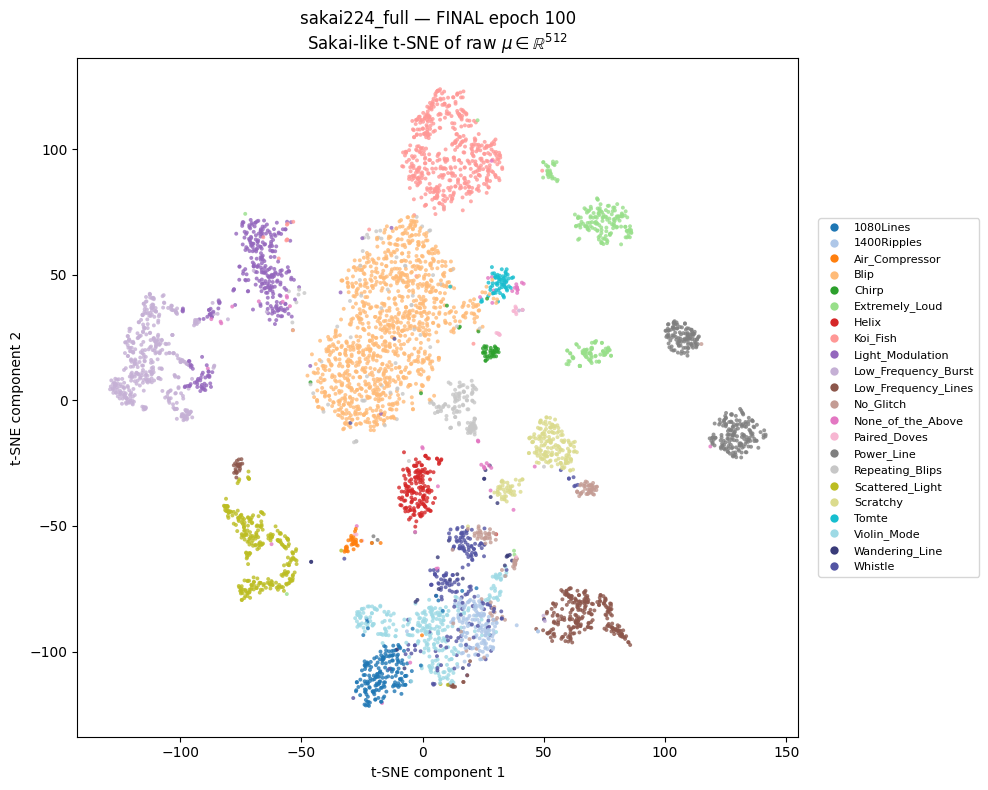


=== NOTEBOOK 04 SAKAI-LIKE t-SNE RESULT ===

INPUT_SHAPE = (8583, 512)
OUTPUT_SHAPE = (8583, 2)

CONFIG_SHA256 = 99241854054e50e0b3278ae2d4e9f9fd706c66d50738bc8113cfc7f312323b31
TSNE_FULL_SHA256_TEMP = c5068a43156337c645171e54fe052764aadfcbd24d43c3f4af8f8c7e2f48a2eb

MAX_ITERATIONS_PAPER = 5000
ACTUAL_ITERATIONS = 4999
FINAL_KL_DIVERGENCE = 1.3495911359786987
ELAPSED_SECONDS = 324.852412708

PLOT_SAMPLE_COUNT = 5150
ACTUAL_PLOT_RATE = 0.600023301875801
PLOT_INDICES_SHA256 = 1208be023c93ca7b125dc8178d00af582d974787331847f0c566a632a89fd38a

LABELS_USED_AS_TSNE_INPUT = False
PCA_APPLIED = False
STANDARDIZATION_APPLIED = False
CLUSTERING_EXECUTED = False
OFFICIAL_DRIVE_ARTIFACTS_MODIFIED = False

TSNE_NUMERIC_GATE = True
PLOT_SELECTION_GATE = True
LABEL_ORDER_GATE = True
LOCAL_ROUNDTRIP_GATE = True

NOTEBOOK_04_SAKAI_LIKE_TSNE_PASS = True


In [15]:
# ============================================================
# NOTEBOOK 04 — RUN FROZEN SAKAI-LIKE t-SNE
# STEP 04-A6b2
#
# Fit:
#   all 8583 x 512 raw mu features
#
# Plot:
#   deterministic label-blind 60% subset
#
# LOCAL outputs only.
# No Drive publication yet.
# ============================================================

from pathlib import Path

import hashlib
import json
import time

import matplotlib.pyplot as plt
import numpy as np

from matplotlib.lines import Line2D
from sklearn.manifold import TSNE
from threadpoolctl import threadpool_limits


# ============================================================
# LOCAL OUTPUT DIRECTORY
# ============================================================

LOCAL_TSNE_DIR = (
    LOCAL_POSTTRAIN_ROOT
    / "tsne_sakai_like_v1"
)

LOCAL_TSNE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# LABEL ORDER
#
# Used only for the legend.
# ============================================================

SAKAI_FIGS1_LABEL_ORDER = [
    "1080Lines",
    "1400Ripples",
    "Air_Compressor",
    "Blip",
    "Chirp",
    "Extremely_Loud",
    "Helix",
    "Koi_Fish",
    "Light_Modulation",
    "Low_Frequency_Burst",
    "Low_Frequency_Lines",
    "No_Glitch",
    "None_of_the_Above",
    "Paired_Doves",
    "Power_Line",
    "Repeating_Blips",
    "Scattered_Light",
    "Scratchy",
    "Tomte",
    "Violin_Mode",
    "Wandering_Line",
    "Whistle",
]


label_order_gate = (
    set(SAKAI_FIGS1_LABEL_ORDER)
    == set(
        np.unique(
            full_labels
        ).tolist()
    )

    and len(
        SAKAI_FIGS1_LABEL_ORDER
    ) == 22
)


assert label_order_gate


# ============================================================
# FROZEN t-SNE
# ============================================================

tsne_model = TSNE(
    n_components=2,
    perplexity=30.0,
    early_exaggeration=12.0,
    learning_rate=200.0,
    max_iter=5000,
    n_iter_without_progress=300,
    min_grad_norm=1.0e-7,
    metric="euclidean",
    init="random",
    verbose=1,
    random_state=136,
    method="barnes_hut",
    angle=0.5,
    n_jobs=1,
)


print(
    "Running frozen Sakai-like t-SNE..."
)


tsne_start = time.perf_counter()


with threadpool_limits(
    limits=1
):

    tsne_full = (
        tsne_model.fit_transform(
            full_mu
        )
    )


tsne_elapsed_seconds = (
    time.perf_counter()
    - tsne_start
)


# ============================================================
# CANONICAL RESULT
# ============================================================

tsne_full = np.asarray(
    tsne_full,
    dtype=np.float32,
    order="C",
)


tsne_numeric_gate = (
    tsne_full.shape
    == (8583, 2)

    and tsne_full.dtype
    == np.float32

    and np.isfinite(
        tsne_full
    ).all()
)


assert tsne_numeric_gate


TSNE_FULL_SHA256 = (
    hashlib.sha256(
        tsne_full.tobytes(
            order="C"
        )
    ).hexdigest()
)


# ============================================================
# LABEL-BLIND 60% SUBSET FOR PLOTTING
# ============================================================

plot_rng = np.random.RandomState(
    136
)


plot_permutation = (
    plot_rng.permutation(
        8583
    )
)


plot_indices = np.asarray(
    plot_permutation[:5150],
    dtype=np.int64,
)


plot_selection_gate = (
    plot_indices.shape
    == (5150,)

    and len(
        np.unique(
            plot_indices
        )
    ) == 5150

    and int(
        plot_indices.min()
    ) >= 0

    and int(
        plot_indices.max()
    ) < 8583
)


assert plot_selection_gate


PLOT_INDICES_SHA256 = (
    hashlib.sha256(
        plot_indices.astype(
            "<i8",
            copy=False,
        ).tobytes(
            order="C"
        )
    ).hexdigest()
)


actual_plot_rate = (
    len(plot_indices)
    / 8583.0
)


# ============================================================
# PROJECT PALETTE
# ============================================================

tab20 = list(
    plt.get_cmap(
        "tab20"
    ).colors
)


tab20b = list(
    plt.get_cmap(
        "tab20b"
    ).colors
)


project_palette = (
    tab20
    + tab20b[:2]
)


assert len(
    project_palette
) == 22


label_to_color = {
    label:
        project_palette[index]

    for index, label
    in enumerate(
        SAKAI_FIGS1_LABEL_ORDER
    )
}


plot_labels = (
    full_labels[
        plot_indices
    ]
)


plot_colors = [
    label_to_color[label]
    for label in plot_labels
]


# ============================================================
# PLOT
# ============================================================

figure, axis = plt.subplots(
    figsize=(10, 8),
)


axis.scatter(
    tsne_full[
        plot_indices,
        0
    ],
    tsne_full[
        plot_indices,
        1
    ],
    c=plot_colors,
    s=8.0,
    alpha=0.80,
    edgecolors="none",
)


axis.set_xlabel(
    "t-SNE component 1"
)

axis.set_ylabel(
    "t-SNE component 2"
)


axis.set_title(
    (
        "sakai224_full — FINAL epoch 100\n"
        "Sakai-like t-SNE of raw "
        "$\\mu\\in\\mathbb{R}^{512}$"
    )
)


legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markersize=6,
        markerfacecolor=(
            label_to_color[label]
        ),
        markeredgecolor="none",
        label=label,
    )

    for label
    in SAKAI_FIGS1_LABEL_ORDER
]


axis.legend(
    handles=legend_handles,
    loc="center left",
    bbox_to_anchor=(
        1.02,
        0.5,
    ),
    fontsize=8,
    frameon=True,
)


figure.tight_layout()


TSNE_FIGURE_PATH = (
    LOCAL_TSNE_DIR
    / "sakai224_full_mu_epoch100_tsne_sakai_like.png"
)


figure.savefig(
    TSNE_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
    facecolor="white",
)


plt.show()

plt.close(
    figure
)


# ============================================================
# TEMPORARY LOCAL NUMERIC OUTPUT
# ============================================================

TSNE_FULL_BIN_PATH = (
    LOCAL_TSNE_DIR
    / "tsne_full_f32.bin"
)


tsne_full.astype(
    "<f4",
    copy=False,
).tofile(
    TSNE_FULL_BIN_PATH
)


PLOT_INDICES_PATH = (
    LOCAL_TSNE_DIR
    / "plot_manifest_indices_i64.bin"
)


plot_indices.astype(
    "<i8",
    copy=False,
).tofile(
    PLOT_INDICES_PATH
)


# ============================================================
# ROUNDTRIP
# ============================================================

tsne_roundtrip = np.fromfile(
    TSNE_FULL_BIN_PATH,
    dtype="<f4",
).reshape(
    8583,
    2,
)


plot_roundtrip = np.fromfile(
    PLOT_INDICES_PATH,
    dtype="<i8",
)


local_roundtrip_gate = (
    np.array_equal(
        tsne_roundtrip,
        tsne_full
    )

    and np.array_equal(
        plot_roundtrip,
        plot_indices
    )
)


assert local_roundtrip_gate


# ============================================================
# RESULT
# ============================================================

actual_iterations = int(
    tsne_model.n_iter_
)


final_kl_divergence = float(
    tsne_model.kl_divergence_
)


result_gate = (
    tsne_numeric_gate
    and plot_selection_gate
    and label_order_gate
    and local_roundtrip_gate
    and np.isfinite(
        final_kl_divergence
    )
)


assert result_gate


print()
print(
    "=== NOTEBOOK 04 SAKAI-LIKE t-SNE RESULT ==="
)

print()

print(
    "INPUT_SHAPE =",
    full_mu.shape,
)

print(
    "OUTPUT_SHAPE =",
    tsne_full.shape,
)

print()

print(
    "CONFIG_SHA256 =",
    SAKAI_TSNE_CONFIG_SHA256,
)

print(
    "TSNE_FULL_SHA256_TEMP =",
    TSNE_FULL_SHA256,
)

print()

print(
    "MAX_ITERATIONS_PAPER =",
    5000,
)

print(
    "ACTUAL_ITERATIONS =",
    actual_iterations,
)

print(
    "FINAL_KL_DIVERGENCE =",
    final_kl_divergence,
)

print(
    "ELAPSED_SECONDS =",
    tsne_elapsed_seconds,
)

print()

print(
    "PLOT_SAMPLE_COUNT =",
    len(
        plot_indices
    ),
)

print(
    "ACTUAL_PLOT_RATE =",
    actual_plot_rate,
)

print(
    "PLOT_INDICES_SHA256 =",
    PLOT_INDICES_SHA256,
)

print()

print(
    "LABELS_USED_AS_TSNE_INPUT =",
    False,
)

print(
    "PCA_APPLIED =",
    False,
)

print(
    "STANDARDIZATION_APPLIED =",
    False,
)

print(
    "CLUSTERING_EXECUTED =",
    False,
)

print(
    "OFFICIAL_DRIVE_ARTIFACTS_MODIFIED =",
    False,
)

print()

print(
    "TSNE_NUMERIC_GATE =",
    tsne_numeric_gate,
)

print(
    "PLOT_SELECTION_GATE =",
    plot_selection_gate,
)

print(
    "LABEL_ORDER_GATE =",
    label_order_gate,
)

print(
    "LOCAL_ROUNDTRIP_GATE =",
    local_roundtrip_gate,
)

print()

print(
    "NOTEBOOK_04_SAKAI_LIKE_TSNE_PASS =",
    result_gate,
)

### Interpretazione metodologica della visualizzazione

Le coordinate t-SNE sono state calcolate esclusivamente dagli embedding VAE:

$$
Y_{\mathrm{tSNE}}
=
h(M_\mu),
\qquad
M_\mu\in\mathbb{R}^{8583\times512}.
$$

Le label Gravity Spy non hanno partecipato al fit t-SNE e sono state
associate ai punti soltanto dopo il calcolo, esclusivamente per la
colorazione del grafico.

La figura rappresenta quindi una visualizzazione a posteriori delle feature
apprese dal VAE, non il risultato della classificazione IIC.

Nel presente notebook non vengono eseguiti:

$$
\mathrm{IIC},
\qquad
\mathrm{over\text{-}clustering},
\qquad
K\text{ classificatori},
\qquad
\mathrm{spectral\ clustering}.
$$

Questi metodi appartengono ad analisi downstream separate; la visualizzazione
t-SNE non costituisce clustering o classificazione quantitativa. La separazione
visibile tra diversi colori suggerisce una struttura label-correlata dello
spazio latente, ma non costituisce una misura di accuracy, purity o qualità del
clustering finale.

Nell’esecuzione salvata, la console riporta `after 5000 iterations`, mentre
l’attributo `n_iter_` vale `4999`; non viene attribuita una causa a questa
differenza osservata.

Lo SHA-256 delle coordinate identifica l’artifact pubblicato. Non implica
riproducibilità bitwise tra piattaforme o versioni: NumPy, SciPy, BLAS e
hardware possono influire sulla riesecuzione numerica.

Il confronto con eventuali classi prodotte dalla pipeline IIC e con la matrice
di contingenza appartiene alla valutazione downstream, coerentemente con il
ruolo assegnato al t-SNE nel Supplemental Material di Sakai et al.

## STEP 04-A6c — Pubblicazione degli artefatti post-training

Il Notebook 04 ha completato l'analisi del VAE `FINAL` dopo 100 epoche.

Gli embedding canonici sono già pubblicati separatamente come:

$$
M_{\mu}^{\mathrm{train}}
\in
\mathbb{R}^{6866\times512},
$$

$$
M_{\mu}^{\mathrm{validation}}
\in
\mathbb{R}^{1717\times512}.
$$

Questo step pubblica invece gli artefatti diagnostici e visuali prodotti
durante il post-training:

1. ricostruzioni rappresentative input–decoder;
2. ricostruzioni dei casi estremi selezionati senza label;
3. diagnostica numerica delle 1.717 ricostruzioni di validation;
4. diagnostica delle 512 dimensioni latenti;
5. coordinate t-SNE complete;
6. sottoinsieme label-blind dei punti mostrati;
7. configurazione PAPER / PROJECT del t-SNE;
8. figura t-SNE colorata a posteriori tramite le label Gravity Spy.

Le coordinate t-SNE derivano esclusivamente da:

$$
M_\mu
\in
\mathbb{R}^{8583\times512}
$$

tramite:

$$
Y_{\mathrm{tSNE}}
=
h(M_\mu)
\in
\mathbb{R}^{8583\times2}.
$$

Le label Gravity Spy non hanno partecipato al fit t-SNE.

La figura colorata costituisce una visualizzazione a posteriori delle feature
del VAE e non rappresenta il risultato della classificazione IIC o
del clustering finale.

Tutti gli artefatti vengono accompagnati da SHA-256 e pubblicati
atomicamente nello storage persistente configurato da `PROJECT_ROOT`.

In [16]:
# ============================================================
# NOTEBOOK 04 — FINAL POST-TRAINING ARTIFACT PUBLICATION
# STEP 04-A6c
#
# Persistent scientific write.
#
# Publishes:
#   reconstruction figures
#   extreme-case figures
#   reconstruction diagnostics
#   latent diagnostics
#   t-SNE coordinates
#   t-SNE plot subset
#   t-SNE config
#   t-SNE figure
#
# Does NOT duplicate the canonical mu embedding binaries.
# Those remain in the dedicated embeddings artifact.
# ============================================================

from pathlib import Path

import hashlib
import json
import os
import shutil

import matplotlib.pyplot as plt


# ============================================================
# OUTPUT CONTRACT
# ============================================================

POSTTRAINING_ARTIFACT_ID = (
    "sakai224_full_posttraining_epoch100_v1"
)

POSTTRAINING_ROOT = (
    SAKAI224_ROOT
    / "posttraining"
)

FINAL_POSTTRAINING_DIR = (
    POSTTRAINING_ROOT
    / POSTTRAINING_ARTIFACT_ID
)

PARTIAL_POSTTRAINING_DIR = (
    POSTTRAINING_ROOT
    / (
        POSTTRAINING_ARTIFACT_ID
        + ".partial"
    )
)


RECON_DIR = (
    PARTIAL_POSTTRAINING_DIR
    / "reconstructions"
)

DIAGNOSTICS_DIR = (
    PARTIAL_POSTTRAINING_DIR
    / "diagnostics"
)

TSNE_DIR = (
    PARTIAL_POSTTRAINING_DIR
    / "tsne"
)


# ============================================================
# DO NOT OVERWRITE AN EXISTING SCIENTIFIC PUBLICATION
# ============================================================

POSTTRAINING_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


if FINAL_POSTTRAINING_DIR.exists():

    raise RuntimeError(
        "STOP: post-training artifact already exists: "
        f"{FINAL_POSTTRAINING_DIR}"
    )


if PARTIAL_POSTTRAINING_DIR.exists():

    shutil.rmtree(
        PARTIAL_POSTTRAINING_DIR
    )


RECON_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

DIAGNOSTICS_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

TSNE_DIR.mkdir(
    parents=True,
    exist_ok=False,
)


# ============================================================
# REQUIRED PRECONDITIONS
# ============================================================

assert TSNE_FIGURE_PATH.is_file()
assert TSNE_FULL_BIN_PATH.is_file()
assert PLOT_INDICES_PATH.is_file()

assert FULL_RECON_DIAGNOSTIC_CSV.is_file()
assert LATENT_DIAGNOSTIC_CSV.is_file()

assert len(
    reconstruction_figure_paths
) == 4

assert all(
    path.is_file()
    for path
    in reconstruction_figure_paths
)


# ============================================================
# COPY THE FOUR REPRESENTATIVE RECONSTRUCTION FIGURES
# ============================================================

for source_path in reconstruction_figure_paths:

    shutil.copy2(
        source_path,
        RECON_DIR
        / source_path.name,
    )


# ============================================================
# REGENERATE AND SAVE EXTREME-CASE FIGURES
#
# Same data and same [0,1] visual scale used in A4d.
# ============================================================

DURATIONS = [
    "0.5 s",
    "1.0 s",
    "2.0 s",
    "4.0 s",
]


def save_extreme_group(
    samples,
    inputs,
    reconstructions,
    diagnostic_selection,
    *,
    title,
    diagnostic_field,
    destination,
):

    figure, axes = plt.subplots(
        nrows=4,
        ncols=8,
        figsize=(20, 11),
        constrained_layout=True,
    )


    for row_index in range(4):

        sample = samples[
            row_index
        ]

        diagnostic_row = (
            diagnostic_selection[
                row_index
            ]
        )


        for channel_index in range(4):

            ax_input = axes[
                row_index,
                channel_index
            ]

            ax_input.imshow(
                inputs[
                    row_index,
                    channel_index
                ],
                cmap="gray",
                vmin=0.0,
                vmax=1.0,
                origin="upper",
                interpolation="nearest",
                aspect="auto",
            )

            ax_input.set_xticks([])
            ax_input.set_yticks([])


            ax_recon = axes[
                row_index,
                channel_index + 4
            ]

            ax_recon.imshow(
                reconstructions[
                    row_index,
                    channel_index
                ],
                cmap="gray",
                vmin=0.0,
                vmax=1.0,
                origin="upper",
                interpolation="nearest",
                aspect="auto",
            )

            ax_recon.set_xticks([])
            ax_recon.set_yticks([])


        axes[
            row_index,
            0
        ].set_ylabel(
            (
                f"split_pos={sample['split_pos']}\n"
                f"{sample['event_id']}\n"
                f"label={sample['label']}\n"
                f"{diagnostic_field}="
                f"{diagnostic_row[diagnostic_field]:.4f}"
            ),
            fontsize=8,
        )


    for channel_index, duration in enumerate(
        DURATIONS
    ):

        axes[
            0,
            channel_index
        ].set_title(
            f"INPUT\n{duration}"
        )

        axes[
            0,
            channel_index + 4
        ].set_title(
            f"RECON z=mu\n{duration}"
        )


    figure.suptitle(
        title,
        fontsize=14,
    )


    figure.savefig(
        destination,
        dpi=200,
        bbox_inches="tight",
        facecolor="white",
    )


    plt.close(
        figure
    )


LOW_CORRELATION_FIGURE = (
    RECON_DIR
    / "lowest_correlation_cases_epoch100.png"
)


HIGH_BCE_FIGURE = (
    RECON_DIR
    / "highest_bce_cases_epoch100.png"
)


save_extreme_group(
    low_corr_samples,
    low_corr_inputs,
    low_corr_reconstructions,
    LOW_CORRELATION_SELECTION,

    title=(
        "FINAL epoch 100 — "
        "4 lowest input/reconstruction correlations"
    ),

    diagnostic_field=
        "pearson_correlation",

    destination=
        LOW_CORRELATION_FIGURE,
)


save_extreme_group(
    high_bce_samples,
    high_bce_inputs,
    high_bce_reconstructions,
    HIGH_BCE_SELECTION,

    title=(
        "FINAL epoch 100 — "
        "4 highest BCE/value cases"
    ),

    diagnostic_field=
        "bce_per_value",

    destination=
        HIGH_BCE_FIGURE,
)


# ============================================================
# COPY NUMERIC DIAGNOSTICS
# ============================================================

shutil.copy2(
    FULL_RECON_DIAGNOSTIC_CSV,
    DIAGNOSTICS_DIR
    / FULL_RECON_DIAGNOSTIC_CSV.name,
)


shutil.copy2(
    LATENT_DIAGNOSTIC_CSV,
    DIAGNOSTICS_DIR
    / LATENT_DIAGNOSTIC_CSV.name,
)


# ============================================================
# COPY t-SNE NUMERIC + VISUAL OUTPUTS
# ============================================================

shutil.copy2(
    TSNE_FIGURE_PATH,
    TSNE_DIR
    / TSNE_FIGURE_PATH.name,
)


shutil.copy2(
    TSNE_FULL_BIN_PATH,
    TSNE_DIR
    / "tsne_full_f32.bin",
)


shutil.copy2(
    PLOT_INDICES_PATH,
    TSNE_DIR
    / "plot_manifest_indices_i64.bin",
)


# ============================================================
# WRITE FROZEN t-SNE CONFIG
# ============================================================

TSNE_CONFIG_PUBLIC_PATH = (
    TSNE_DIR
    / "tsne_config.json"
)


with TSNE_CONFIG_PUBLIC_PATH.open(
    "w",
    encoding="utf-8",
    newline="\n",
) as handle:

    json.dump(
        SAKAI_TSNE_CONFIG,
        handle,
        indent=2,
        sort_keys=True,
        ensure_ascii=True,
    )

    handle.write(
        "\n"
    )


# ============================================================
# METADATA
# ============================================================

POSTTRAINING_METADATA_PATH = (
    PARTIAL_POSTTRAINING_DIR
    / "metadata.json"
)


posttraining_metadata = {

    "artifact_format_version":
        1,

    "artifact_id":
        POSTTRAINING_ARTIFACT_ID,

    "experiment":
        "sakai224_full",

    "source_run_id":
        "sakai224_full_v1",

    "source_checkpoint":
        "final.pt",

    "source_completed_epochs":
        100,

    "source_last_completed_epoch":
        99,

    "source_optimizer_step":
        5400,

    "source_model_state_sha256":
        EXPECTED_FINAL_MODEL_STATE_SHA256,

    "canonical_embedding_artifact":
        "sakai224_full_mu_epoch100_v1",

    "latent_dim":
        512,

    "train_embedding_sha256":
        EXPECTED_TRAIN_MU_SHA256,

    "validation_embedding_sha256":
        EXPECTED_VALIDATION_MU_SHA256,

    "tsne_input_rows":
        8583,

    "tsne_input_dimensions":
        512,

    "tsne_output_dimensions":
        2,

    "tsne_input_manifest_order_sha256":
        full_mu_manifest_order_sha256,

    "tsne_config_sha256":
        SAKAI_TSNE_CONFIG_SHA256,

    "tsne_result_sha256":
        TSNE_FULL_SHA256,

    "tsne_plot_indices_sha256":
        PLOT_INDICES_SHA256,

    "tsne_actual_iterations":
        int(
            actual_iterations
        ),

    "tsne_final_kl_divergence":
        float(
            final_kl_divergence
        ),

    "tsne_plot_sample_count":
        int(
            len(
                plot_indices
            )
        ),

    "tsne_actual_plot_rate":
        float(
            actual_plot_rate
        ),

    "labels_used_as_tsne_input":
        False,

    "labels_used_for_tsne_color_only":
        True,

    "pca_applied":
        False,

    "standardization_applied":
        False,

    "clustering_completed":
        False,

    "iic_completed":
        False,

    "spectral_clustering_completed":
        False,

    "scientific_role":
        (
            "post-training VAE diagnostics and "
            "preliminary Sakai-like feature visualization"
        ),
}


with POSTTRAINING_METADATA_PATH.open(
    "w",
    encoding="utf-8",
    newline="\n",
) as handle:

    json.dump(
        posttraining_metadata,
        handle,
        indent=2,
        sort_keys=True,
        ensure_ascii=True,
    )

    handle.write(
        "\n"
    )


# ============================================================
# HASH ALL PUBLISHED FILES
# ============================================================

def file_sha256(
    path,
):

    digest = hashlib.sha256()

    with Path(path).open(
        "rb"
    ) as handle:

        while True:

            block = handle.read(
                8 * 1024 * 1024
            )

            if not block:
                break

            digest.update(
                block
            )

    return digest.hexdigest()


files_before_sha_manifest = sorted(
    [
        path
        for path
        in PARTIAL_POSTTRAINING_DIR.rglob("*")
        if path.is_file()
    ],
    key=lambda path:
        path.relative_to(
            PARTIAL_POSTTRAINING_DIR
        ).as_posix(),
)


published_hashes = {}


for path in files_before_sha_manifest:

    relative_path = (
        path.relative_to(
            PARTIAL_POSTTRAINING_DIR
        ).as_posix()
    )


    published_hashes[
        relative_path
    ] = file_sha256(
        path
    )


SHA256SUMS_PATH = (
    PARTIAL_POSTTRAINING_DIR
    / "SHA256SUMS.txt"
)


with SHA256SUMS_PATH.open(
    "w",
    encoding="ascii",
    newline="\n",
) as handle:

    for relative_path in sorted(
        published_hashes
    ):

        handle.write(
            (
                f"{published_hashes[relative_path]}"
                f"  {relative_path}\n"
            )
        )


SHA256SUMS_SHA256 = file_sha256(
    SHA256SUMS_PATH
)


# ============================================================
# CONTENT CONTRACT
# ============================================================

required_relative_files = {

    "metadata.json",

    "SHA256SUMS.txt",

    (
        "diagnostics/"
        "validation_reconstruction_diagnostics_epoch100.csv"
    ),

    (
        "diagnostics/"
        "latent_dimension_diagnostics_epoch100.csv"
    ),

    "reconstructions/lowest_correlation_cases_epoch100.png",

    "reconstructions/highest_bce_cases_epoch100.png",

    "tsne/tsne_full_f32.bin",

    "tsne/plot_manifest_indices_i64.bin",

    "tsne/tsne_config.json",

    (
        "tsne/"
        "sakai224_full_mu_epoch100_tsne_sakai_like.png"
    ),
}


actual_relative_files = {
    path.relative_to(
        PARTIAL_POSTTRAINING_DIR
    ).as_posix()

    for path
    in PARTIAL_POSTTRAINING_DIR.rglob("*")

    if path.is_file()
}


# Four representative reconstruction figures must also exist.
representative_recon_files = {
    (
        "reconstructions/"
        + path.name
    )

    for path
    in reconstruction_figure_paths
}


content_gate = (
    required_relative_files.issubset(
        actual_relative_files
    )

    and representative_recon_files.issubset(
        actual_relative_files
    )
)


assert content_gate


# ============================================================
# IMPORTANT NUMERIC FILE IDENTITIES
# ============================================================

tsne_binary_public_sha = (
    file_sha256(
        TSNE_DIR
        / "tsne_full_f32.bin"
    )
)


plot_indices_public_sha = (
    file_sha256(
        TSNE_DIR
        / "plot_manifest_indices_i64.bin"
    )
)


numeric_identity_gate = (
    tsne_binary_public_sha
        == TSNE_FULL_SHA256

    and plot_indices_public_sha
        == PLOT_INDICES_SHA256
)


assert numeric_identity_gate


# ============================================================
# MODEL STILL FINAL
# ============================================================

model_state_publication_gate = (
    canonical_tree_sha256(
        official_final_model.state_dict()
    )
    == EXPECTED_FINAL_MODEL_STATE_SHA256
)


assert model_state_publication_gate


# ============================================================
# ATOMIC PUBLICATION
# ============================================================

os.replace(
    PARTIAL_POSTTRAINING_DIR,
    FINAL_POSTTRAINING_DIR,
)


publication_gate = (
    FINAL_POSTTRAINING_DIR.is_dir()

    and not PARTIAL_POSTTRAINING_DIR.exists()
)


assert publication_gate


# ============================================================
# REPORT
# ============================================================

print()
print(
    "=== NOTEBOOK 04 FINAL POST-TRAINING PUBLICATION ==="
)

print()

print(
    "ARTIFACT_ID =",
    POSTTRAINING_ARTIFACT_ID,
)

print(
    "ARTIFACT_DIRECTORY =",
    FINAL_POSTTRAINING_DIR,
)

print()

print(
    "PUBLISHED_FILE_COUNT =",
    len(
        actual_relative_files
    ),
)

print()

print(
    "TSNE_COORDINATES_SHA256 =",
    tsne_binary_public_sha,
)

print(
    "TSNE_PLOT_INDICES_SHA256 =",
    plot_indices_public_sha,
)

print(
    "TSNE_CONFIG_SHA256 =",
    SAKAI_TSNE_CONFIG_SHA256,
)

print(
    "SHA256SUMS_SHA256 =",
    SHA256SUMS_SHA256,
)

print()

print(
    "CONTENT_GATE =",
    content_gate,
)

print(
    "NUMERIC_IDENTITY_GATE =",
    numeric_identity_gate,
)

print(
    "MODEL_STATE_PUBLICATION_GATE =",
    model_state_publication_gate,
)

print(
    "PUBLICATION_GATE =",
    publication_gate,
)

print()

print(
    "EMBEDDINGS_DUPLICATED =",
    False,
)

print(
    "LABELS_USED_AS_TSNE_INPUT =",
    False,
)

print(
    "CLUSTERING_COMPLETED =",
    False,
)

print(
    "IIC_COMPLETED =",
    False,
)

print()

print(
    "NOTEBOOK_04_POSTTRAINING_ARTIFACT_PUBLISHED =",
    (
        content_gate
        and numeric_identity_gate
        and model_state_publication_gate
        and publication_gate
    ),
)


=== NOTEBOOK 04 FINAL POST-TRAINING PUBLICATION ===

ARTIFACT_ID = sakai224_full_posttraining_epoch100_v1
ARTIFACT_DIRECTORY = /content/drive/MyDrive/TESI_SAKAI2022/sakai224_full/posttraining/sakai224_full_posttraining_epoch100_v1

PUBLISHED_FILE_COUNT = 14

TSNE_COORDINATES_SHA256 = c5068a43156337c645171e54fe052764aadfcbd24d43c3f4af8f8c7e2f48a2eb
TSNE_PLOT_INDICES_SHA256 = 1208be023c93ca7b125dc8178d00af582d974787331847f0c566a632a89fd38a
TSNE_CONFIG_SHA256 = 99241854054e50e0b3278ae2d4e9f9fd706c66d50738bc8113cfc7f312323b31
SHA256SUMS_SHA256 = 47c062e1d2383cae3a0e1ff023a9f32af98251341d6b65711dd99d43c87ceae3

CONTENT_GATE = True
NUMERIC_IDENTITY_GATE = True
MODEL_STATE_PUBLICATION_GATE = True
PUBLICATION_GATE = True

EMBEDDINGS_DUPLICATED = False
LABELS_USED_AS_TSNE_INPUT = False
CLUSTERING_COMPLETED = False
IIC_COMPLETED = False

NOTEBOOK_04_POSTTRAINING_ARTIFACT_PUBLISHED = True
